In [5]:
import torch
from torch import nn, optim
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

batch_size = 256

trainset = datasets.MNIST("./dataset/", train = True, transform = transforms.ToTensor(), download = True)
#dataloader = torch.utils.data.DataLoader(trainset, batch_size = batch_size, shuffle = True, num_workers = 2)

testset = datasets.MNIST("./dataset/", train = False, transform = transforms.ToTensor(), download =   True)
#testloader = torch.utils.data.DataLoader(testset, batch_size = batch_size, shuffle = False, num_workers = 2)

dataset = torch.utils.data.ConcatDataset([trainset, testset])
dataloader = torch.utils.data.DataLoader(
	dataset,
	batch_size = batch_size,
	shuffle = True
)

tensor_to_img = transforms.ToPILImage()

## AdamW

### Train

In [7]:
activation_func = "AdamW_BCE"

class SAE(nn.Module):
	def __init__(self):
		super().__init__()

		self.encoder_layer_1 =  nn.Sequential(
			nn.Dropout(0.2),
			nn.Linear(28 * 28, 500),
			nn.ReLU(),
		)

		self.decoder_layer_1 =  nn.Sequential(
			nn.Dropout(0.2),
			nn.Linear(500, 28 * 28),
			nn.Sigmoid(),
		)

		self.encoder_layer_2 =  nn.Sequential(
			nn.Dropout(0.2),
			nn.Linear(500, 500),
			nn.ReLU(),
		)

		self.decoder_layer_2 =  nn.Sequential(
			nn.Dropout(0.2),
			nn.Linear(500, 500),
			nn.ReLU(),
		)

		self.encoder_layer_3 =  nn.Sequential(
			nn.Dropout(0.2),
			nn.Linear(500, 2000),
			nn.ReLU(),
		)

		self.decoder_layer_3 =  nn.Sequential(
			nn.Dropout(0.2),
			nn.Linear(2000, 500),
			nn.ReLU(),
		)

		self.encoder_layer_4 =  nn.Sequential(
			nn.Dropout(0.2),
			nn.Linear(2000, 10),
		)

		self.decoder_layer_4 =  nn.Sequential(
			nn.Dropout(0.2),
			nn.Linear(10, 2000),
			nn.ReLU(),
		)

	def forward(self, x):
		encoded = self.encoder_layer_4(
					self.encoder_layer_3(
						self.encoder_layer_2(
							self.encoder_layer_1(x)
						)
					)
				)

		decoded = self.decoder_layer_1(
					self.decoder_layer_2(
						self.decoder_layer_3(
							self.decoder_layer_4(encoded)
						)
					)
				)
		return decoded
	
	def encode(self, x):
		e1 = self.encoder_layer_1(x)
		e2 = self.encoder_layer_2(e1)
		e3 = self.encoder_layer_3(e2)
		z = self.encoder_layer_4(e3)
		return z

In [ ]:
model = SAE()
model.to(device)

# Pretraining
pretrain_epochs = 200

# Pretrain layer 1

loss_function = nn.BCELoss()

optimizer = optim.AdamW(
	list(model.encoder_layer_1.parameters()) + 
	list(model.decoder_layer_1.parameters()),
	lr = 1e-3, 
	weight_decay = 1e-4
	)

scheduler = optim.lr_scheduler.StepLR(
	optimizer, 
	step_size = 20000, #Amount of iterations the scheduler will update the lr
	gamma = 0.5 #by how much the scheduler will divide the current lr
	)

best_loss = (float("inf"), 0)

model.train()
for epoch in range(pretrain_epochs):
	batch_losses = []
	
	for images, _ in dataloader:

		images = torch.flatten(images, start_dim = 1).to(device)
		e1 = model.encoder_layer_1(images)
		e1_reconstructed = model.decoder_layer_1(e1)
		loss = loss_function(e1_reconstructed, images)

		optimizer.zero_grad()
		loss.backward()
		optimizer.step()

		scheduler.step()

		batch_losses.append(loss.item())
	
	epoch_loss = sum(batch_losses) / len(batch_losses)

	print(f"Pretrain 1: Epoch {epoch+1}/{pretrain_epochs}, Loss: {epoch_loss:.6f}")

	if epoch_loss <= best_loss[0]:
		best_loss = (epoch_loss, epoch + 1)
		torch.save(model.state_dict(), "./models/" + activation_func + "/pre1")

		print(f"Best Pretrain 1 Epoch: {best_loss[1]}/{pretrain_epochs}, Loss: {best_loss[0]:.6f}")

# Pretrain layer 2

model.load_state_dict(torch.load("./models/" + activation_func + "/pre1", weights_only = True))

loss_function = nn.MSELoss()

optimizer = optim.AdamW(
	list(model.encoder_layer_2.parameters()) + 
	list(model.decoder_layer_2.parameters()),
	lr = 1e-3, 
	weight_decay = 1e-4
	)

scheduler = optim.lr_scheduler.StepLR(
	optimizer, 
	step_size = 20000, #Amount of iterations the scheduler will update the lr
	gamma = 0.5 #by how much the scheduler will divide the current lr
	)

best_loss = (float("inf"), 0)

# Deactivate Dropout because Layer is Frozen
model.encoder_layer_1.eval()

for epoch in range(pretrain_epochs):
	batch_losses = []

	for images, _ in dataloader:

		images = torch.flatten(images, start_dim = 1).to(device)

		with torch.no_grad():
			e1 = model.encoder_layer_1(images)
		
		e2 = model.encoder_layer_2(e1)
		e1_reconstructed = model.decoder_layer_2(e2)

		loss = loss_function(e1_reconstructed, e1)

		optimizer.zero_grad()
		loss.backward()
		optimizer.step()

		scheduler.step()

		batch_losses.append(loss.item())
	
	epoch_loss = sum(batch_losses) / len(batch_losses)

	print(f"Pretrain 2: Epoch {epoch+1}/{pretrain_epochs}, Loss: {epoch_loss:.6f}")

	if epoch_loss <= best_loss[0]:
		best_loss = (epoch_loss, epoch + 1)
		torch.save(model.state_dict(), "./models/" + activation_func + "/pre2")

		print(f"Best Pretrain 2 Epoch: {best_loss[1]}/{pretrain_epochs}, Loss: {best_loss[0]:.6f}")


# Pretrain layer 3

model.load_state_dict(torch.load("./models/" + activation_func + "/pre2", weights_only = True))

loss_function = nn.MSELoss()

optimizer = optim.AdamW(
	list(model.encoder_layer_3.parameters()) + 
	list(model.decoder_layer_3.parameters()),
	lr = 1e-3, 
	weight_decay = 1e-4
	)

scheduler = optim.lr_scheduler.StepLR(
	optimizer, 
	step_size = 20000, #Amount of iterations the scheduler will update the lr
	gamma = 0.5 #by how much the scheduler will divide the current lr
	)

best_loss = (float("inf"), 0)

# Deactivate Dropout because Layer is Frozen
model.encoder_layer_1.eval()
model.encoder_layer_2.eval()

for epoch in range(pretrain_epochs):
	batch_losses = []

	for images, _ in dataloader:

		images = torch.flatten(images, start_dim = 1).to(device)

		with torch.no_grad():
			e1 = model.encoder_layer_1(images)
			e2 = model.encoder_layer_2(e1)
		
		e3 = model.encoder_layer_3(e2)
		e2_reconstructed = model.decoder_layer_3(e3)

		loss = loss_function(e2_reconstructed, e2)

		optimizer.zero_grad()
		loss.backward()
		optimizer.step()

		scheduler.step()

		batch_losses.append(loss.item())
	
	epoch_loss = sum(batch_losses) / len(batch_losses)

	print(f"Pretrain 3: Epoch {epoch+1}/{pretrain_epochs}, Loss: {epoch_loss:.6f}")

	if epoch_loss <= best_loss[0]:
		best_loss = (epoch_loss, epoch + 1)
		torch.save(model.state_dict(), "./models/" + activation_func + "/pre3")

		print(f"Best Pretrain 3 Epoch: {best_loss[1]}/{pretrain_epochs}, Loss: {best_loss[0]:.6f}")


# Pretrain layer 4

model.load_state_dict(torch.load("./models/" + activation_func + "/pre3", weights_only = True))

loss_function = nn.MSELoss()

optimizer = optim.AdamW(
	list(model.encoder_layer_4.parameters()) + 
	list(model.decoder_layer_4.parameters()),
	lr = 1e-3, 
	weight_decay = 1e-4
	)

scheduler = optim.lr_scheduler.StepLR(
	optimizer, 
	step_size = 20000, #Amount of iterations the scheduler will update the lr
	gamma = 0.5 #by how much the scheduler will divide the current lr
	)

best_loss = (float("inf"), 0)

# Deactivate Dropout because Layer is Frozen
model.encoder_layer_1.eval()
model.encoder_layer_2.eval()
model.encoder_layer_3.eval()

for epoch in range(pretrain_epochs):
	batch_losses = []

	for images, _ in dataloader:

		images = torch.flatten(images, start_dim = 1).to(device)

		with torch.no_grad():
			e1 = model.encoder_layer_1(images)
			e2 = model.encoder_layer_2(e1)
			e3 = model.encoder_layer_3(e2)
		
		e4 = model.encoder_layer_4(e3)
		e3_reconstructed = model.decoder_layer_4(e4)

		loss = loss_function(e3_reconstructed, e3)

		optimizer.zero_grad()
		loss.backward()
		optimizer.step()

		scheduler.step()

		batch_losses.append(loss.item())
	
	epoch_loss = sum(batch_losses) / len(batch_losses)

	print(f"Pretrain 4: Epoch {epoch+1}/{pretrain_epochs}, Loss: {epoch_loss:.6f}")

	if epoch_loss <= best_loss[0]:
		best_loss = (epoch_loss, epoch + 1)
		torch.save(model.state_dict(), "./models/" + activation_func + "/pre4")

		print(f"Best Pretrain 4 Epoch: {best_loss[1]}/{pretrain_epochs}, Loss: {best_loss[0]:.6f}")
		


Pretrain 1: Epoch 1/200, Loss: 0.173613
Best Pretrain 1 Epoch: 1/200, Loss: 0.173613
Pretrain 1: Epoch 2/200, Loss: 0.107873
Best Pretrain 1 Epoch: 2/200, Loss: 0.107873
Pretrain 1: Epoch 3/200, Loss: 0.098735
Best Pretrain 1 Epoch: 3/200, Loss: 0.098735
Pretrain 1: Epoch 4/200, Loss: 0.094940
Best Pretrain 1 Epoch: 4/200, Loss: 0.094940
Pretrain 1: Epoch 5/200, Loss: 0.092811
Best Pretrain 1 Epoch: 5/200, Loss: 0.092811
Pretrain 1: Epoch 6/200, Loss: 0.091278
Best Pretrain 1 Epoch: 6/200, Loss: 0.091278
Pretrain 1: Epoch 7/200, Loss: 0.090048
Best Pretrain 1 Epoch: 7/200, Loss: 0.090048
Pretrain 1: Epoch 8/200, Loss: 0.089004
Best Pretrain 1 Epoch: 8/200, Loss: 0.089004
Pretrain 1: Epoch 9/200, Loss: 0.088118
Best Pretrain 1 Epoch: 9/200, Loss: 0.088118
Pretrain 1: Epoch 10/200, Loss: 0.087353
Best Pretrain 1 Epoch: 10/200, Loss: 0.087353
Pretrain 1: Epoch 11/200, Loss: 0.086625
Best Pretrain 1 Epoch: 11/200, Loss: 0.086625
Pretrain 1: Epoch 12/200, Loss: 0.085997
Best Pretrain 1 Epoc

In [ ]:
model.load_state_dict(torch.load("./models/" + activation_func + "/pre4", weights_only = True))

train_epochs = 400

loss_function = nn.BCELoss()

optimizer = optim.AdamW(
	model.parameters(),
	lr = 1e-3,
	weight_decay = 1e-4
	)

scheduler = optim.lr_scheduler.StepLR(
	optimizer, 
	step_size = 20000, #Amount of iterations the scheduler will update the lr
	gamma = 0.5 #by how much the scheduler will divide the current lr
	)

best_loss = (float("inf"), 0)

model.eval() # deactivate all dropout
for epoch in range(train_epochs):
	batch_losses = []
	
	for images, _ in dataloader:

		images = torch.flatten(images, start_dim = 1).to(device)
		reconstructed = model(images)
		loss = loss_function(reconstructed, images)

		optimizer.zero_grad()
		loss.backward()
		optimizer.step()

		scheduler.step()

		batch_losses.append(loss.item())
	
	epoch_loss = sum(batch_losses) / len(batch_losses)

	print(f"Finetune: Epoch {epoch+1}/{train_epochs}, Loss: {epoch_loss:.6f}")

	if epoch_loss <= best_loss[0]:
		best_loss = (epoch_loss, epoch + 1)
		torch.save(model.state_dict(), "./models/" + activation_func + "/finetuned")

		print(f"Best Finetune Epoch: {best_loss[1]}/{train_epochs}, Loss: {best_loss[0]:.6f}")

Finetune: Epoch 1/400, Loss: 0.128141
Best Finetune Epoch: 1/400, Loss: 0.128141
Finetune: Epoch 2/400, Loss: 0.107328
Best Finetune Epoch: 2/400, Loss: 0.107328
Finetune: Epoch 3/400, Loss: 0.102384
Best Finetune Epoch: 3/400, Loss: 0.102384
Finetune: Epoch 4/400, Loss: 0.099529
Best Finetune Epoch: 4/400, Loss: 0.099529
Finetune: Epoch 5/400, Loss: 0.097455
Best Finetune Epoch: 5/400, Loss: 0.097455
Finetune: Epoch 6/400, Loss: 0.095872
Best Finetune Epoch: 6/400, Loss: 0.095872
Finetune: Epoch 7/400, Loss: 0.094631
Best Finetune Epoch: 7/400, Loss: 0.094631
Finetune: Epoch 8/400, Loss: 0.093601
Best Finetune Epoch: 8/400, Loss: 0.093601
Finetune: Epoch 9/400, Loss: 0.092716
Best Finetune Epoch: 9/400, Loss: 0.092716
Finetune: Epoch 10/400, Loss: 0.091993
Best Finetune Epoch: 10/400, Loss: 0.091993
Finetune: Epoch 11/400, Loss: 0.091361
Best Finetune Epoch: 11/400, Loss: 0.091361
Finetune: Epoch 12/400, Loss: 0.090775
Best Finetune Epoch: 12/400, Loss: 0.090775
Finetune: Epoch 13/400

### Visualize

In [10]:
examples = {}

for image, label in dataset:
    label = int(label)
    if label not in examples:
        examples[label] = image

    if len(examples) == 10:
        break
    
model = SAE()
model.to(device)

SAE(
  (encoder_layer_1): Sequential(
    (0): Dropout(p=0.2, inplace=False)
    (1): Linear(in_features=784, out_features=500, bias=True)
    (2): ReLU()
  )
  (decoder_layer_1): Sequential(
    (0): Dropout(p=0.2, inplace=False)
    (1): Linear(in_features=500, out_features=784, bias=True)
    (2): Sigmoid()
  )
  (encoder_layer_2): Sequential(
    (0): Dropout(p=0.2, inplace=False)
    (1): Linear(in_features=500, out_features=500, bias=True)
    (2): ReLU()
  )
  (decoder_layer_2): Sequential(
    (0): Dropout(p=0.2, inplace=False)
    (1): Linear(in_features=500, out_features=500, bias=True)
    (2): ReLU()
  )
  (encoder_layer_3): Sequential(
    (0): Dropout(p=0.2, inplace=False)
    (1): Linear(in_features=500, out_features=2000, bias=True)
    (2): ReLU()
  )
  (decoder_layer_3): Sequential(
    (0): Dropout(p=0.2, inplace=False)
    (1): Linear(in_features=2000, out_features=500, bias=True)
    (2): ReLU()
  )
  (encoder_layer_4): Sequential(
    (0): Dropout(p=0.2, inplace=F

#### Autoencoder Layer 1


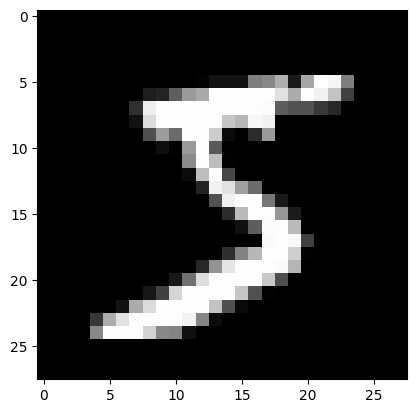

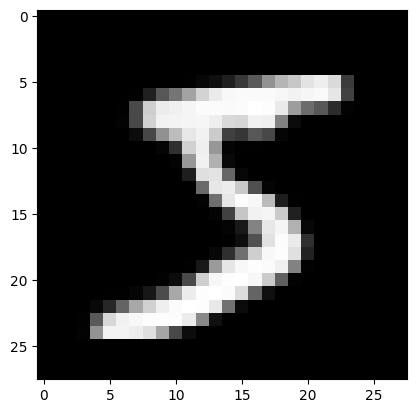

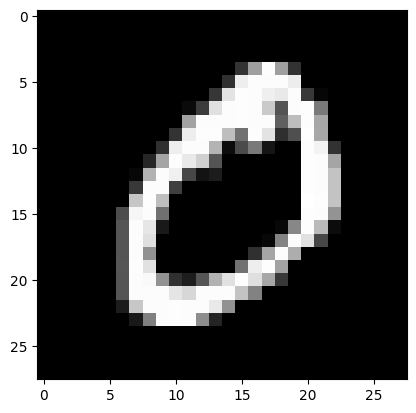

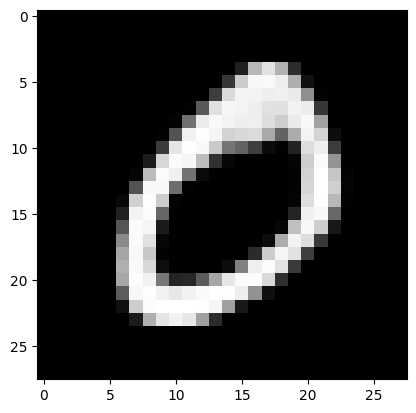

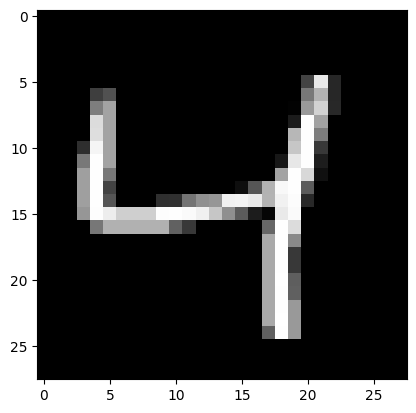

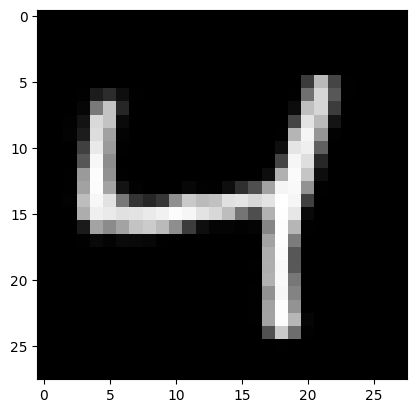

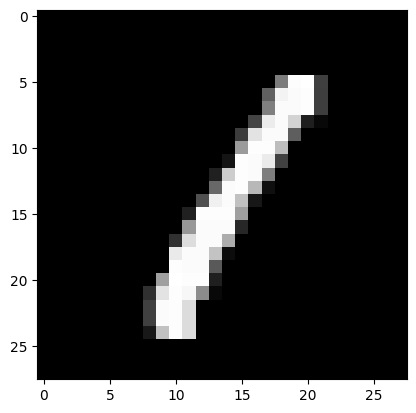

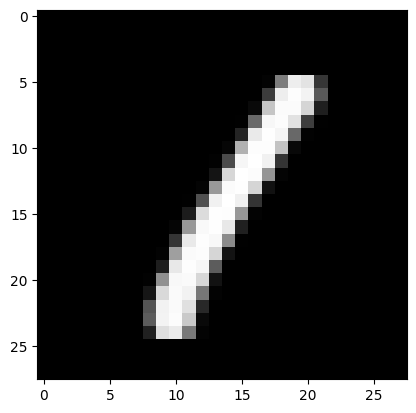

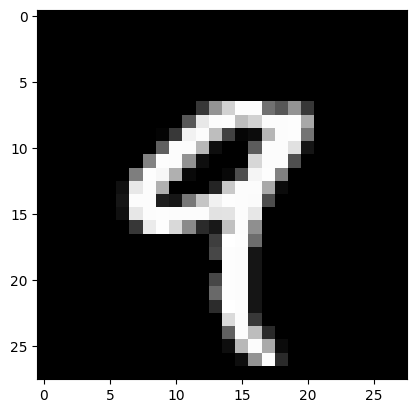

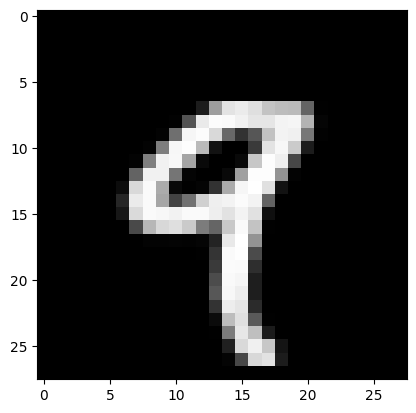

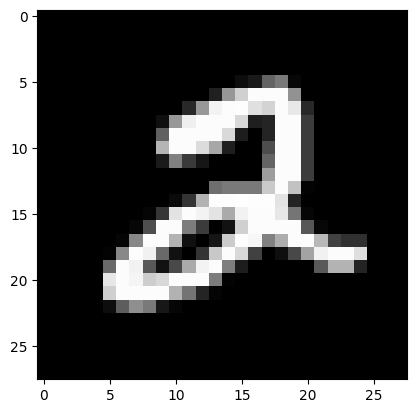

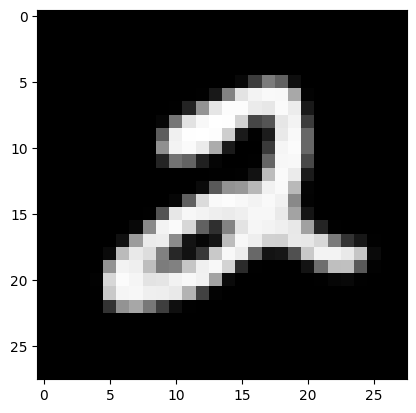

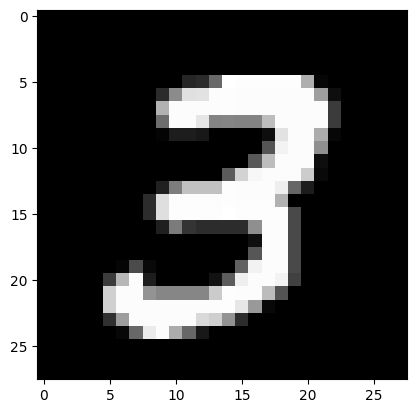

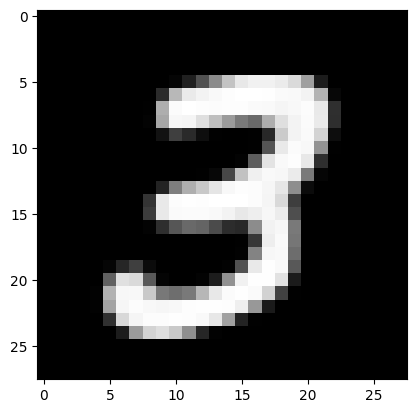

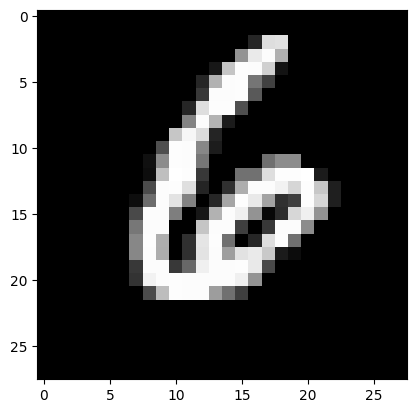

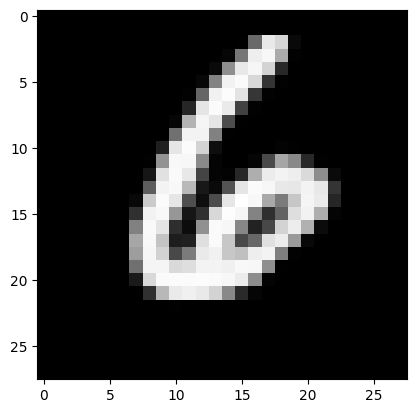

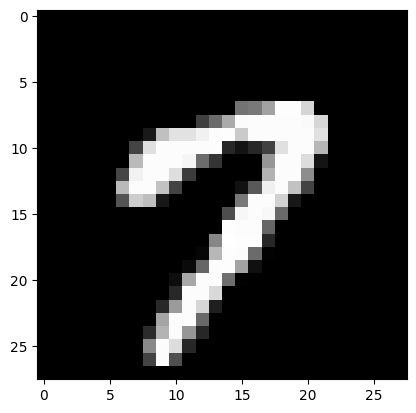

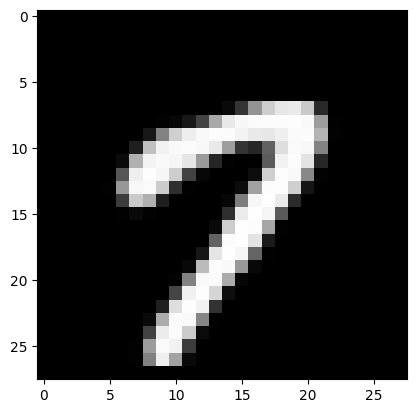

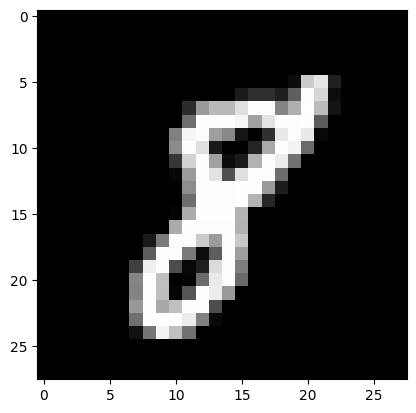

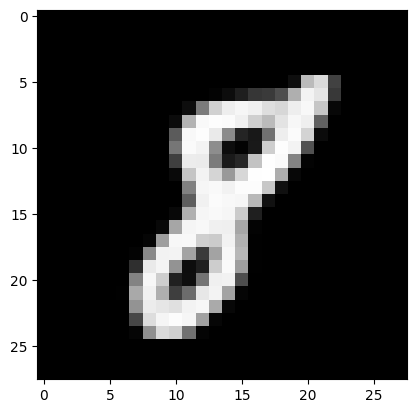

In [11]:
model.load_state_dict(torch.load("./models/" + activation_func + "/pre1", weights_only = True))
model.eval()

for digit in examples:

	image_tensor = examples[digit]
	image = tensor_to_img(image_tensor)
	imgplot = plt.imshow(image, cmap = "gray")
	plt.show()

	with torch.no_grad():
		image_tensor = torch.flatten(image_tensor).to(device)

		e1 = model.encoder_layer_1(image_tensor)
		e1_reconstructed = model.decoder_layer_1(e1)

	e1_reconstructed = torch.unflatten(e1_reconstructed, dim = 0, sizes = (28, 28)).to(device)

	image_reconstructed = tensor_to_img(e1_reconstructed)

	# To view it:
	imgplot = plt.imshow(image_reconstructed, cmap = "gray")
	plt.show()

#### Autoencoder Layer 2


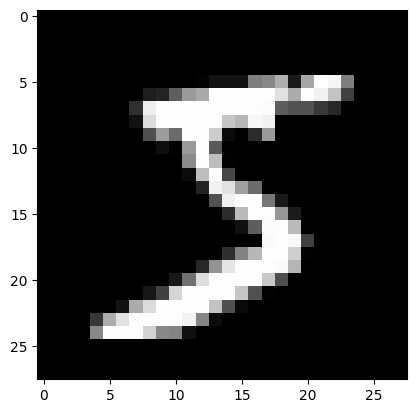

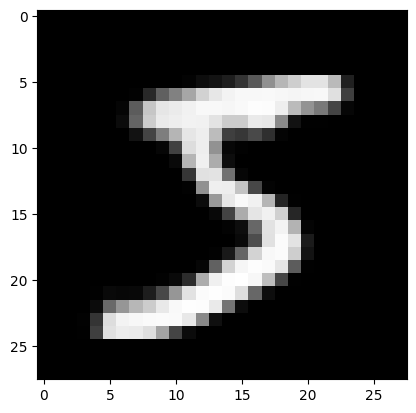

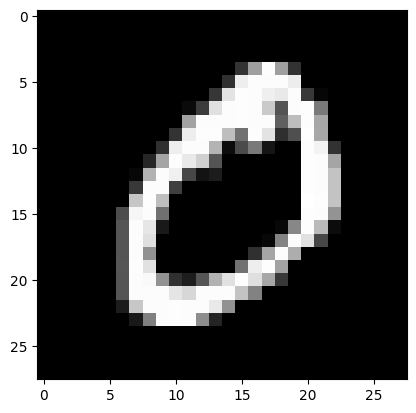

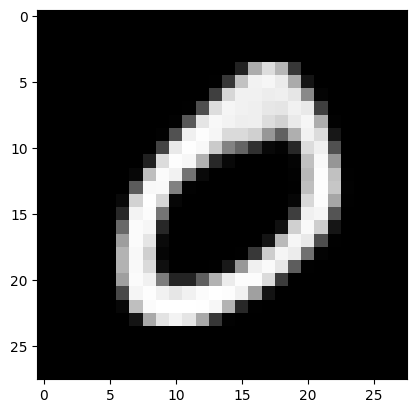

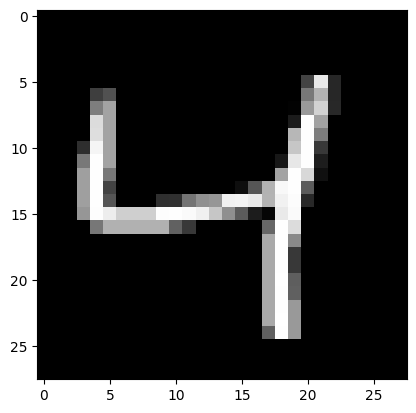

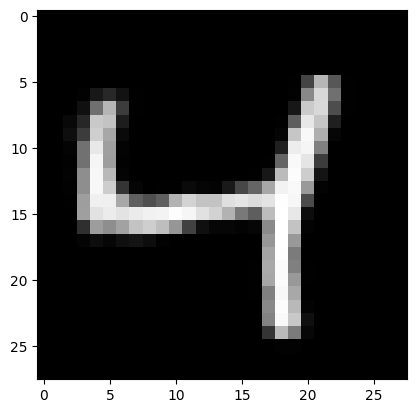

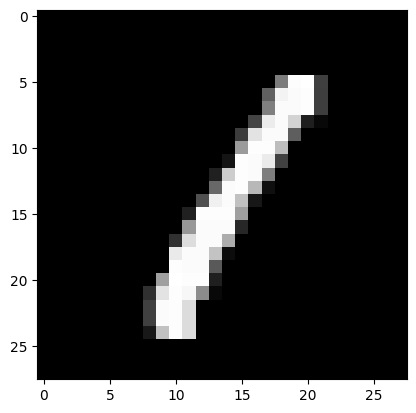

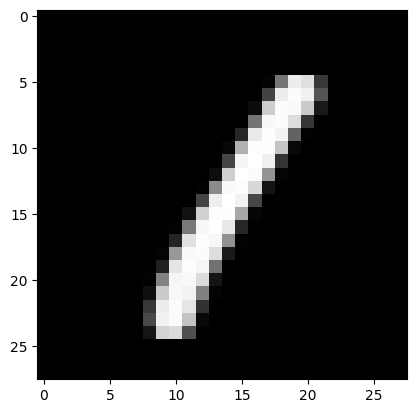

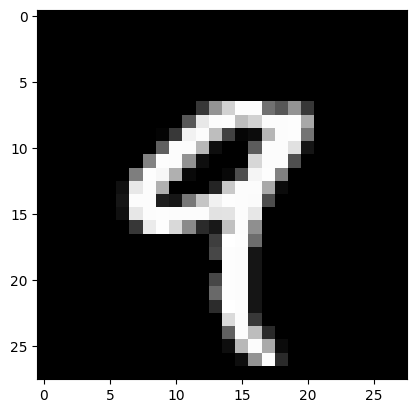

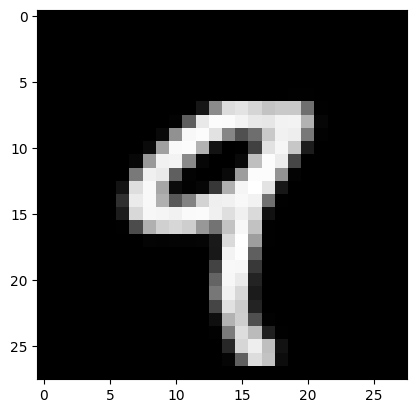

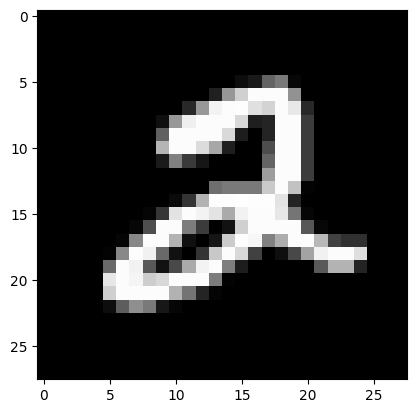

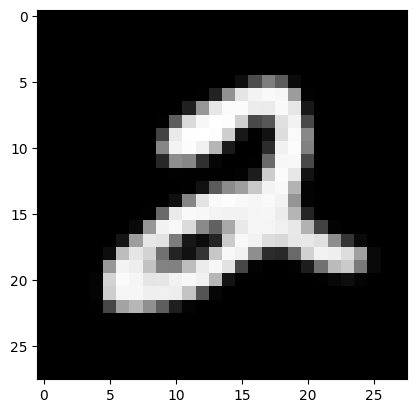

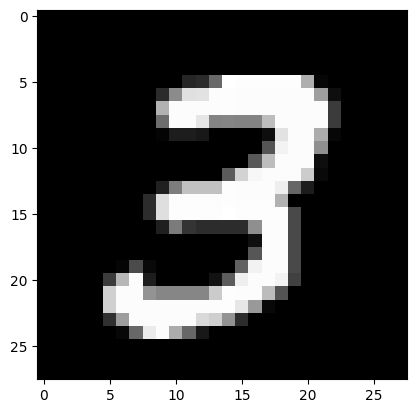

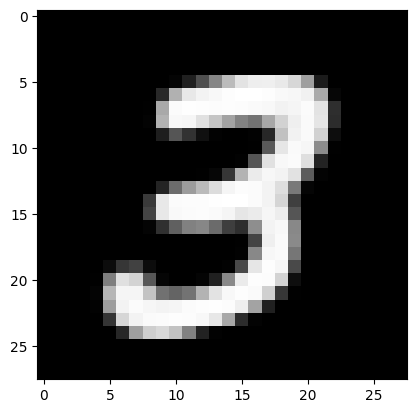

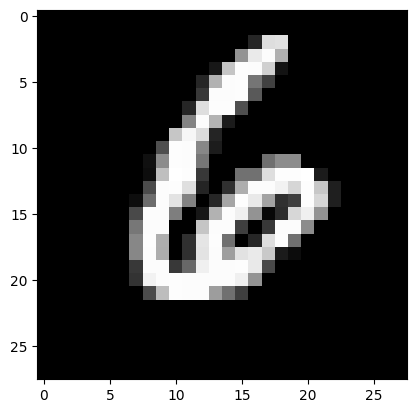

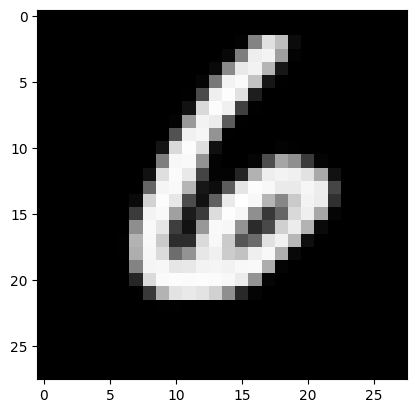

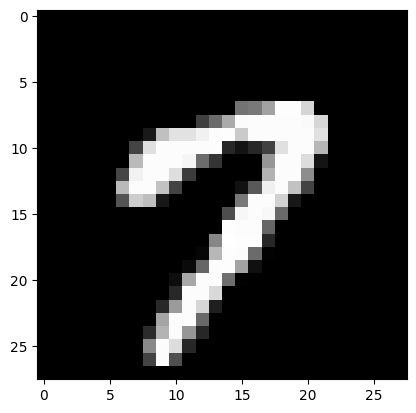

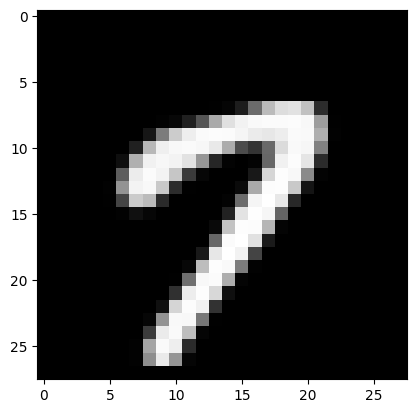

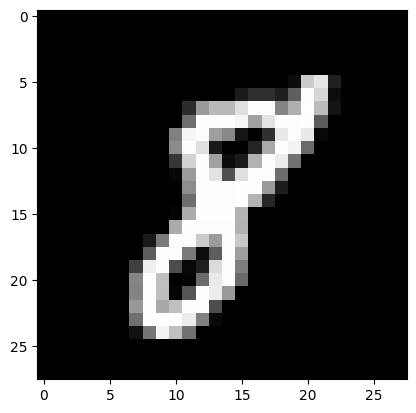

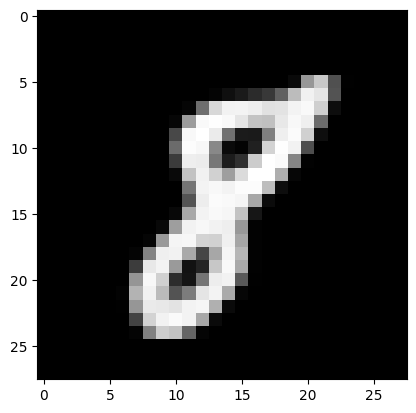

In [12]:
model.load_state_dict(torch.load("./models/" + activation_func + "/pre2", weights_only = True))
model.eval()

for digit in examples:

	image_tensor = examples[digit]
	image = tensor_to_img(image_tensor)
	imgplot = plt.imshow(image, cmap = "gray")
	plt.show()

	with torch.no_grad():
		image_tensor = torch.flatten(image_tensor).to(device)

		e1 = model.encoder_layer_1(image_tensor)
		e2 = model.encoder_layer_2(e1)

		e2_reconstructed = model.decoder_layer_2(e2)
		e1_reconstructed = model.decoder_layer_1(e2_reconstructed)

	e1_reconstructed = torch.unflatten(e1_reconstructed, dim = 0, sizes = (28, 28)).to(device)

	image_reconstructed = tensor_to_img(e1_reconstructed)

	imgplot = plt.imshow(image_reconstructed, cmap = "gray")
	plt.show()

#### Autoencoder Layer 3


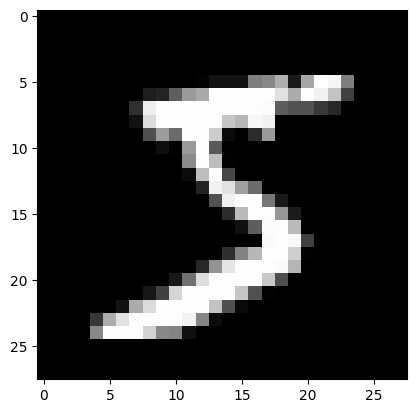

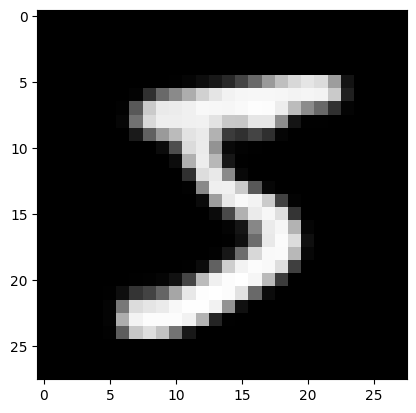

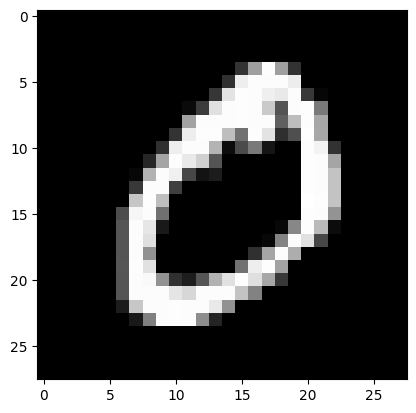

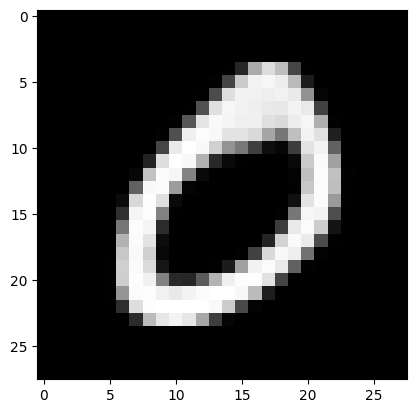

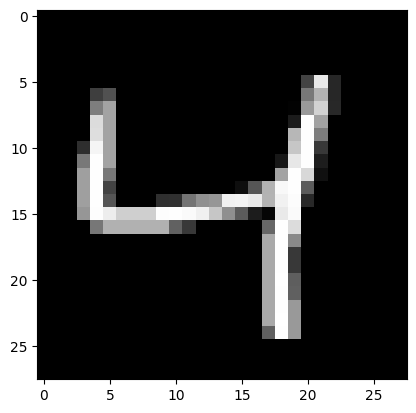

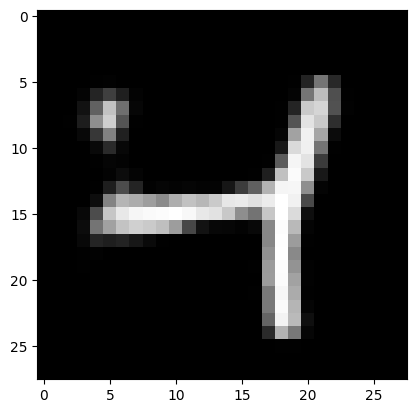

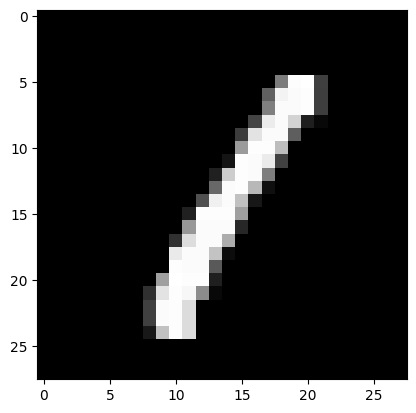

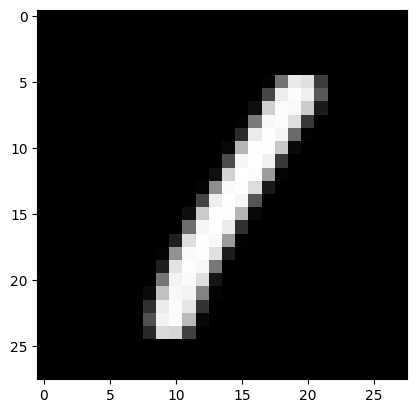

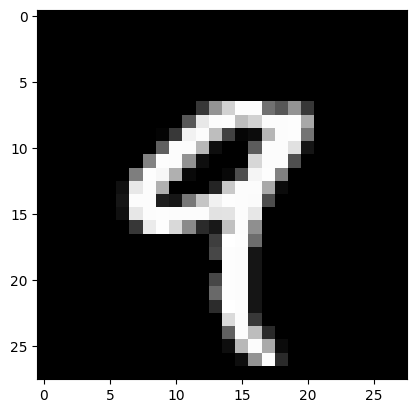

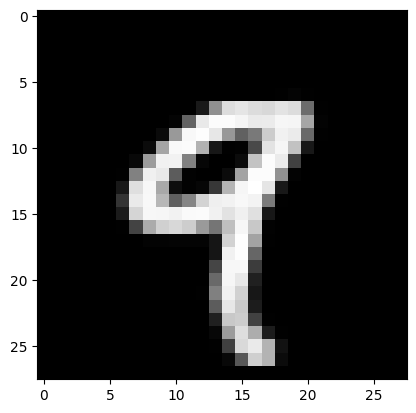

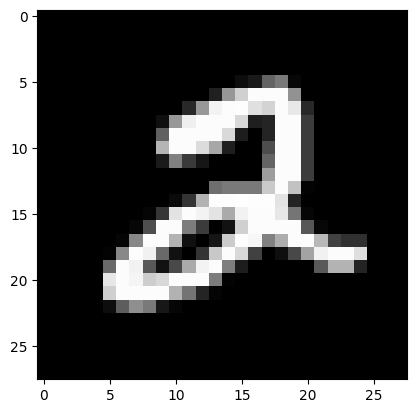

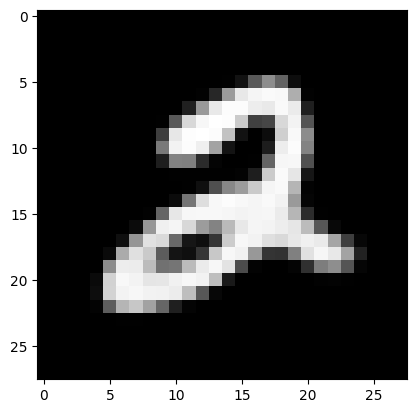

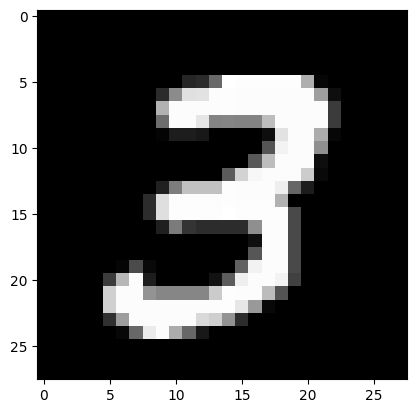

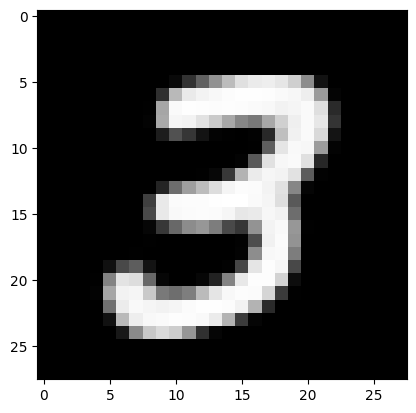

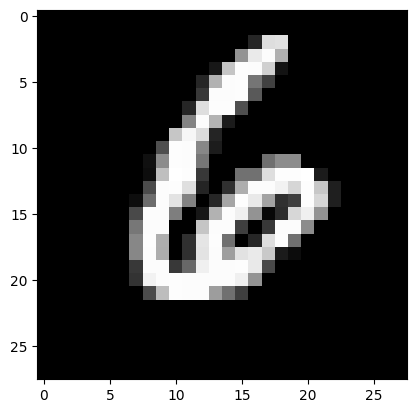

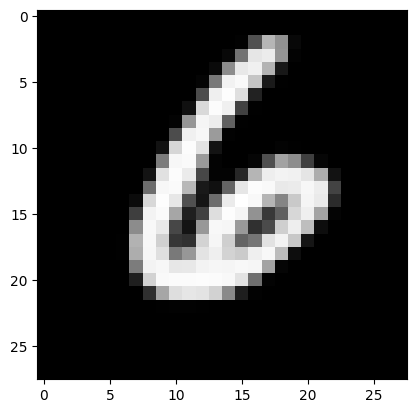

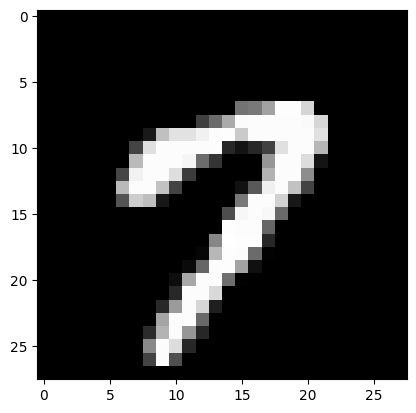

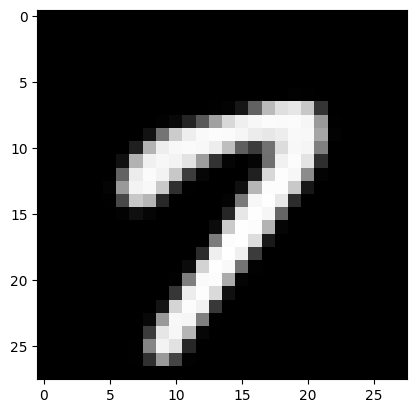

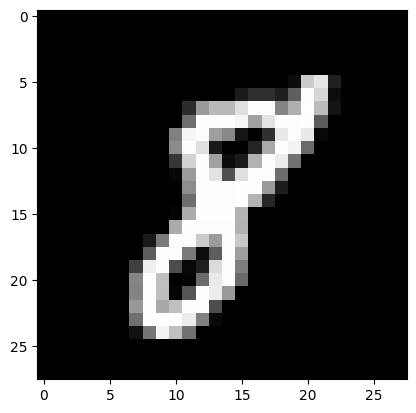

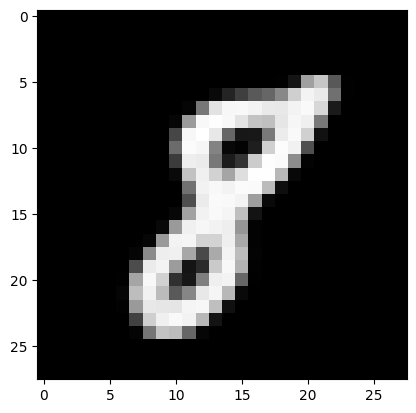

In [13]:
model.load_state_dict(torch.load("./models/" + activation_func + "/pre3", weights_only = True))
model.eval()

for digit in examples:

	image_tensor = examples[digit]
	image = tensor_to_img(image_tensor)
	imgplot = plt.imshow(image, cmap = "gray")
	plt.show()

	with torch.no_grad():
		image_tensor = torch.flatten(image_tensor).to(device)

		e1 = model.encoder_layer_1(image_tensor)
		e2 = model.encoder_layer_2(e1)
		e3 = model.encoder_layer_3(e2)

		e3_reconstructed = model.decoder_layer_3(e3)
		e2_reconstructed = model.decoder_layer_2(e3_reconstructed)
		e1_reconstructed = model.decoder_layer_1(e2_reconstructed)

	e1_reconstructed = torch.unflatten(e1_reconstructed, dim = 0, sizes = (28, 28)).to(device)

	image_reconstructed = tensor_to_img(e1_reconstructed)

	imgplot = plt.imshow(image_reconstructed, cmap = "gray")
	plt.show()

#### Autoencoder Layer 4


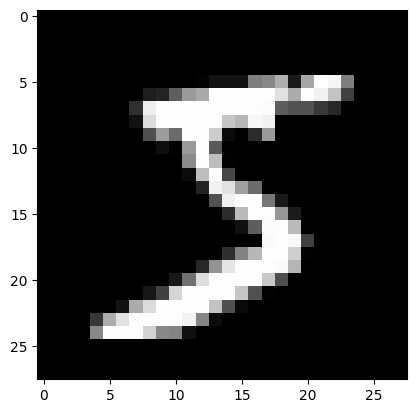

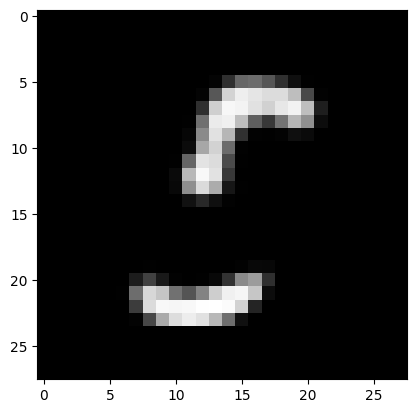

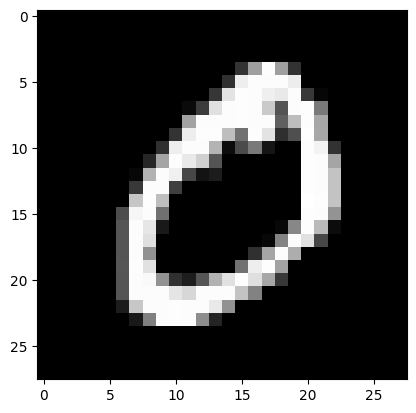

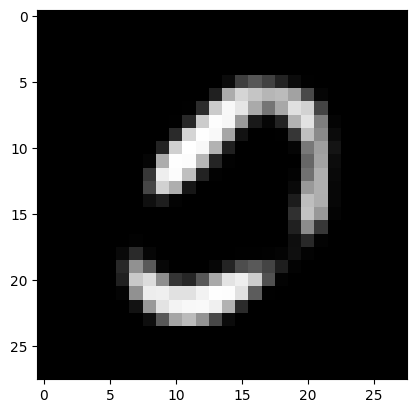

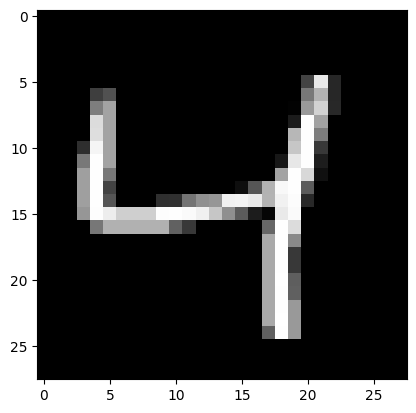

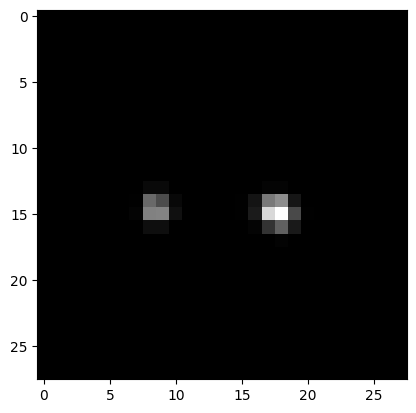

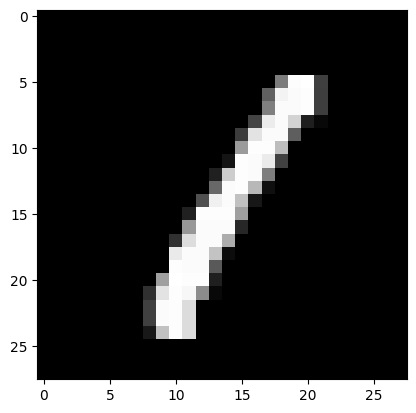

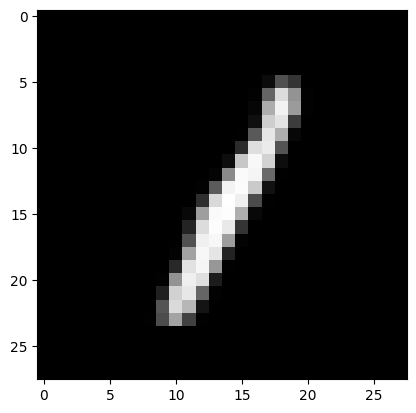

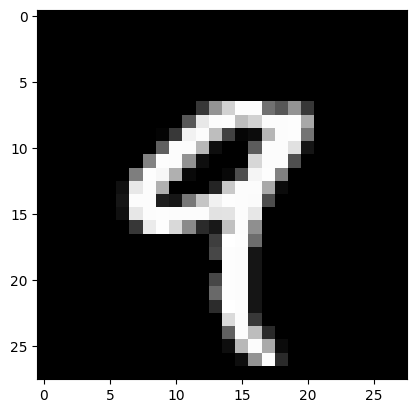

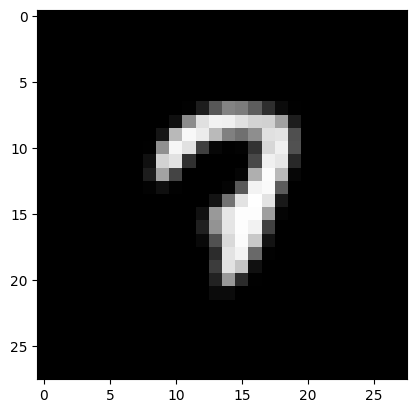

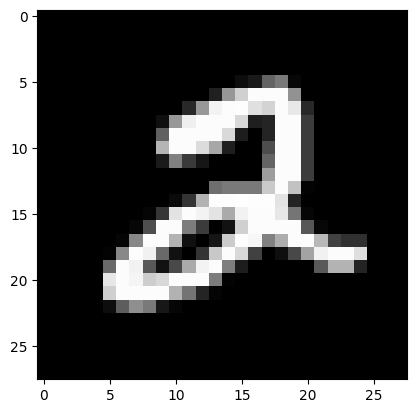

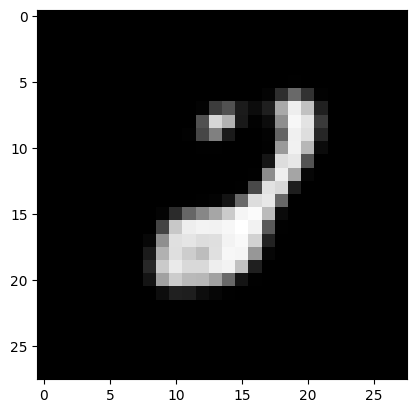

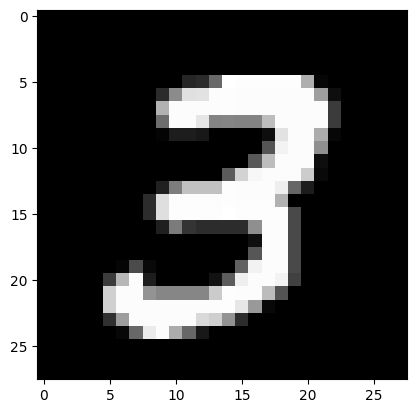

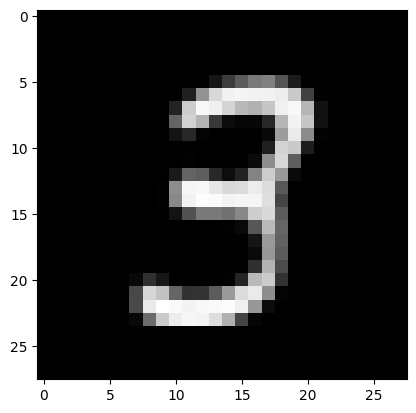

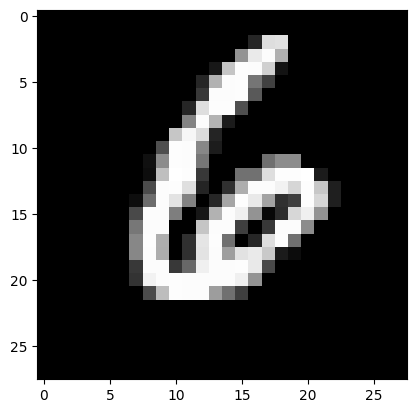

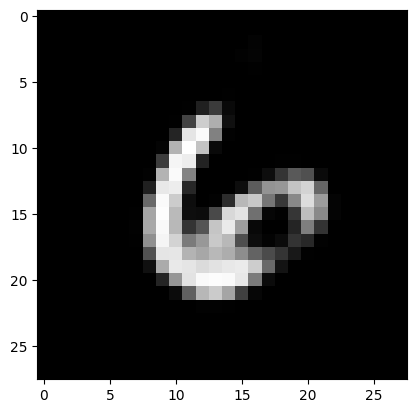

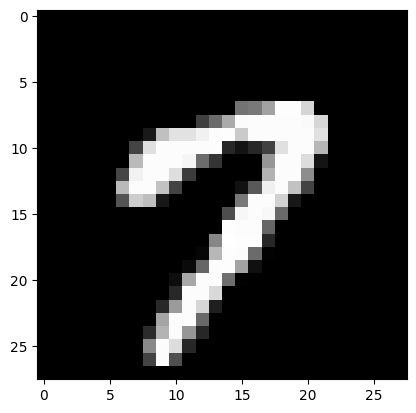

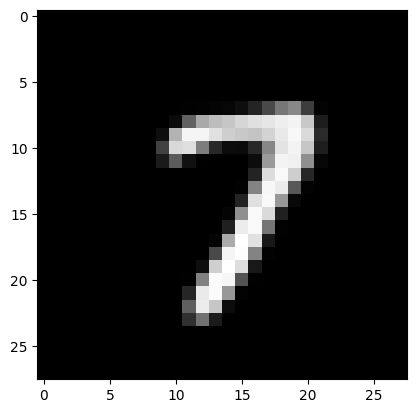

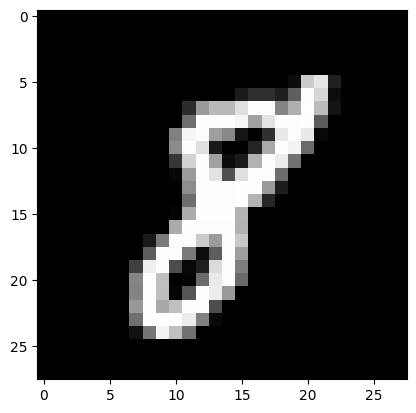

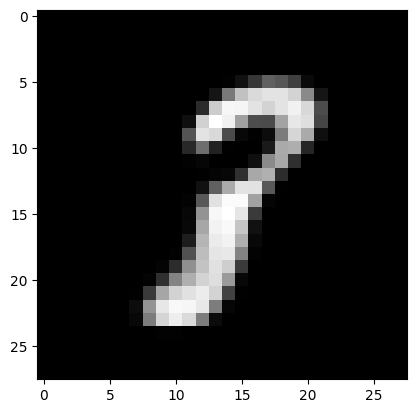

In [14]:
model.load_state_dict(torch.load("./models/" + activation_func + "/pre4", weights_only = True))
model.eval()

for digit in examples:

	image_tensor = examples[digit]
	image = tensor_to_img(image_tensor)
	imgplot = plt.imshow(image, cmap = "gray")
	plt.show()

	with torch.no_grad():
		image_tensor = torch.flatten(image_tensor).to(device)

		e1 = model.encoder_layer_1(image_tensor)
		e2 = model.encoder_layer_2(e1)
		e3 = model.encoder_layer_3(e2)
		e4 = model.encoder_layer_4(e3)

		e4_reconstructed = model.decoder_layer_4(e4)
		e3_reconstructed = model.decoder_layer_3(e4_reconstructed)
		e2_reconstructed = model.decoder_layer_2(e3_reconstructed)
		e1_reconstructed = model.decoder_layer_1(e2_reconstructed)

	e1_reconstructed = torch.unflatten(e1_reconstructed, dim = 0, sizes = (28, 28)).to(device)

	image_reconstructed = tensor_to_img(e1_reconstructed)

	imgplot = plt.imshow(image_reconstructed, cmap = "gray")
	plt.show()

#### Finetuned

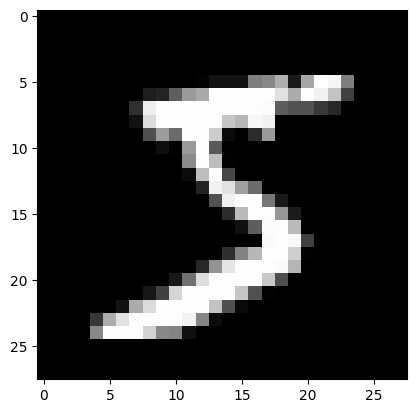

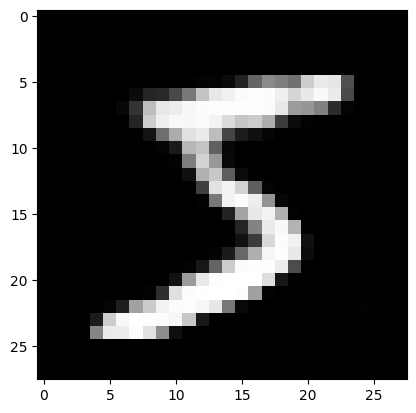

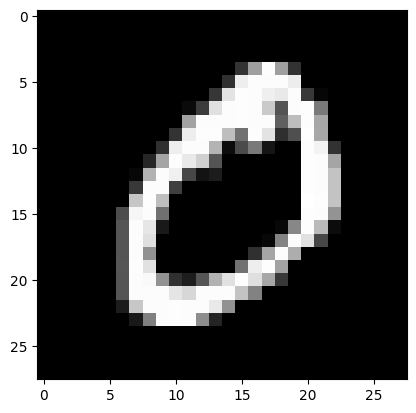

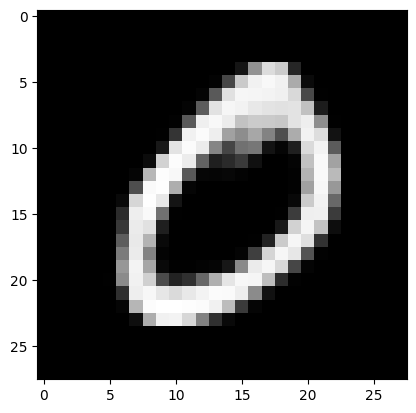

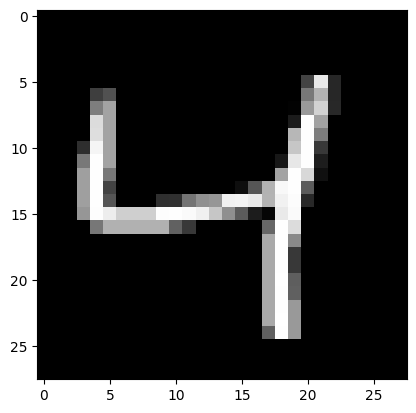

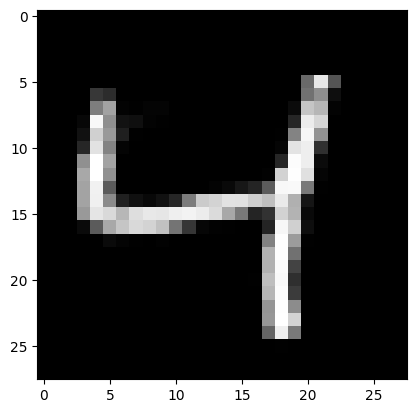

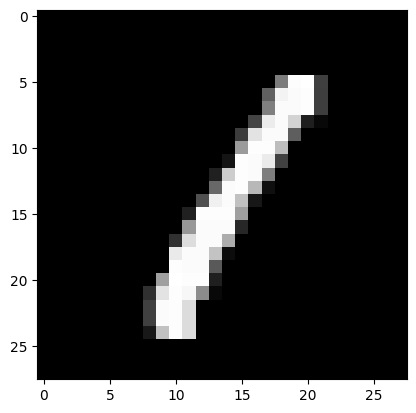

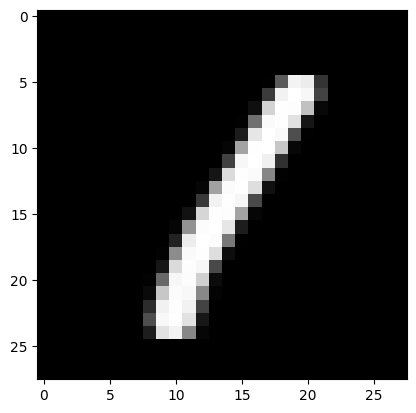

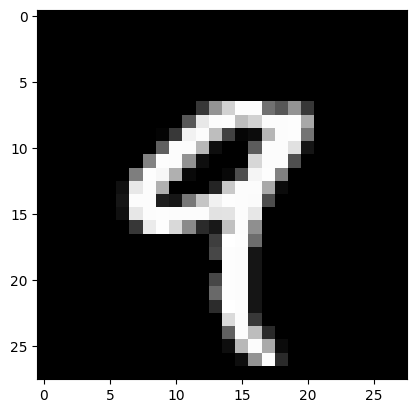

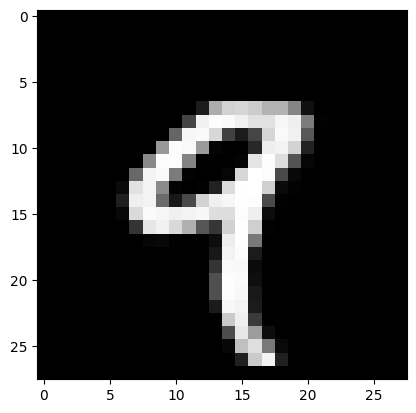

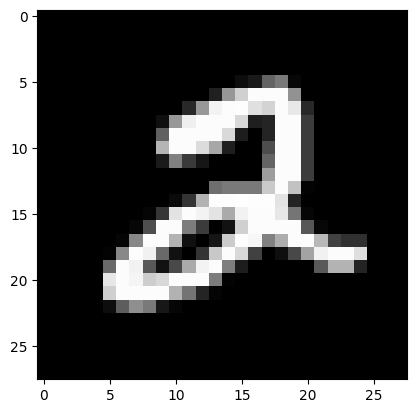

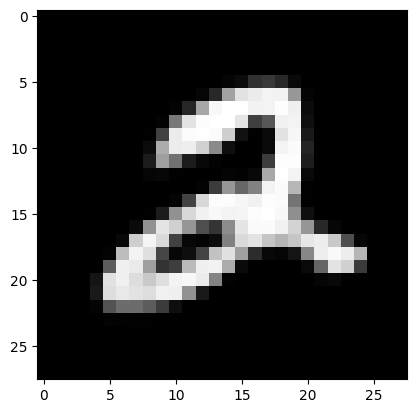

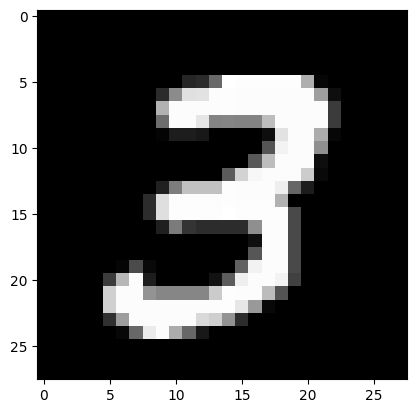

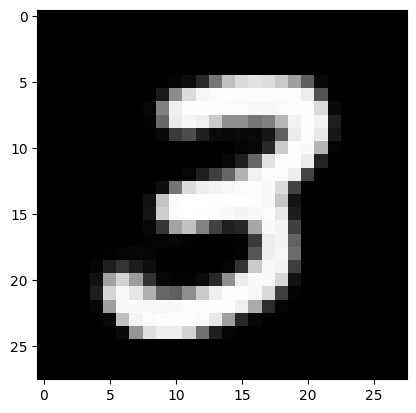

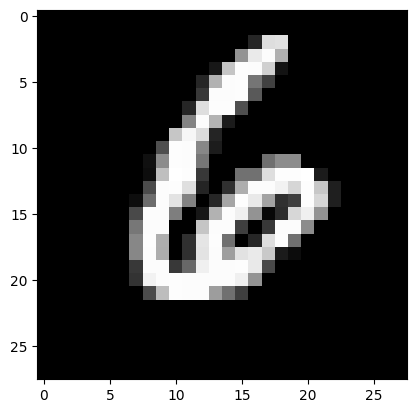

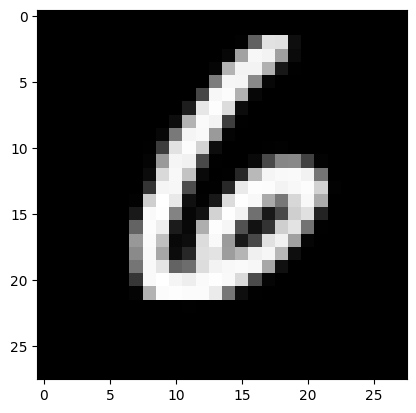

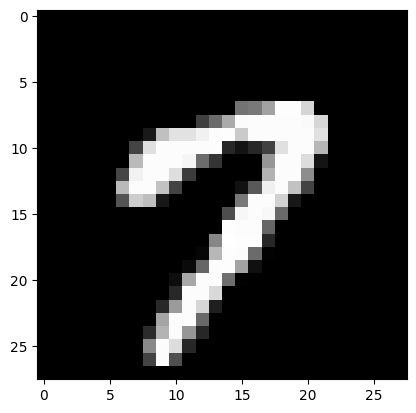

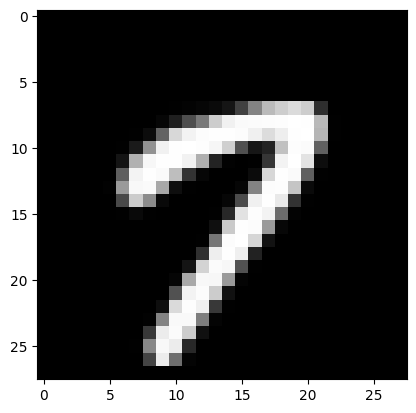

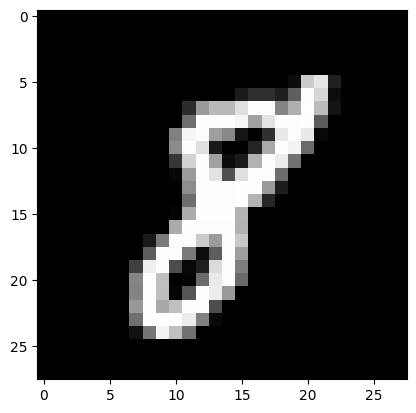

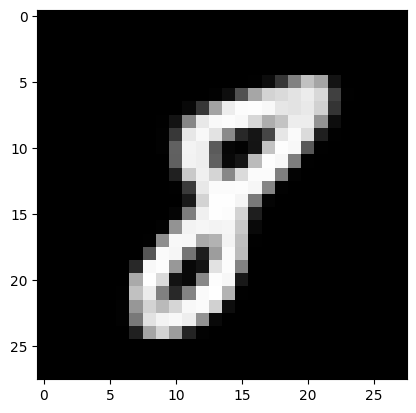

In [15]:
model.load_state_dict(torch.load("./models/" + activation_func + "/finetuned", weights_only = True))
model.eval()

for digit in examples:

	image_tensor = examples[digit]
	image = tensor_to_img(image_tensor)
	imgplot = plt.imshow(image, cmap = "gray")
	plt.show()

	with torch.no_grad():
		image_tensor = torch.flatten(image_tensor).to(device)
		reconstructed = model(image_tensor)

	reconstructed = torch.unflatten(reconstructed, dim = 0, sizes = (28, 28)).to(device)

	image_reconstructed = tensor_to_img(reconstructed)

	imgplot = plt.imshow(image_reconstructed, cmap = "gray")
	plt.show()

### Clustering

In [16]:
model = SAE()
model.to(device)

model.load_state_dict(
    torch.load("./models/" + activation_func + "/finetuned", weights_only = True)
)

model.eval()

all_z = []
all_labels = []

model.eval()

with torch.no_grad():
    for images, labels in dataloader:
        images = torch.flatten(images, start_dim = 1).to(device)

        z = model.encode(images)

        all_z.append(z.cpu().numpy())
        all_labels.append(labels.numpy())

Z = np.concatenate(all_z, axis = 0)
y_true = np.concatenate(all_labels, axis = 0)

print(Z.shape)
print(y_true.shape)

(70000, 10)
(70000,)


In [17]:
from sklearn.cluster import KMeans

n_clusters = 10

kmeans = KMeans(
    n_clusters = n_clusters,
    n_init = 20,
    random_state = 42
)

cluster_labels = kmeans.fit_predict(Z)

centroids = kmeans.cluster_centers_

print(cluster_labels.shape)
print(centroids.shape)

(70000,)
(10, 10)


In [18]:
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

ari = adjusted_rand_score(y_true, cluster_labels)
nmi = normalized_mutual_info_score(y_true, cluster_labels)

print(f"ARI: {ari:.4f}")
print(f"NMI: {nmi:.4f}")

ARI: 0.5578
NMI: 0.6404


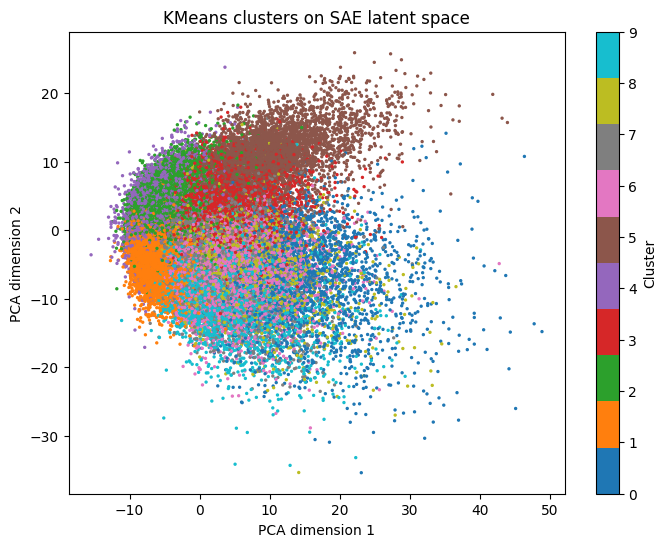

In [ ]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components = 2, random_state = 42)
Z_2d = pca.fit_transform(Z)

plt.figure(figsize = (8, 6))
plt.scatter(
    Z_2d[:, 0],
    Z_2d[:, 1],
    c = cluster_labels,
    s = 2,
    cmap = "tab10"
)
plt.title("KMeans clusters on SAE latent space")
plt.xlabel("PCA dimension 1")
plt.ylabel("PCA dimension 2")
plt.colorbar(label = "Cluster")
plt.show()

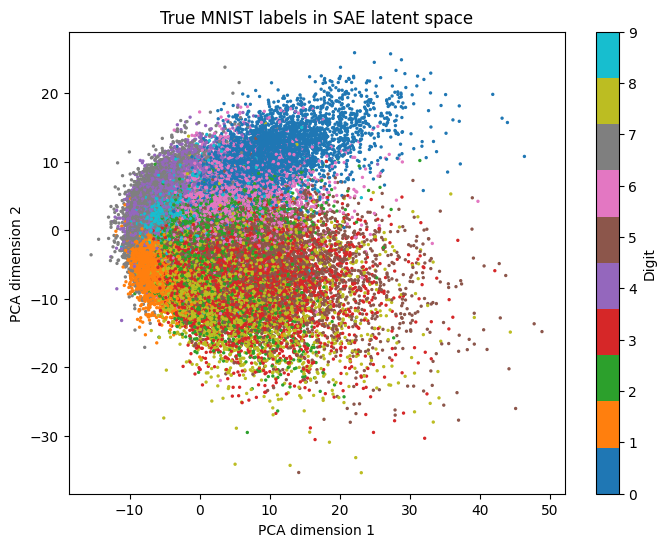

In [ ]:
plt.figure(figsize = (8, 6))
plt.scatter(
    Z_2d[:, 0],
    Z_2d[:, 1],
    c = y_true,
    s = 2,
    cmap = "tab10"
)
plt.title("True MNIST labels in SAE latent space")
plt.xlabel("PCA dimension 1")
plt.ylabel("PCA dimension 2")
plt.colorbar(label = "Digit")
plt.show()

In [ ]:
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import numpy as np

tsne = TSNE(
    n_components = 2,
    perplexity = 30,
    learning_rate = "auto",
    init = "pca",
    random_state = 42
)

Z_tsne = tsne.fit_transform(Z)

print(Z_tsne.shape)

(70000, 2)


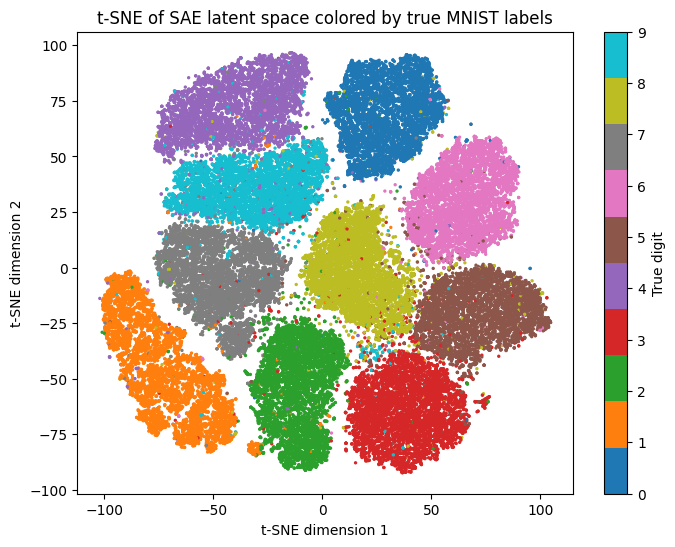

In [ ]:
plt.figure(figsize = (8, 6))
plt.scatter(
    Z_tsne[:, 0],
    Z_tsne[:, 1],
    c = y_true,
    s = 2,
    cmap = "tab10"
)
plt.title("t-SNE of SAE latent space colored by true MNIST labels")
plt.xlabel("t-SNE dimension 1")
plt.ylabel("t-SNE dimension 2")
plt.colorbar(label = "True digit")
plt.show()

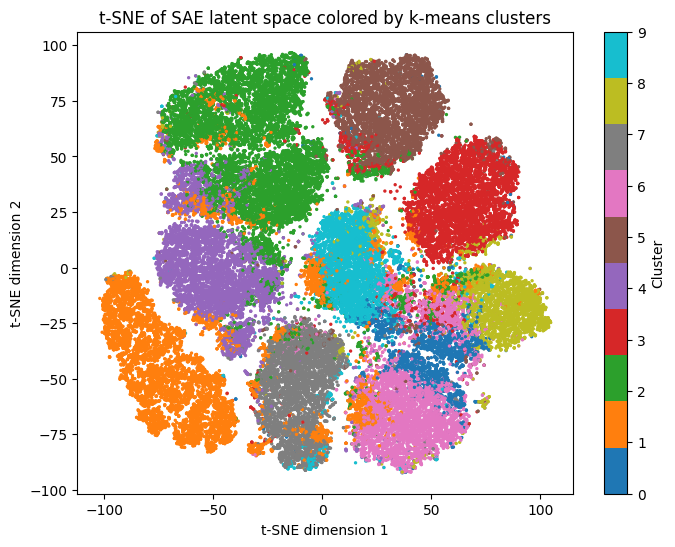

In [ ]:
plt.figure(figsize = (8, 6))
plt.scatter(
    Z_tsne[:, 0],
    Z_tsne[:, 1],
    c = cluster_labels,
    s = 2,
    cmap = "tab10"
)
plt.title("t-SNE of SAE latent space colored by k-means clusters")
plt.xlabel("t-SNE dimension 1")
plt.ylabel("t-SNE dimension 2")
plt.colorbar(label = "Cluster")
plt.show()

In [24]:
from scipy.optimize import linear_sum_assignment
from sklearn.metrics import confusion_matrix
import numpy as np

def clustering_accuracy(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    row_ind, col_ind = linear_sum_assignment(-cm)
    return cm[row_ind, col_ind].sum() / y_true.size

acc = clustering_accuracy(y_true, cluster_labels)

print(f"Clustering Accuracy: {acc:.4f}")

Clustering Accuracy: 0.7161


In [ ]:
import pandas as pd

cluster_digit_counts = pd.crosstab(
    pd.Series(cluster_labels, name = "Cluster"),
    pd.Series(y_true, name = "True digit")
)

cluster_digit_counts

True digit,0,1,2,3,4,5,6,7,8,9
Cluster,,,,,,,,,,
0,21,5,9,1044,12,1019,19,7,431,26
1,12,7762,679,639,414,378,144,400,870,452
2,428,10,150,103,6119,340,35,704,305,5081
3,452,10,59,6,63,235,6326,1,119,10
4,39,10,152,119,136,14,1,6116,111,1288
5,5878,0,74,19,21,57,188,26,87,42
6,11,5,75,4988,0,1032,1,1,348,50
7,1,45,5556,59,17,1,12,35,20,5
8,49,23,35,101,32,3142,140,1,322,2


In [ ]:
cluster_digit_percentages = cluster_digit_counts.div(
    cluster_digit_counts.sum(axis = 1),
    axis = 0
)

cluster_digit_percentages.round(2)

True digit,0,1,2,3,4,5,6,7,8,9
Cluster,,,,,,,,,,
0,0.01,0.00,0.00,0.40,0.00,0.39,0.01,0.00,0.17,0.01
1,0.00,0.66,0.06,0.05,0.04,0.03,0.01,0.03,0.07,0.04
2,0.03,0.00,0.01,0.01,0.46,0.03,0.00,0.05,0.02,0.38
3,0.06,0.00,0.01,0.00,0.01,0.03,0.87,0.00,0.02,0.00
4,0.00,0.00,0.02,0.01,0.02,0.00,0.00,0.77,0.01,0.16
5,0.92,0.00,0.01,0.00,0.00,0.01,0.03,0.00,0.01,0.01
6,0.00,0.00,0.01,0.77,0.00,0.16,0.00,0.00,0.05,0.01
7,0.00,0.01,0.97,0.01,0.00,0.00,0.00,0.01,0.00,0.00
8,0.01,0.01,0.01,0.03,0.01,0.82,0.04,0.00,0.08,0.00


## Extra Layer 2000 -> 500 -> 10

### Train

In [27]:
activation_func = "larger"

class SAE(nn.Module):
	def __init__(self):
		super().__init__()

		self.encoder_layer_1 =  nn.Sequential(
			nn.Dropout(0.2),
			nn.Linear(28 * 28, 500),
			nn.ReLU(),
		)

		self.decoder_layer_1 =  nn.Sequential(
			nn.Dropout(0.2),
			nn.Linear(500, 28 * 28),
			nn.Sigmoid(),
		)

		self.encoder_layer_2 =  nn.Sequential(
			nn.Dropout(0.2),
			nn.Linear(500, 500),
			nn.ReLU(),
		)

		self.decoder_layer_2 =  nn.Sequential(
			nn.Dropout(0.2),
			nn.Linear(500, 500),
			nn.ReLU(),
		)

		self.encoder_layer_3 =  nn.Sequential(
			nn.Dropout(0.2),
			nn.Linear(500, 2000),
			nn.ReLU(),
		)

		self.decoder_layer_3 =  nn.Sequential(
			nn.Dropout(0.2),
			nn.Linear(2000, 500),
			nn.ReLU(),
		)

		self.encoder_layer_4 =  nn.Sequential(
			nn.Dropout(0.2),
			nn.Linear(2000, 500),
			nn.ReLU(),
		)

		self.decoder_layer_4 =  nn.Sequential(
			nn.Dropout(0.2),
			nn.Linear(500, 2000),
			nn.ReLU(),
		)
		
		self.encoder_layer_5 =  nn.Sequential(
			nn.Dropout(0.2),
			nn.Linear(500, 10),
		)

		self.decoder_layer_5 =  nn.Sequential(
			nn.Dropout(0.2),
			nn.Linear(10, 500),
			nn.ReLU(),
		)

	def forward(self, x):
		encoded = self.encoder_layer_5(
					self.encoder_layer_4(
						self.encoder_layer_3(
							self.encoder_layer_2(
								self.encoder_layer_1(x)
							)
						)
					)
				)

		decoded = self.decoder_layer_1(
					self.decoder_layer_2(
						self.decoder_layer_3(
							self.decoder_layer_4(
								self.decoder_layer_5(encoded)
							)
						)
					)
				)
		return decoded
	
	def encode(self, x):
		e1 = self.encoder_layer_1(x)
		e2 = self.encoder_layer_2(e1)
		e3 = self.encoder_layer_3(e2)
		e4 = self.encoder_layer_4(e3)
		z = self.encoder_layer_5(e4)
		return z

In [ ]:
model = SAE()
model.to(device)

# Pretraining
pretrain_epochs = 200

# Pretrain layer 1

loss_function = nn.BCELoss()

optimizer = optim.SGD(
    list(model.encoder_layer_1.parameters()) + 
    list(model.decoder_layer_1.parameters()),
    lr = 0.1, 
    momentum = 0.9
    )

scheduler = optim.lr_scheduler.StepLR(
    optimizer, 
    step_size = 20000, #Amount of iterations the scheduler will update the lr
    gamma = 0.1 #by how much the scheduler will divide the current lr
    )

best_loss = (float("inf"), 0)

model.train()
for epoch in range(pretrain_epochs):
    batch_losses = []
    
    for images, _ in dataloader:

        images = torch.flatten(images, start_dim = 1).to(device)
        e1 = model.encoder_layer_1(images)
        e1_reconstructed = model.decoder_layer_1(e1)
        loss = loss_function(e1_reconstructed, images)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        scheduler.step()

        batch_losses.append(loss.item())
    
    epoch_loss = sum(batch_losses) / len(batch_losses)

    print(f"Pretrain 1: Epoch {epoch+1}/{pretrain_epochs}, Loss: {epoch_loss:.6f}")

    if epoch_loss <= best_loss[0]:
        best_loss = (epoch_loss, epoch + 1)
        torch.save(model.state_dict(), "./models/" + activation_func + "/pre1")

        print(f"Best Pretrain 1 Epoch: {best_loss[1]}/{pretrain_epochs}, Loss: {best_loss[0]:.6f}")

# Pretrain layer 2

model.load_state_dict(torch.load("./models/" + activation_func + "/pre1", weights_only = True))

loss_function = nn.MSELoss()

optimizer = optim.SGD(
    list(model.encoder_layer_2.parameters()) + 
    list(model.decoder_layer_2.parameters()),
    lr = 0.1, 
    momentum = 0.9
    )

scheduler = optim.lr_scheduler.StepLR(
    optimizer, 
    step_size = 20000, #Amount of iterations the scheduler will update the lr
    gamma = 0.1 #by how much the scheduler will divide the current lr
    )

best_loss = (float("inf"), 0)

# Deactivate Dropout because Layer is Frozen
model.encoder_layer_1.eval()

for epoch in range(pretrain_epochs):
    batch_losses = []

    for images, _ in dataloader:

        images = torch.flatten(images, start_dim = 1).to(device)

        with torch.no_grad():
            e1 = model.encoder_layer_1(images)
        
        e2 = model.encoder_layer_2(e1)
        e1_reconstructed = model.decoder_layer_2(e2)

        loss = loss_function(e1_reconstructed, e1)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        scheduler.step()

        batch_losses.append(loss.item())
    
    epoch_loss = sum(batch_losses) / len(batch_losses)

    print(f"Pretrain 2: Epoch {epoch+1}/{pretrain_epochs}, Loss: {epoch_loss:.6f}")

    if epoch_loss <= best_loss[0]:
        best_loss = (epoch_loss, epoch + 1)
        torch.save(model.state_dict(), "./models/" + activation_func + "/pre2")

        print(f"Best Pretrain 2 Epoch: {best_loss[1]}/{pretrain_epochs}, Loss: {best_loss[0]:.6f}")


# Pretrain layer 3

model.load_state_dict(torch.load("./models/" + activation_func + "/pre2", weights_only = True))

loss_function = nn.MSELoss()

optimizer = optim.SGD(
    list(model.encoder_layer_3.parameters()) + 
    list(model.decoder_layer_3.parameters()),
    lr = 0.1, 
    momentum = 0.9
    )

scheduler = optim.lr_scheduler.StepLR(
    optimizer, 
    step_size = 20000, #Amount of iterations the scheduler will update the lr
    gamma = 0.1 #by how much the scheduler will divide the current lr
    )

best_loss = (float("inf"), 0)

# Deactivate Dropout because Layer is Frozen
model.encoder_layer_1.eval()
model.encoder_layer_2.eval()

for epoch in range(pretrain_epochs):
    batch_losses = []

    for images, _ in dataloader:

        images = torch.flatten(images, start_dim = 1).to(device)

        with torch.no_grad():
            e1 = model.encoder_layer_1(images)
            e2 = model.encoder_layer_2(e1)
        
        e3 = model.encoder_layer_3(e2)
        e2_reconstructed = model.decoder_layer_3(e3)

        loss = loss_function(e2_reconstructed, e2)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        scheduler.step()

        batch_losses.append(loss.item())
    
    epoch_loss = sum(batch_losses) / len(batch_losses)

    print(f"Pretrain 3: Epoch {epoch+1}/{pretrain_epochs}, Loss: {epoch_loss:.6f}")

    if epoch_loss <= best_loss[0]:
        best_loss = (epoch_loss, epoch + 1)
        torch.save(model.state_dict(), "./models/" + activation_func + "/pre3")

        print(f"Best Pretrain 3 Epoch: {best_loss[1]}/{pretrain_epochs}, Loss: {best_loss[0]:.6f}")


# Pretrain layer 4

model.load_state_dict(torch.load("./models/" + activation_func + "/pre3", weights_only = True))

loss_function = nn.MSELoss()

optimizer = optim.SGD(
    list(model.encoder_layer_4.parameters()) + 
    list(model.decoder_layer_4.parameters()),
    lr = 0.1, 
    momentum = 0.9
    )

scheduler = optim.lr_scheduler.StepLR(
    optimizer, 
    step_size = 20000, #Amount of iterations the scheduler will update the lr
    gamma = 0.1 #by how much the scheduler will divide the current lr
    )

best_loss = (float("inf"), 0)

# Deactivate Dropout because Layer is Frozen
model.encoder_layer_1.eval()
model.encoder_layer_2.eval()
model.encoder_layer_3.eval()

for epoch in range(pretrain_epochs):
    batch_losses = []

    for images, _ in dataloader:

        images = torch.flatten(images, start_dim = 1).to(device)

        with torch.no_grad():
            e1 = model.encoder_layer_1(images)
            e2 = model.encoder_layer_2(e1)
            e3 = model.encoder_layer_3(e2)
        
        e4 = model.encoder_layer_4(e3)
        e3_reconstructed = model.decoder_layer_4(e4)

        loss = loss_function(e3_reconstructed, e3)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        scheduler.step()

        batch_losses.append(loss.item())
    
    epoch_loss = sum(batch_losses) / len(batch_losses)

    print(f"Pretrain 4: Epoch {epoch+1}/{pretrain_epochs}, Loss: {epoch_loss:.6f}")

    if epoch_loss <= best_loss[0]:
        best_loss = (epoch_loss, epoch + 1)
        torch.save(model.state_dict(), "./models/" + activation_func + "/pre4")

        print(f"Best Pretrain 4 Epoch: {best_loss[1]}/{pretrain_epochs}, Loss: {best_loss[0]:.6f}")
        
# Pretrain layer 5

model.load_state_dict(torch.load("./models/" + activation_func + "/pre4", weights_only = True))

loss_function = nn.MSELoss()

optimizer = optim.SGD(
    list(model.encoder_layer_5.parameters()) + 
    list(model.decoder_layer_5.parameters()),
    lr = 0.1, 
    momentum = 0.9
    )

scheduler = optim.lr_scheduler.StepLR(
    optimizer, 
    step_size = 20000, #Amount of iterations the scheduler will update the lr
    gamma = 0.1 #by how much the scheduler will divide the current lr
    )

best_loss = (float("inf"), 0)

# Deactivate Dropout because Layer is Frozen
model.encoder_layer_1.eval()
model.encoder_layer_2.eval()
model.encoder_layer_3.eval()
model.encoder_layer_4.eval()

for epoch in range(pretrain_epochs):
    batch_losses = []

    for images, _ in dataloader:

        images = torch.flatten(images, start_dim = 1).to(device)

        with torch.no_grad():
            e1 = model.encoder_layer_1(images)
            e2 = model.encoder_layer_2(e1)
            e3 = model.encoder_layer_3(e2)
            e4 = model.encoder_layer_4(e3)
        
        e5 = model.encoder_layer_5(e4)
        e4_reconstructed = model.decoder_layer_5(e5)

        loss = loss_function(e4_reconstructed, e4)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        scheduler.step()

        batch_losses.append(loss.item())
    
    epoch_loss = sum(batch_losses) / len(batch_losses)

    print(f"Pretrain 5: Epoch {epoch+1}/{pretrain_epochs}, Loss: {epoch_loss:.6f}")

    if epoch_loss <= best_loss[0]:
        best_loss = (epoch_loss, epoch + 1)
        torch.save(model.state_dict(), "./models/" + activation_func + "/pre5")

        print(f"Best Pretrain 5 Epoch: {best_loss[1]}/{pretrain_epochs}, Loss: {best_loss[0]:.6f}")

Pretrain 1: Epoch 1/200, Loss: 0.340684
Best Pretrain 1 Epoch: 1/200, Loss: 0.340684
Pretrain 1: Epoch 2/200, Loss: 0.243804
Best Pretrain 1 Epoch: 2/200, Loss: 0.243804
Pretrain 1: Epoch 3/200, Loss: 0.214287
Best Pretrain 1 Epoch: 3/200, Loss: 0.214287
Pretrain 1: Epoch 4/200, Loss: 0.196021
Best Pretrain 1 Epoch: 4/200, Loss: 0.196021
Pretrain 1: Epoch 5/200, Loss: 0.183783
Best Pretrain 1 Epoch: 5/200, Loss: 0.183783
Pretrain 1: Epoch 6/200, Loss: 0.174462
Best Pretrain 1 Epoch: 6/200, Loss: 0.174462
Pretrain 1: Epoch 7/200, Loss: 0.166997
Best Pretrain 1 Epoch: 7/200, Loss: 0.166997
Pretrain 1: Epoch 8/200, Loss: 0.160717
Best Pretrain 1 Epoch: 8/200, Loss: 0.160717
Pretrain 1: Epoch 9/200, Loss: 0.155337
Best Pretrain 1 Epoch: 9/200, Loss: 0.155337
Pretrain 1: Epoch 10/200, Loss: 0.150703
Best Pretrain 1 Epoch: 10/200, Loss: 0.150703
Pretrain 1: Epoch 11/200, Loss: 0.146621
Best Pretrain 1 Epoch: 11/200, Loss: 0.146621
Pretrain 1: Epoch 12/200, Loss: 0.143069
Best Pretrain 1 Epoc

In [ ]:
model.load_state_dict(torch.load("./models/" + activation_func + "/pre5", weights_only = True))

train_epochs = 400

loss_function = nn.BCELoss()

optimizer = optim.SGD(
    model.parameters(),
    lr = 0.1, 
    momentum = 0.9
    )

scheduler = optim.lr_scheduler.StepLR(
    optimizer, 
    step_size = 20000, #Amount of iterations the scheduler will update the lr
    gamma = 0.1 #by how much the scheduler will divide the current lr
    )

best_loss = (float("inf"), 0)

model.eval() # deactivate all dropout
for epoch in range(train_epochs):
    batch_losses = []
    
    for images, _ in dataloader:

        images = torch.flatten(images, start_dim = 1).to(device)
        reconstructed = model(images)
        loss = loss_function(reconstructed, images)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        scheduler.step()

        batch_losses.append(loss.item())
    
    epoch_loss = sum(batch_losses) / len(batch_losses)

    print(f"Finetune: Epoch {epoch+1}/{train_epochs}, Loss: {epoch_loss:.6f}")

    if epoch_loss <= best_loss[0]:
        best_loss = (epoch_loss, epoch + 1)
        torch.save(model.state_dict(), "./models/" + activation_func + "/finetuned")

        print(f"Best Finetune Epoch: {best_loss[1]}/{train_epochs}, Loss: {best_loss[0]:.6f}")

Finetune: Epoch 1/400, Loss: 0.137892
Best Finetune Epoch: 1/400, Loss: 0.137892
Finetune: Epoch 2/400, Loss: 0.124884
Best Finetune Epoch: 2/400, Loss: 0.124884
Finetune: Epoch 3/400, Loss: 0.119640
Best Finetune Epoch: 3/400, Loss: 0.119640
Finetune: Epoch 4/400, Loss: 0.116440
Best Finetune Epoch: 4/400, Loss: 0.116440
Finetune: Epoch 5/400, Loss: 0.114151
Best Finetune Epoch: 5/400, Loss: 0.114151
Finetune: Epoch 6/400, Loss: 0.112352
Best Finetune Epoch: 6/400, Loss: 0.112352
Finetune: Epoch 7/400, Loss: 0.110872
Best Finetune Epoch: 7/400, Loss: 0.110872
Finetune: Epoch 8/400, Loss: 0.109632
Best Finetune Epoch: 8/400, Loss: 0.109632
Finetune: Epoch 9/400, Loss: 0.108575
Best Finetune Epoch: 9/400, Loss: 0.108575
Finetune: Epoch 10/400, Loss: 0.107638
Best Finetune Epoch: 10/400, Loss: 0.107638
Finetune: Epoch 11/400, Loss: 0.106774
Best Finetune Epoch: 11/400, Loss: 0.106774
Finetune: Epoch 12/400, Loss: 0.106036
Best Finetune Epoch: 12/400, Loss: 0.106036
Finetune: Epoch 13/400

### Visualize

In [30]:
examples = {}

for image, label in dataset:
    label = int(label)
    if label not in examples:
        examples[label] = image

    if len(examples) == 10:
        break
    
model = SAE()
model.to(device)

SAE(
  (encoder_layer_1): Sequential(
    (0): Dropout(p=0.2, inplace=False)
    (1): Linear(in_features=784, out_features=500, bias=True)
    (2): ReLU()
  )
  (decoder_layer_1): Sequential(
    (0): Dropout(p=0.2, inplace=False)
    (1): Linear(in_features=500, out_features=784, bias=True)
    (2): Sigmoid()
  )
  (encoder_layer_2): Sequential(
    (0): Dropout(p=0.2, inplace=False)
    (1): Linear(in_features=500, out_features=500, bias=True)
    (2): ReLU()
  )
  (decoder_layer_2): Sequential(
    (0): Dropout(p=0.2, inplace=False)
    (1): Linear(in_features=500, out_features=500, bias=True)
    (2): ReLU()
  )
  (encoder_layer_3): Sequential(
    (0): Dropout(p=0.2, inplace=False)
    (1): Linear(in_features=500, out_features=2000, bias=True)
    (2): ReLU()
  )
  (decoder_layer_3): Sequential(
    (0): Dropout(p=0.2, inplace=False)
    (1): Linear(in_features=2000, out_features=500, bias=True)
    (2): ReLU()
  )
  (encoder_layer_4): Sequential(
    (0): Dropout(p=0.2, inplace=F

#### Autoencoder Layer 1


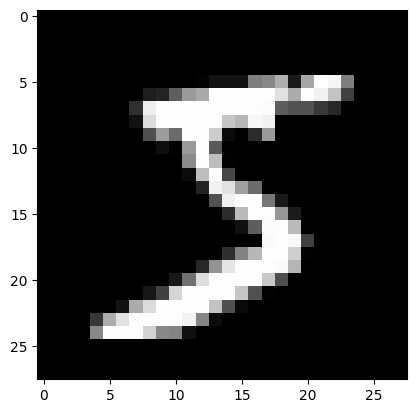

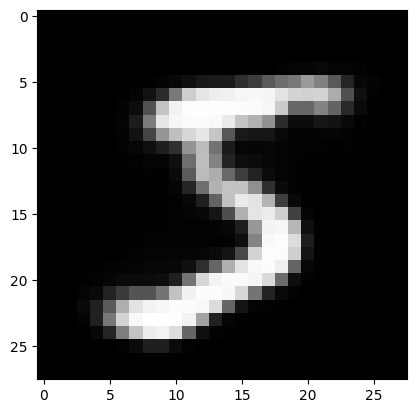

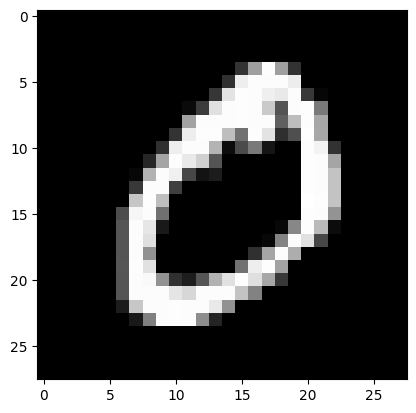

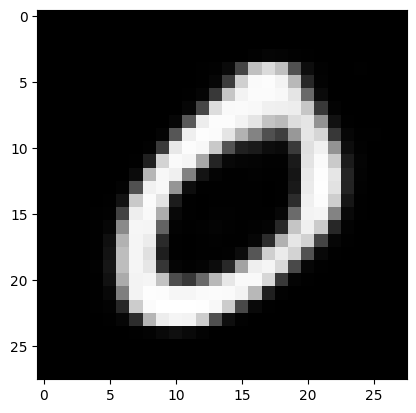

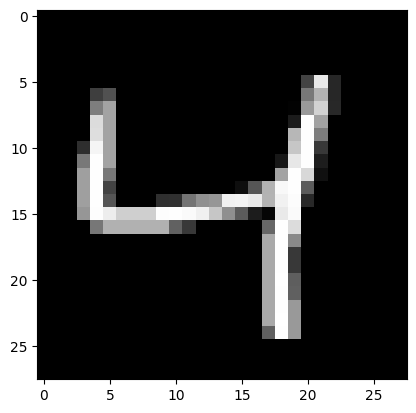

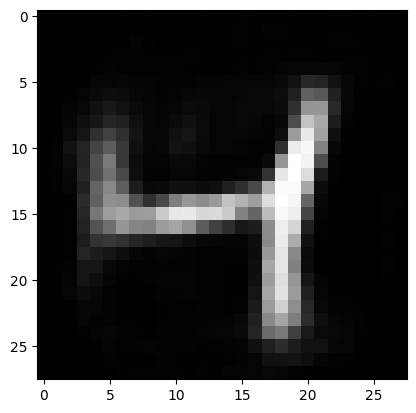

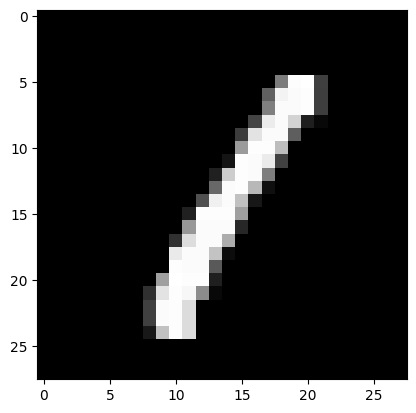

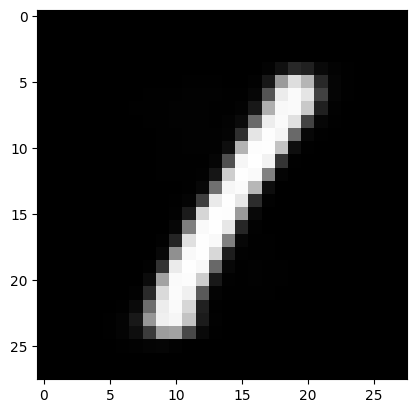

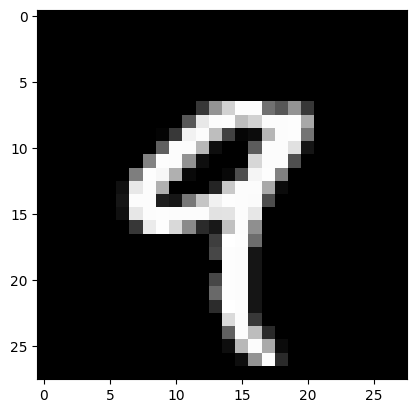

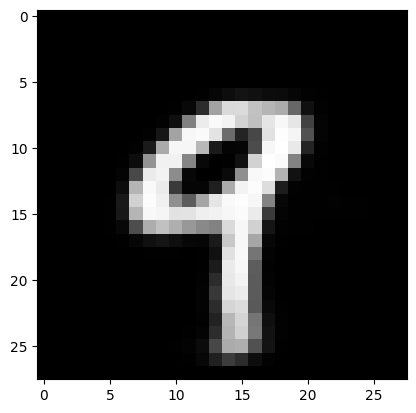

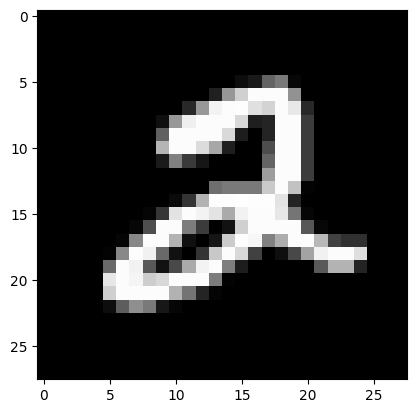

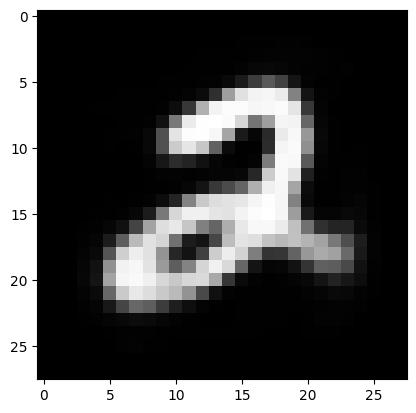

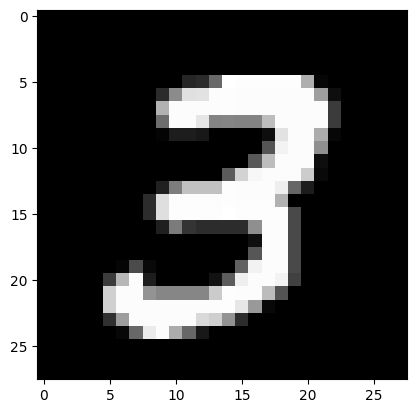

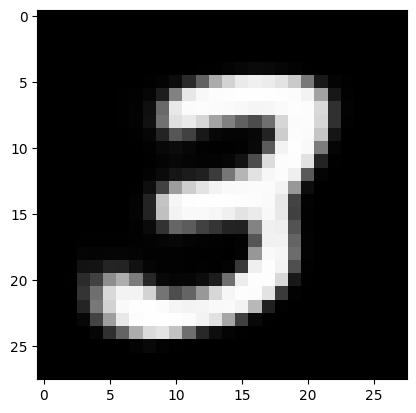

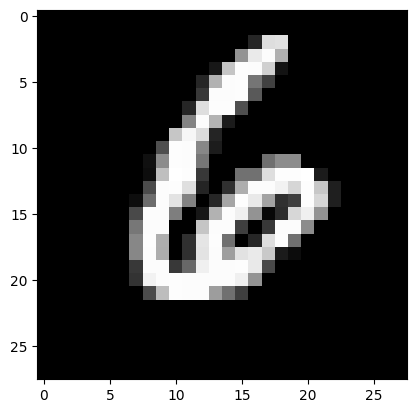

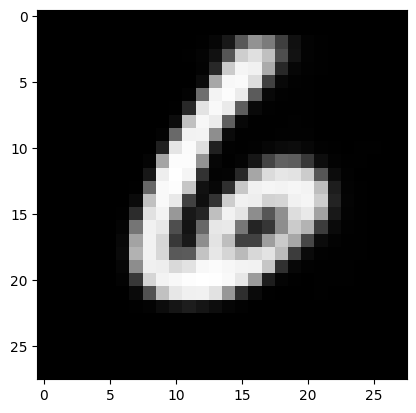

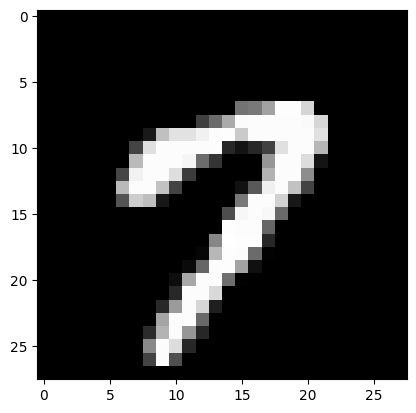

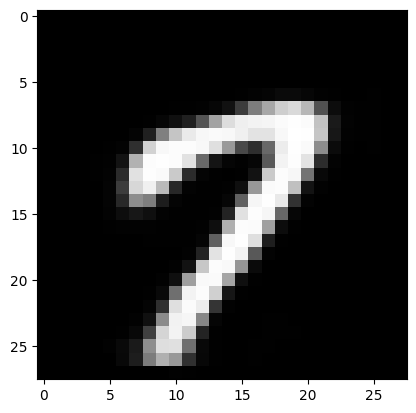

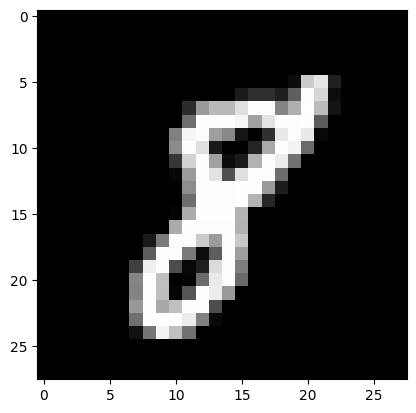

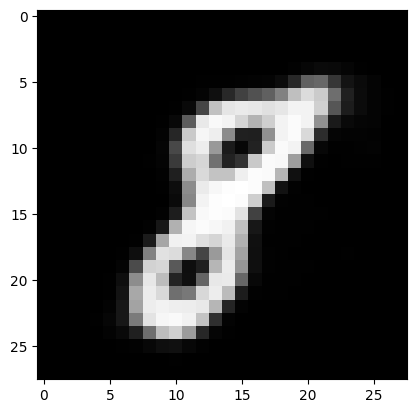

In [31]:
model.load_state_dict(torch.load("./models/" + activation_func + "/pre1", weights_only = True))
model.eval()

for digit in examples:

	image_tensor = examples[digit]
	image = tensor_to_img(image_tensor)
	imgplot = plt.imshow(image, cmap = "gray")
	plt.show()

	with torch.no_grad():
		image_tensor = torch.flatten(image_tensor).to(device)

		e1 = model.encoder_layer_1(image_tensor)
		e1_reconstructed = model.decoder_layer_1(e1)

	e1_reconstructed = torch.unflatten(e1_reconstructed, dim = 0, sizes = (28, 28)).to(device)

	image_reconstructed = tensor_to_img(e1_reconstructed)

	# To view it:
	imgplot = plt.imshow(image_reconstructed, cmap = "gray")
	plt.show()

#### Autoencoder Layer 2


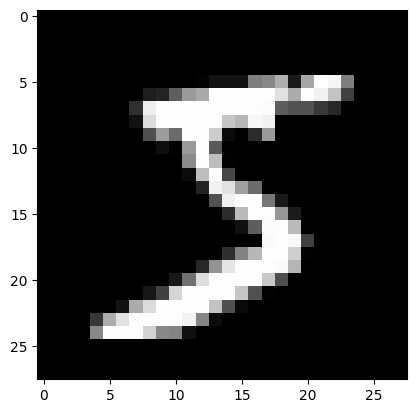

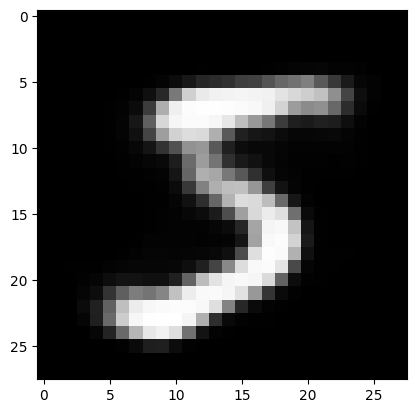

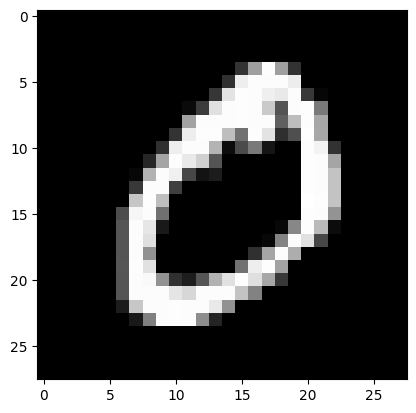

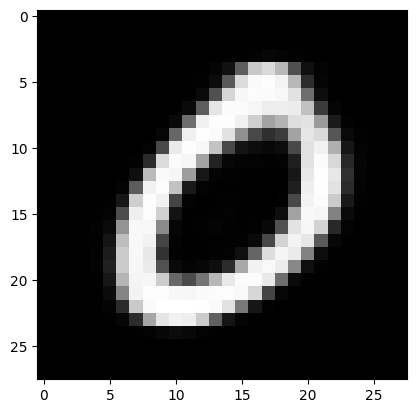

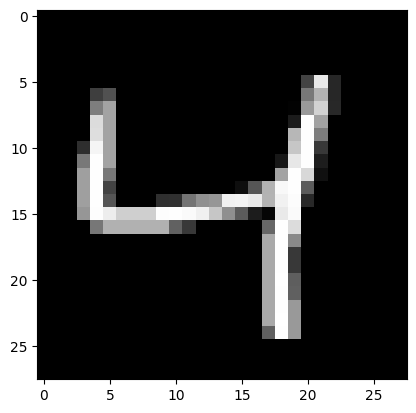

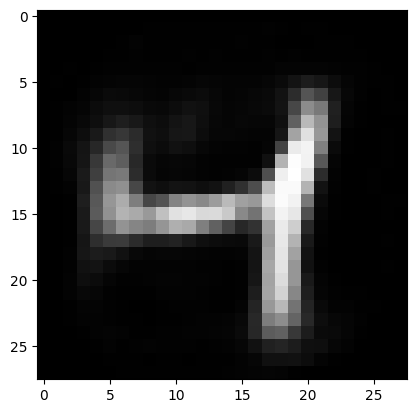

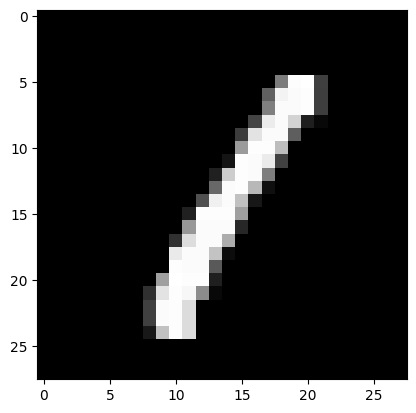

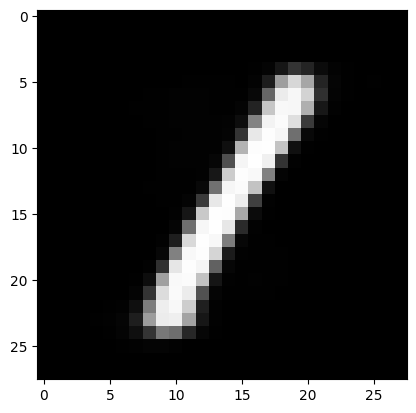

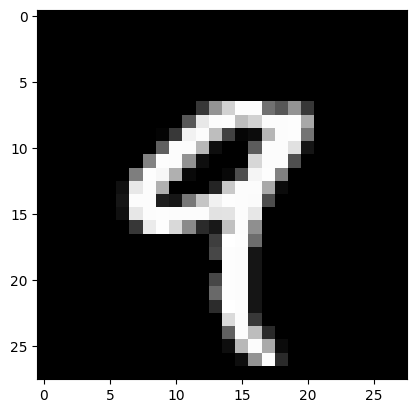

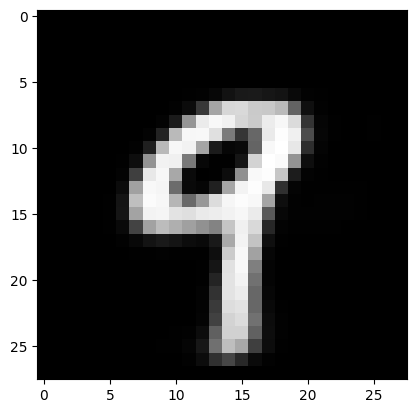

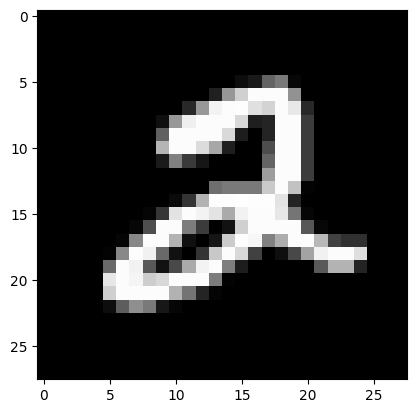

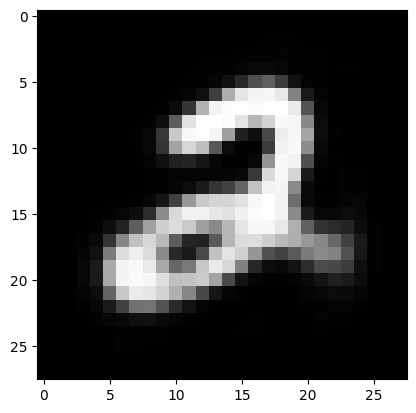

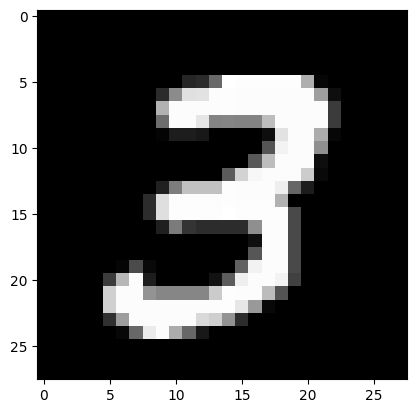

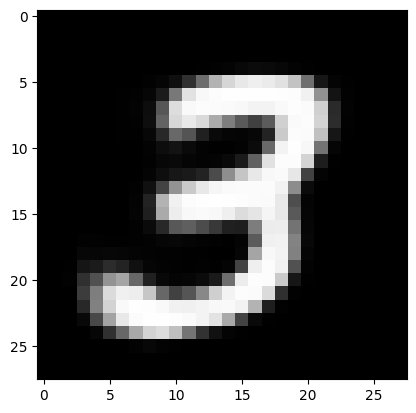

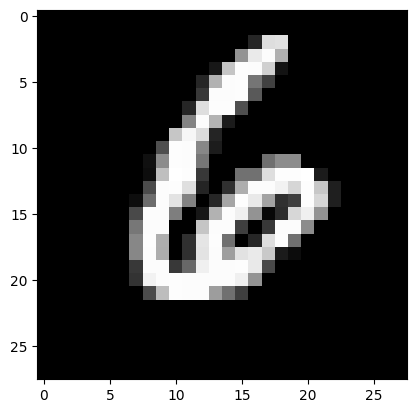

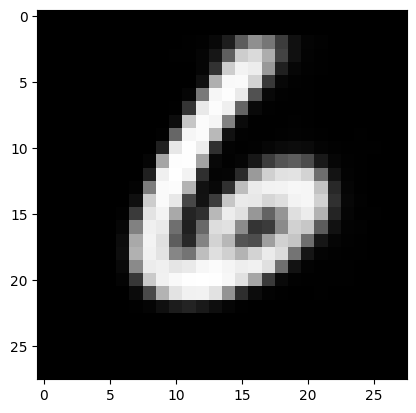

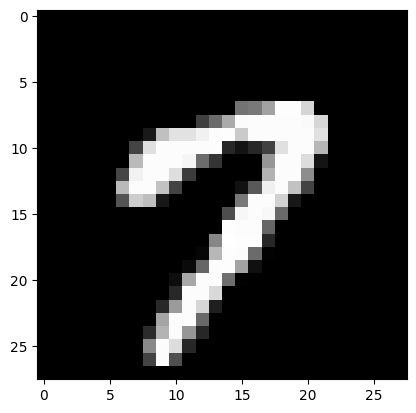

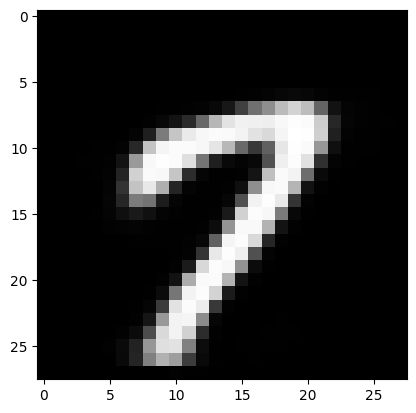

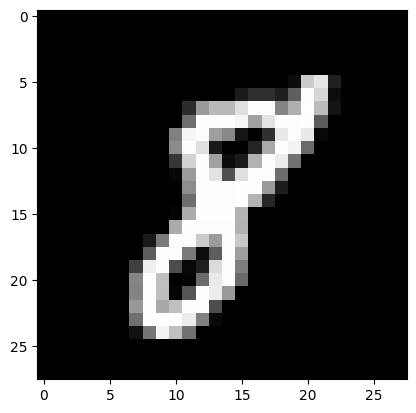

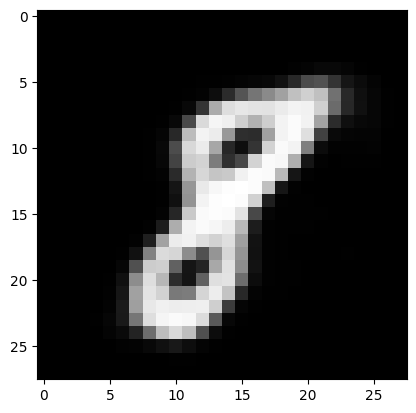

In [32]:
model.load_state_dict(torch.load("./models/" + activation_func + "/pre2", weights_only = True))
model.eval()

for digit in examples:

	image_tensor = examples[digit]
	image = tensor_to_img(image_tensor)
	imgplot = plt.imshow(image, cmap = "gray")
	plt.show()

	with torch.no_grad():
		image_tensor = torch.flatten(image_tensor).to(device)

		e1 = model.encoder_layer_1(image_tensor)
		e2 = model.encoder_layer_2(e1)

		e2_reconstructed = model.decoder_layer_2(e2)
		e1_reconstructed = model.decoder_layer_1(e2_reconstructed)

	e1_reconstructed = torch.unflatten(e1_reconstructed, dim = 0, sizes = (28, 28)).to(device)

	image_reconstructed = tensor_to_img(e1_reconstructed)

	imgplot = plt.imshow(image_reconstructed, cmap = "gray")
	plt.show()

#### Autoencoder Layer 3


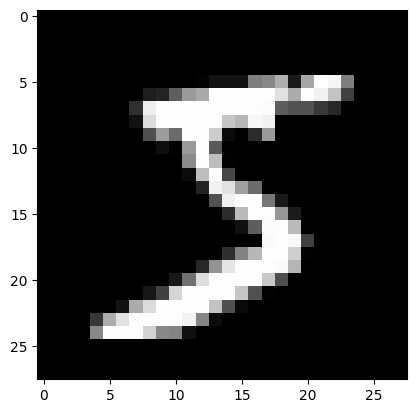

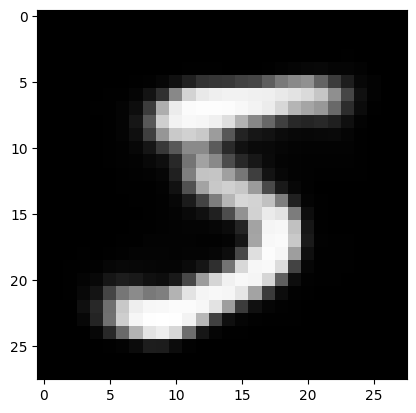

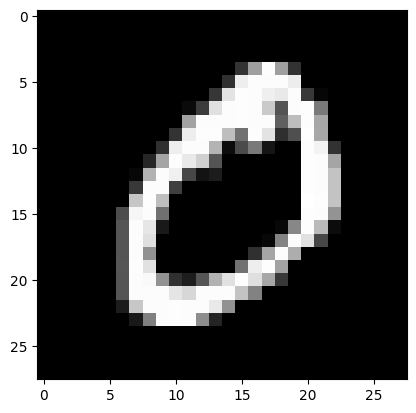

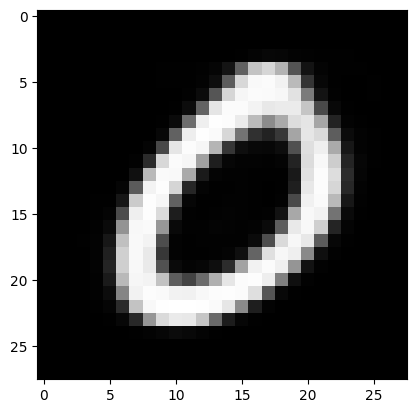

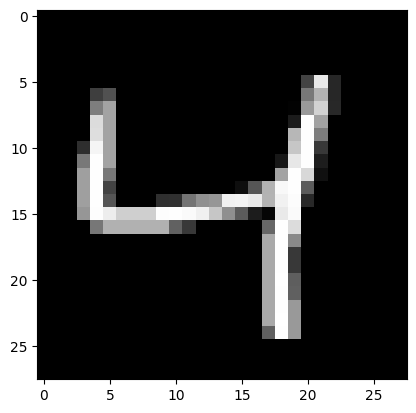

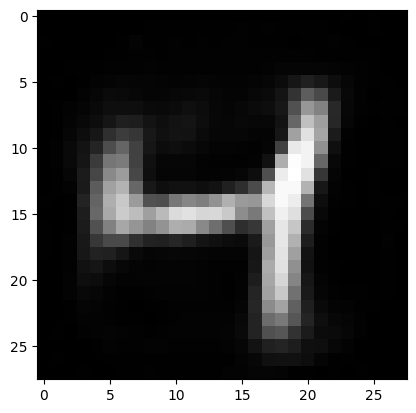

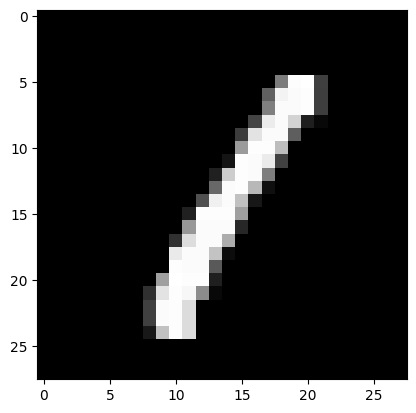

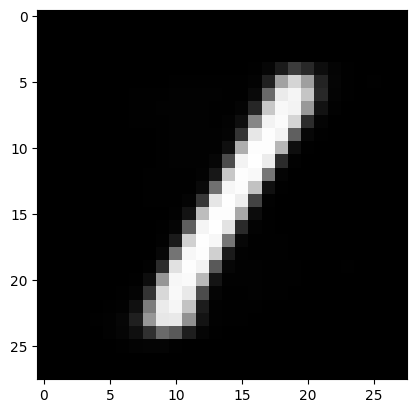

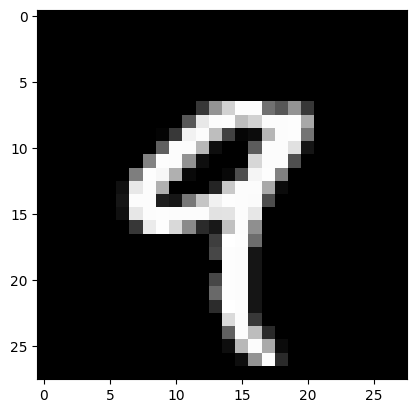

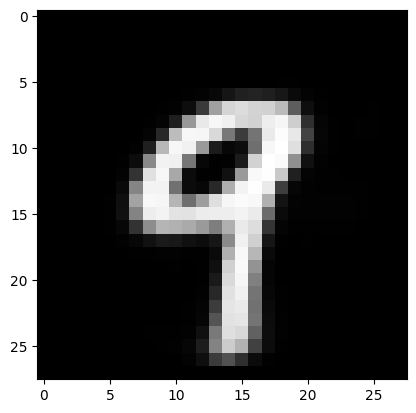

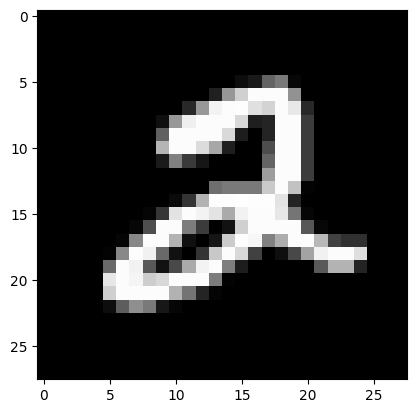

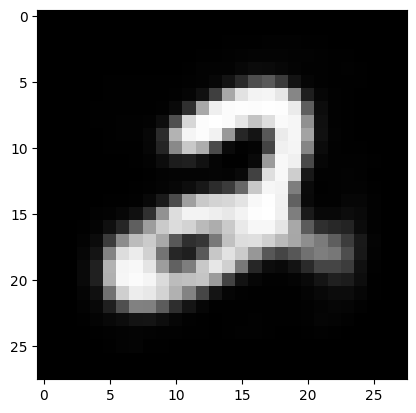

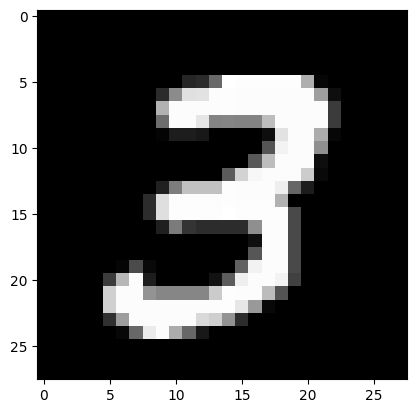

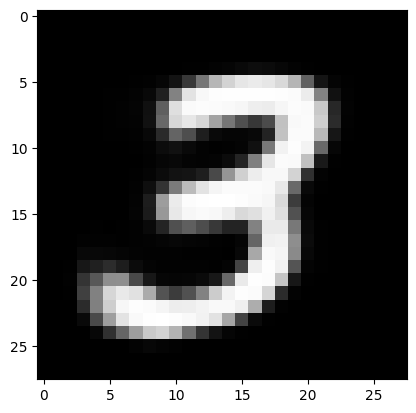

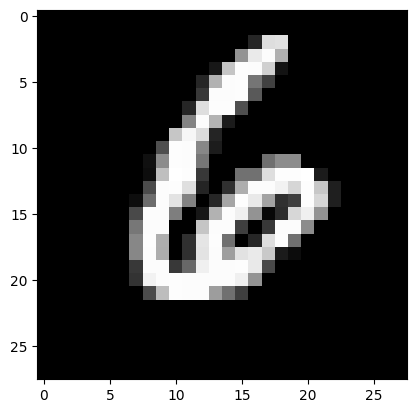

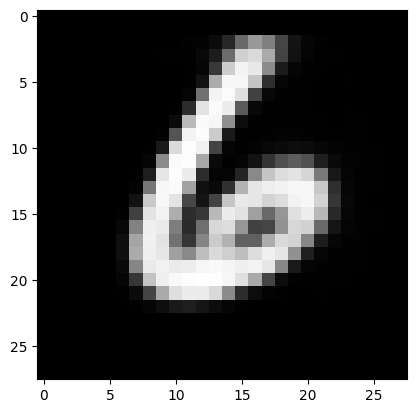

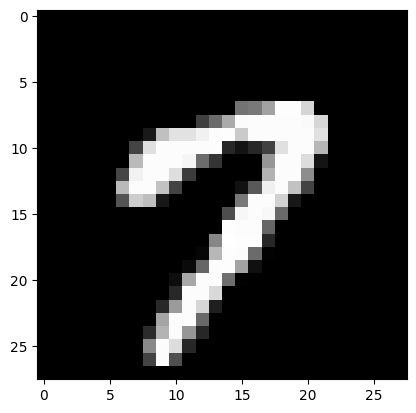

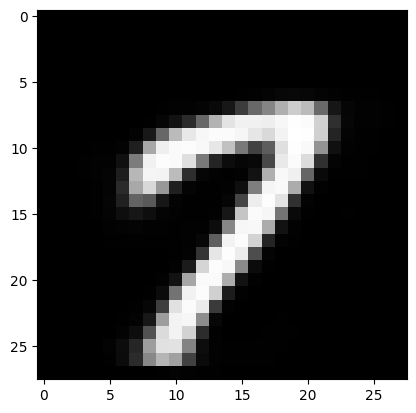

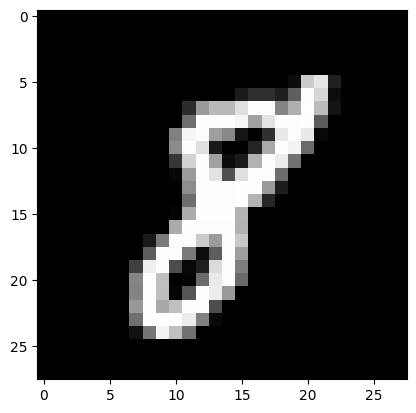

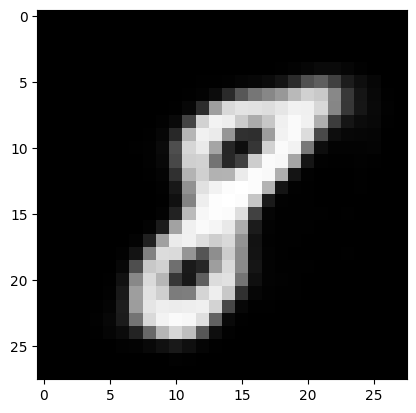

In [33]:
model.load_state_dict(torch.load("./models/" + activation_func + "/pre3", weights_only = True))
model.eval()

for digit in examples:

	image_tensor = examples[digit]
	image = tensor_to_img(image_tensor)
	imgplot = plt.imshow(image, cmap = "gray")
	plt.show()

	with torch.no_grad():
		image_tensor = torch.flatten(image_tensor).to(device)

		e1 = model.encoder_layer_1(image_tensor)
		e2 = model.encoder_layer_2(e1)
		e3 = model.encoder_layer_3(e2)

		e3_reconstructed = model.decoder_layer_3(e3)
		e2_reconstructed = model.decoder_layer_2(e3_reconstructed)
		e1_reconstructed = model.decoder_layer_1(e2_reconstructed)

	e1_reconstructed = torch.unflatten(e1_reconstructed, dim = 0, sizes = (28, 28)).to(device)

	image_reconstructed = tensor_to_img(e1_reconstructed)

	imgplot = plt.imshow(image_reconstructed, cmap = "gray")
	plt.show()

#### Autoencoder Layer 4


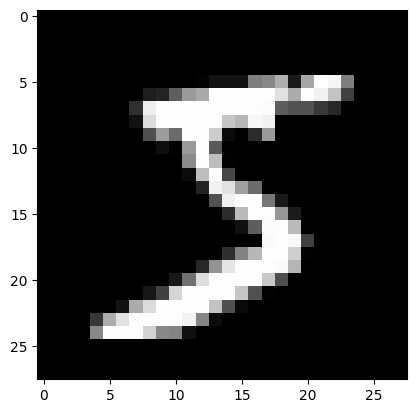

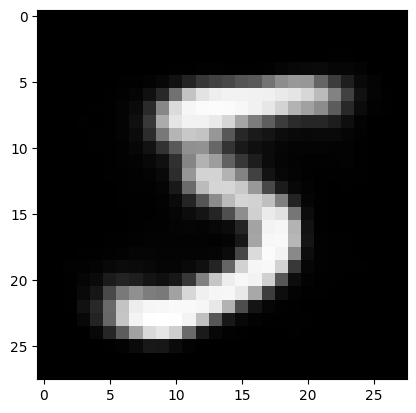

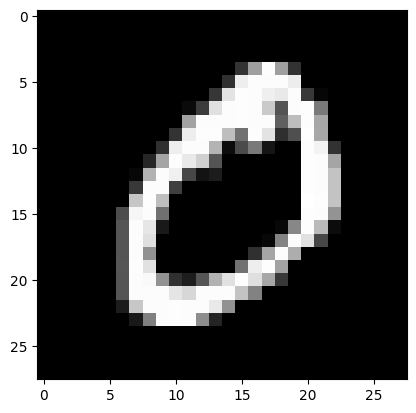

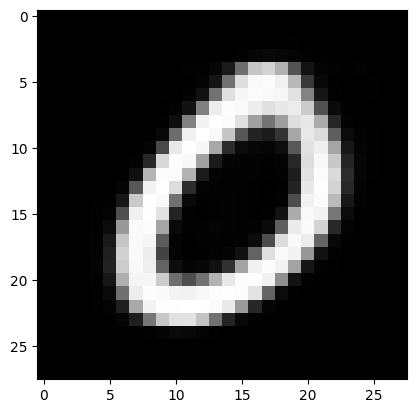

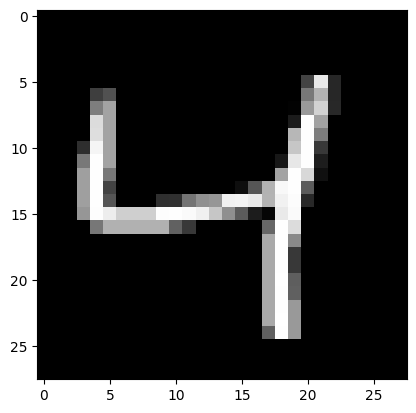

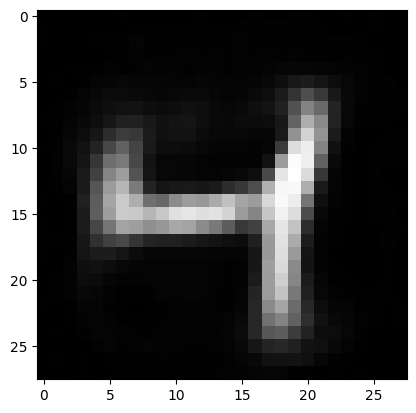

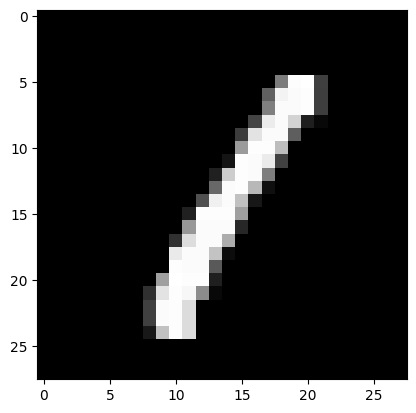

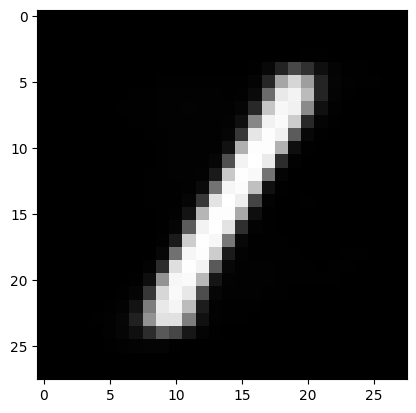

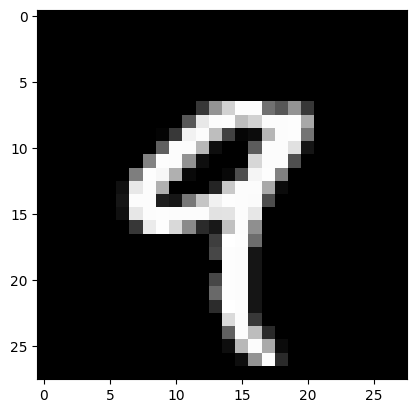

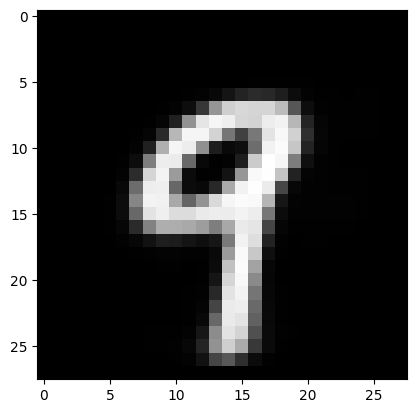

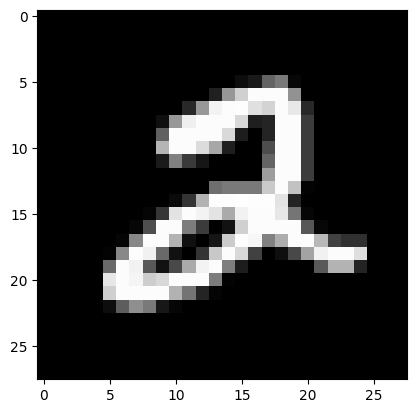

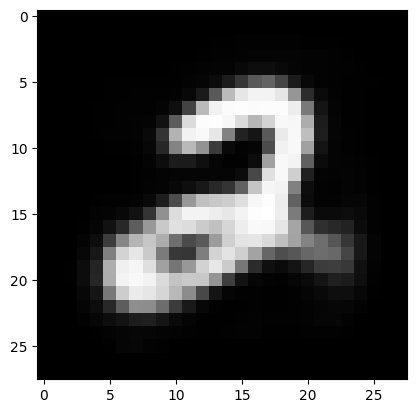

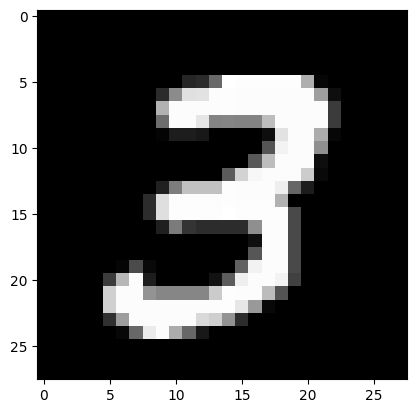

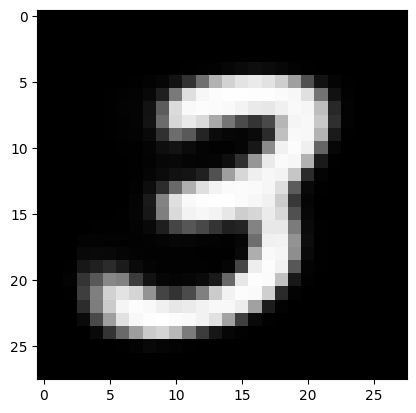

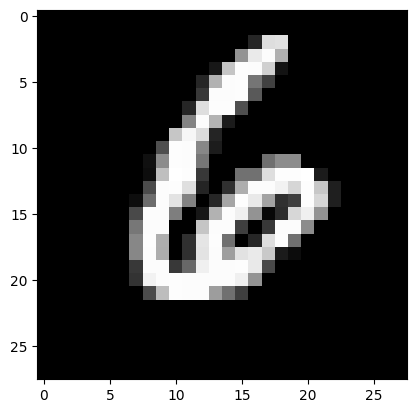

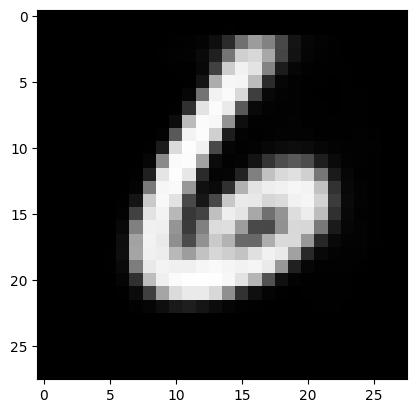

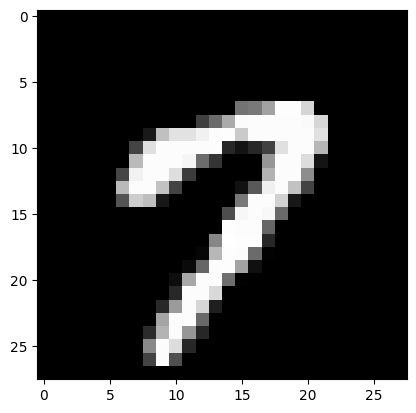

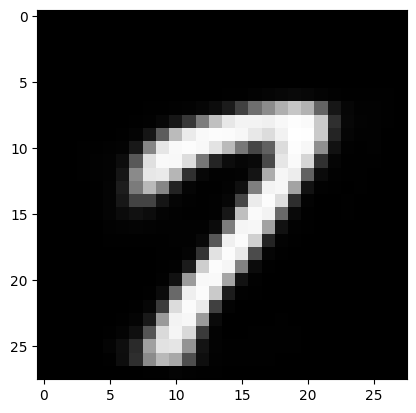

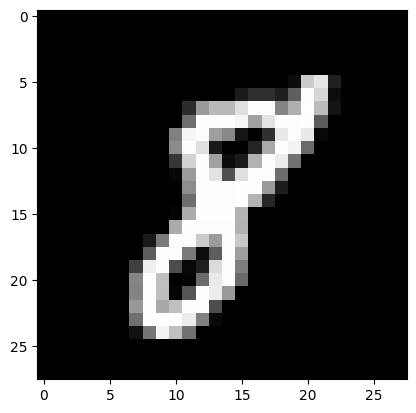

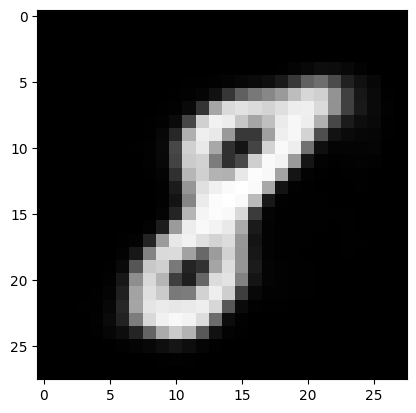

In [34]:
model.load_state_dict(torch.load("./models/" + activation_func + "/pre4", weights_only = True))
model.eval()

for digit in examples:

	image_tensor = examples[digit]
	image = tensor_to_img(image_tensor)
	imgplot = plt.imshow(image, cmap = "gray")
	plt.show()

	with torch.no_grad():
		image_tensor = torch.flatten(image_tensor).to(device)

		e1 = model.encoder_layer_1(image_tensor)
		e2 = model.encoder_layer_2(e1)
		e3 = model.encoder_layer_3(e2)
		e4 = model.encoder_layer_4(e3)

		e4_reconstructed = model.decoder_layer_4(e4)
		e3_reconstructed = model.decoder_layer_3(e4_reconstructed)
		e2_reconstructed = model.decoder_layer_2(e3_reconstructed)
		e1_reconstructed = model.decoder_layer_1(e2_reconstructed)

	e1_reconstructed = torch.unflatten(e1_reconstructed, dim = 0, sizes = (28, 28)).to(device)

	image_reconstructed = tensor_to_img(e1_reconstructed)

	imgplot = plt.imshow(image_reconstructed, cmap = "gray")
	plt.show()

#### Autoencoder Layer 5


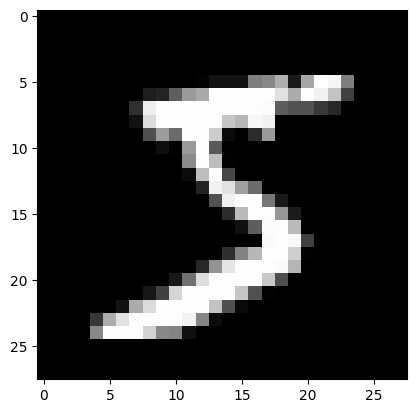

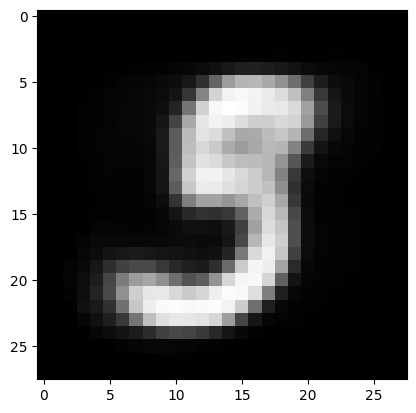

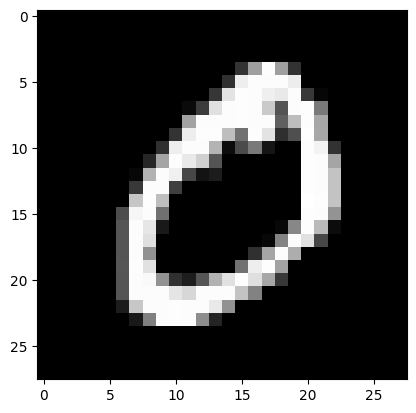

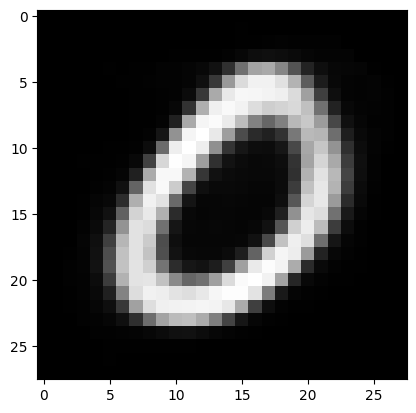

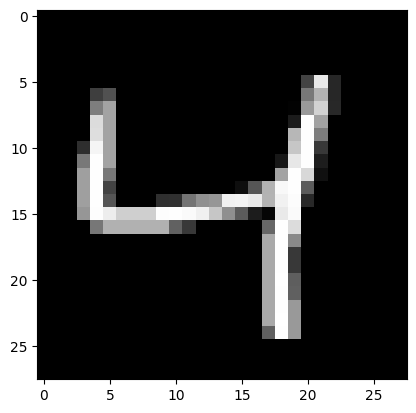

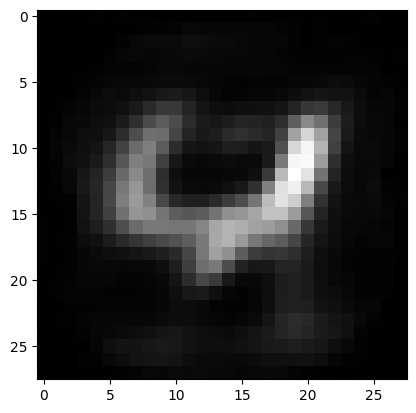

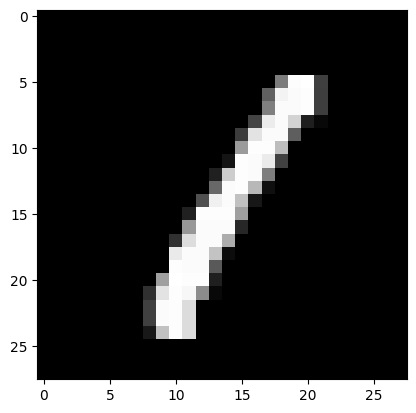

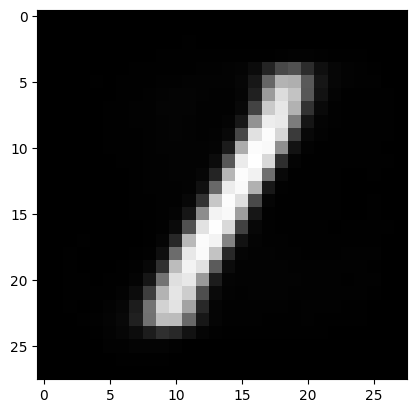

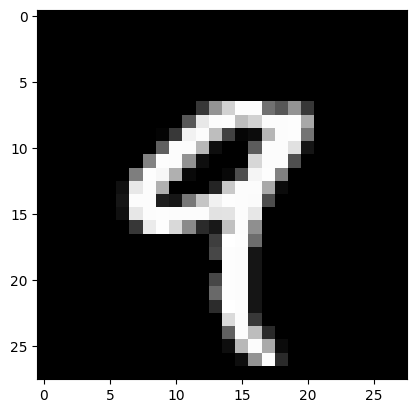

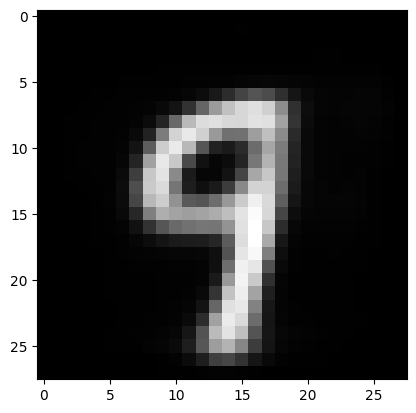

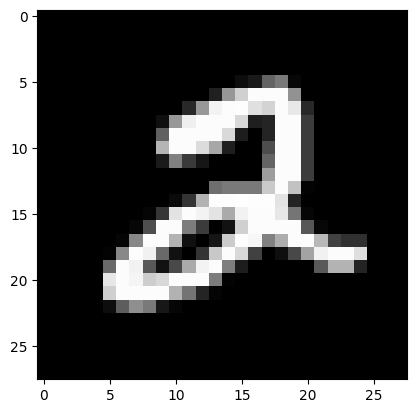

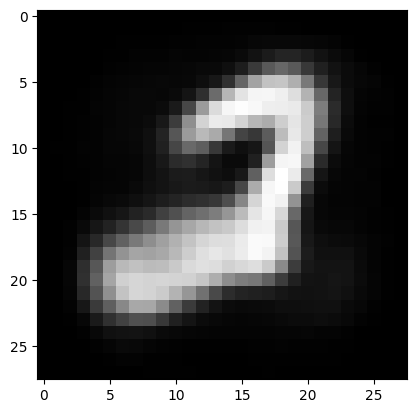

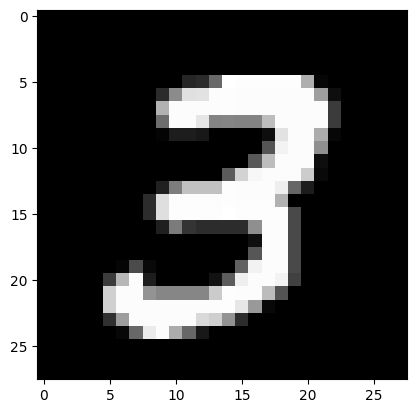

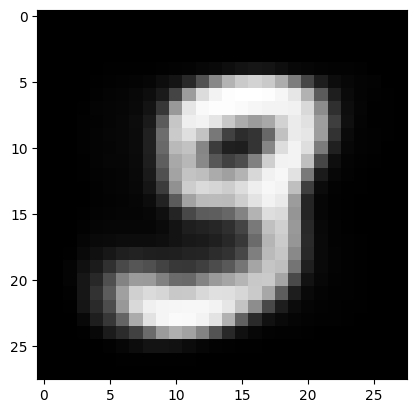

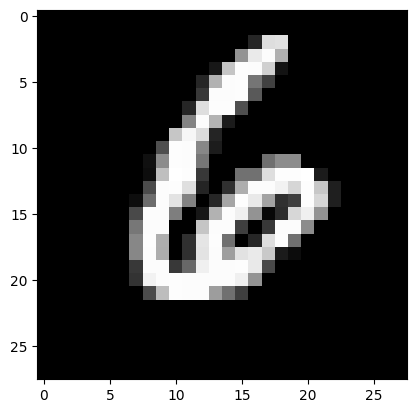

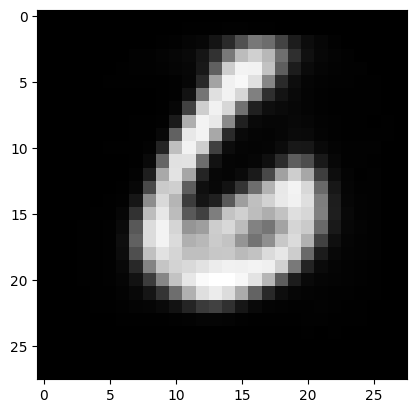

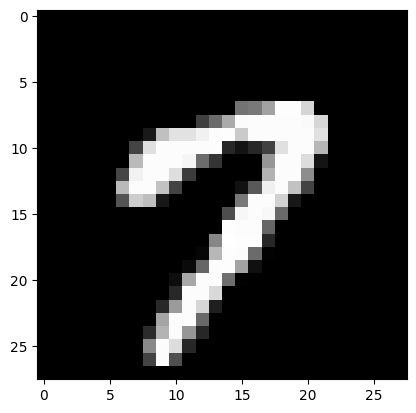

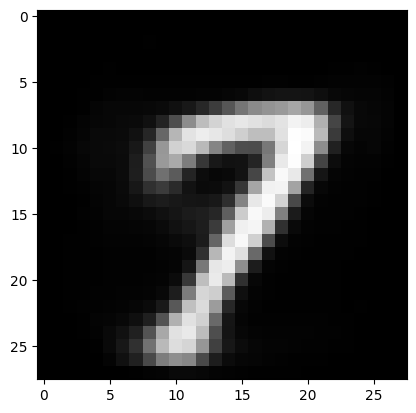

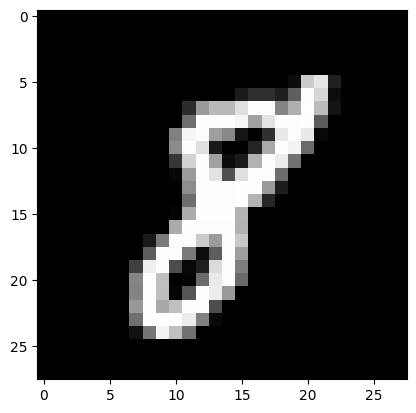

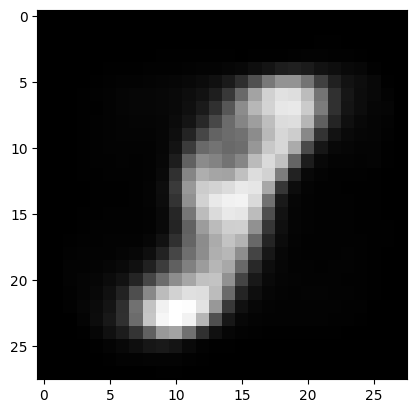

In [35]:
model.load_state_dict(torch.load("./models/" + activation_func + "/pre5", weights_only = True))
model.eval()

for digit in examples:

	image_tensor = examples[digit]
	image = tensor_to_img(image_tensor)
	imgplot = plt.imshow(image, cmap = "gray")
	plt.show()

	with torch.no_grad():
		image_tensor = torch.flatten(image_tensor).to(device)

		e1 = model.encoder_layer_1(image_tensor)
		e2 = model.encoder_layer_2(e1)
		e3 = model.encoder_layer_3(e2)
		e4 = model.encoder_layer_4(e3)
		e5 = model.encoder_layer_5(e4)

		e5_reconstructed = model.decoder_layer_5(e5)
		e4_reconstructed = model.decoder_layer_4(e5_reconstructed)
		e3_reconstructed = model.decoder_layer_3(e4_reconstructed)
		e2_reconstructed = model.decoder_layer_2(e3_reconstructed)
		e1_reconstructed = model.decoder_layer_1(e2_reconstructed)

	e1_reconstructed = torch.unflatten(e1_reconstructed, dim = 0, sizes = (28, 28)).to(device)

	image_reconstructed = tensor_to_img(e1_reconstructed)

	imgplot = plt.imshow(image_reconstructed, cmap = "gray")
	plt.show()

#### Finetuned

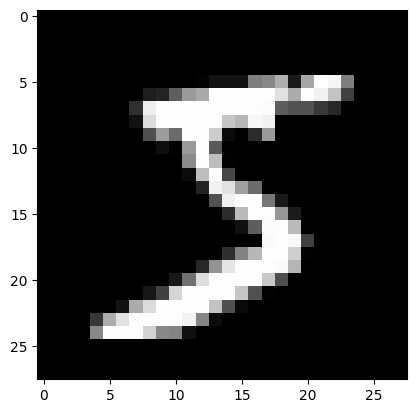

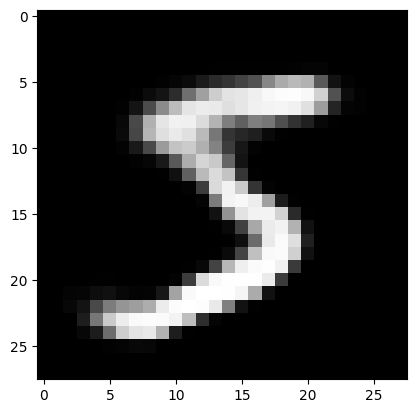

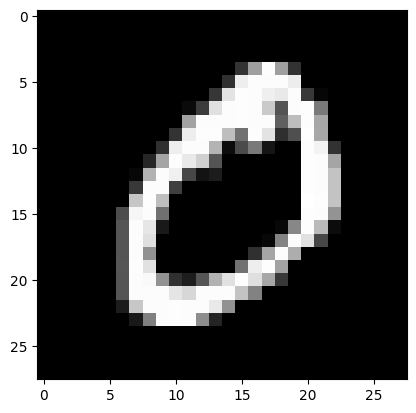

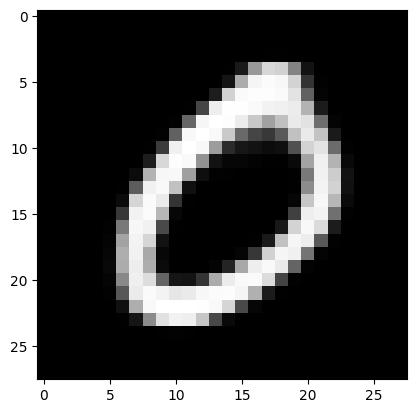

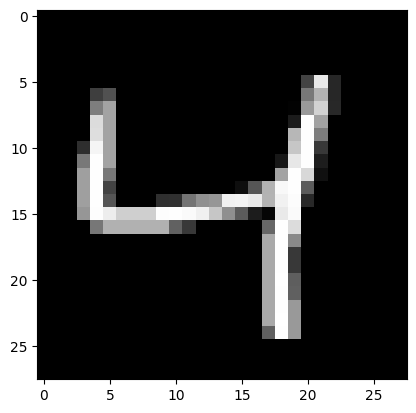

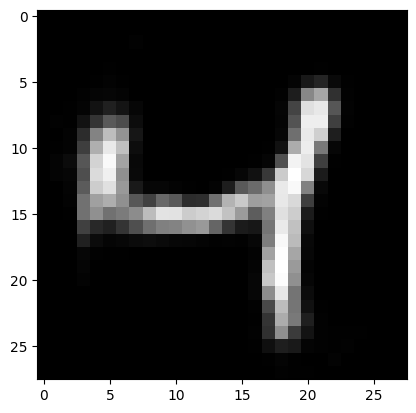

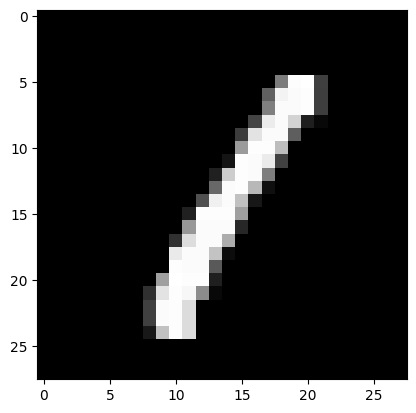

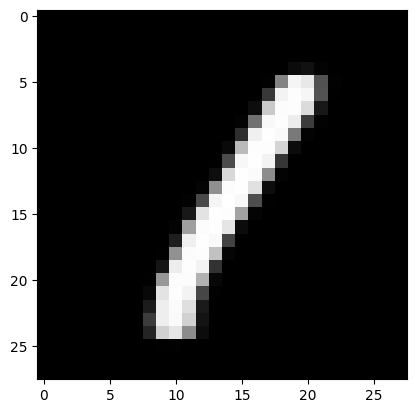

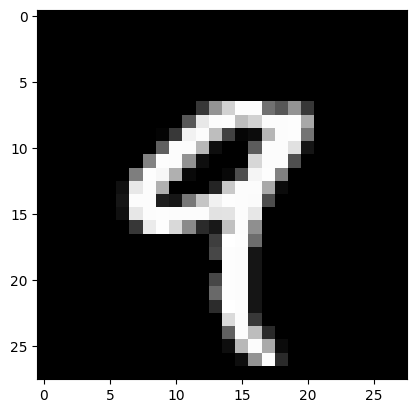

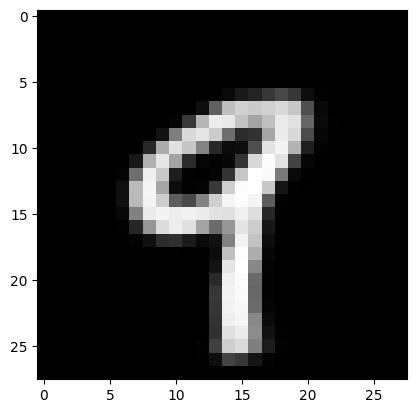

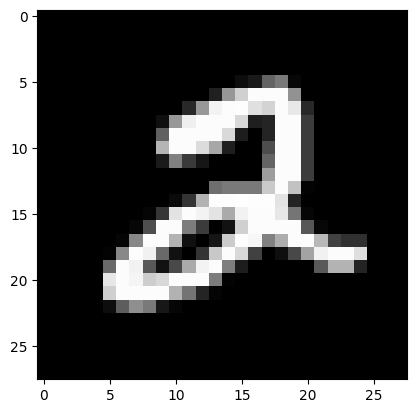

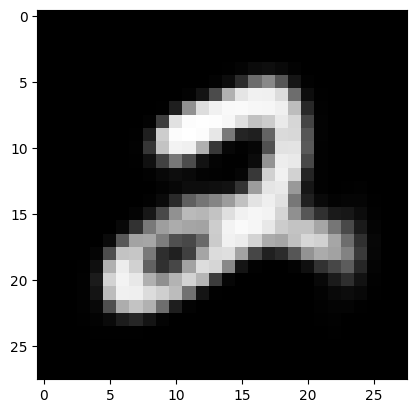

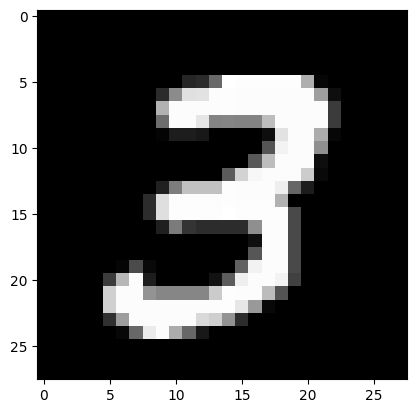

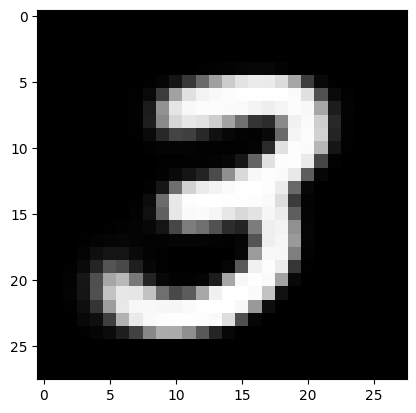

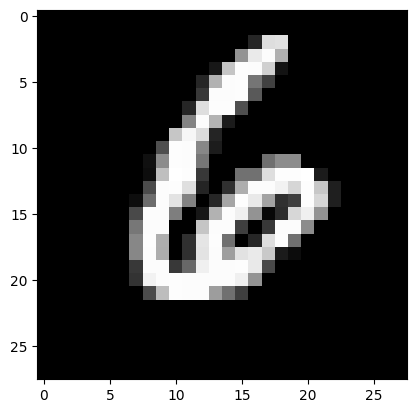

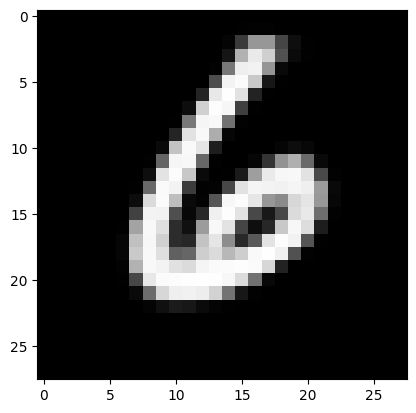

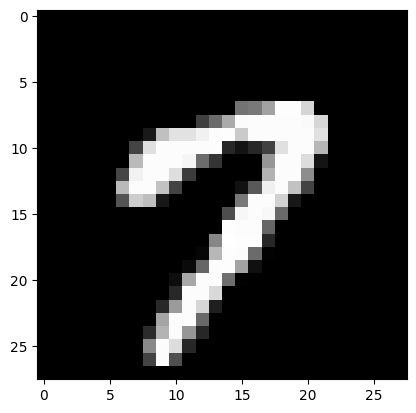

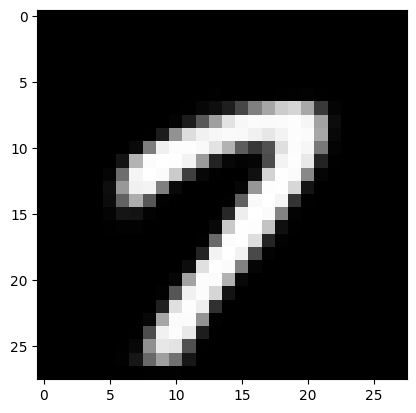

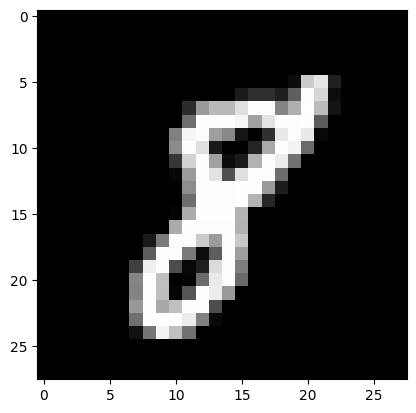

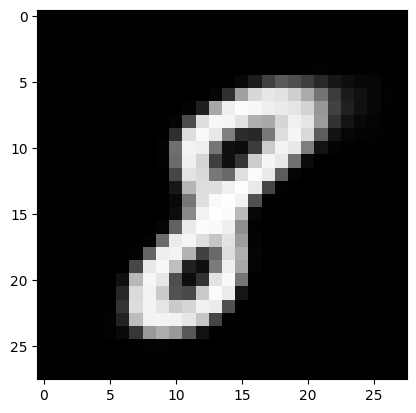

In [36]:
model.load_state_dict(torch.load("./models/" + activation_func + "/finetuned", weights_only = True))
model.eval()

for digit in examples:

	image_tensor = examples[digit]
	image = tensor_to_img(image_tensor)
	imgplot = plt.imshow(image, cmap = "gray")
	plt.show()

	with torch.no_grad():
		image_tensor = torch.flatten(image_tensor).to(device)
		reconstructed = model(image_tensor)

	reconstructed = torch.unflatten(reconstructed, dim = 0, sizes = (28, 28)).to(device)

	image_reconstructed = tensor_to_img(reconstructed)

	imgplot = plt.imshow(image_reconstructed, cmap = "gray")
	plt.show()

### Clustering

In [37]:
model = SAE()
model.to(device)

model.load_state_dict(
    torch.load("./models/" + activation_func + "/finetuned", weights_only = True)
)

model.eval()

all_z = []
all_labels = []

model.eval()

with torch.no_grad():
    for images, labels in dataloader:
        images = torch.flatten(images, start_dim = 1).to(device)

        z = model.encode(images)

        all_z.append(z.cpu().numpy())
        all_labels.append(labels.numpy())

Z = np.concatenate(all_z, axis = 0)
y_true = np.concatenate(all_labels, axis = 0)

print(Z.shape)
print(y_true.shape)

(70000, 10)
(70000,)


In [38]:
from sklearn.cluster import KMeans

n_clusters = 10

kmeans = KMeans(
    n_clusters = n_clusters,
    n_init = 20,
    random_state = 42
)

cluster_labels = kmeans.fit_predict(Z)

centroids = kmeans.cluster_centers_

print(cluster_labels.shape)
print(centroids.shape)

(70000,)
(10, 10)


In [39]:
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

ari = adjusted_rand_score(y_true, cluster_labels)
nmi = normalized_mutual_info_score(y_true, cluster_labels)

print(f"ARI: {ari:.4f}")
print(f"NMI: {nmi:.4f}")

ARI: 0.6489
NMI: 0.7086


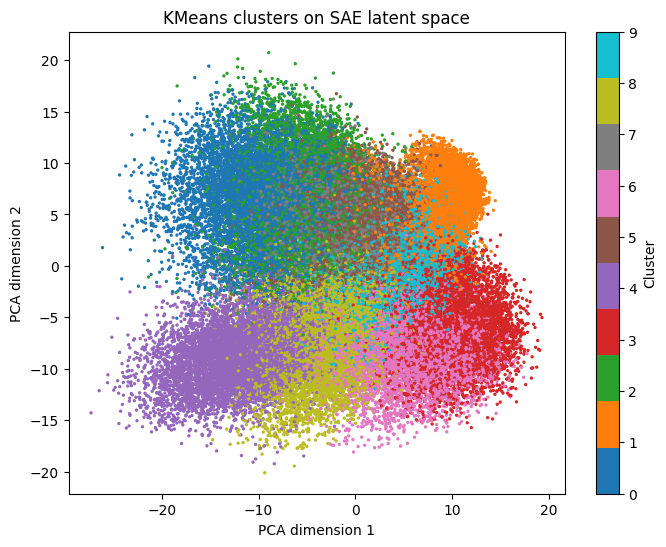

In [ ]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components = 2, random_state = 42)
Z_2d = pca.fit_transform(Z)

plt.figure(figsize = (8, 6))
plt.scatter(
    Z_2d[:, 0],
    Z_2d[:, 1],
    c = cluster_labels,
    s = 2,
    cmap = "tab10"
)
plt.title("KMeans clusters on SAE latent space")
plt.xlabel("PCA dimension 1")
plt.ylabel("PCA dimension 2")
plt.colorbar(label = "Cluster")
plt.show()

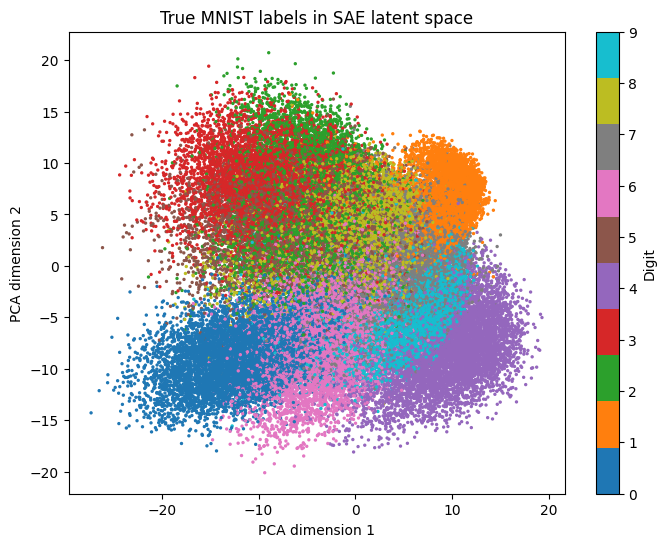

In [ ]:
plt.figure(figsize = (8, 6))
plt.scatter(
    Z_2d[:, 0],
    Z_2d[:, 1],
    c = y_true,
    s = 2,
    cmap = "tab10"
)
plt.title("True MNIST labels in SAE latent space")
plt.xlabel("PCA dimension 1")
plt.ylabel("PCA dimension 2")
plt.colorbar(label = "Digit")
plt.show()

In [ ]:
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import numpy as np

tsne = TSNE(
    n_components = 2,
    perplexity = 30,
    learning_rate = "auto",
    init = "pca",
    random_state = 42
)

Z_tsne = tsne.fit_transform(Z)

print(Z_tsne.shape)

(70000, 2)


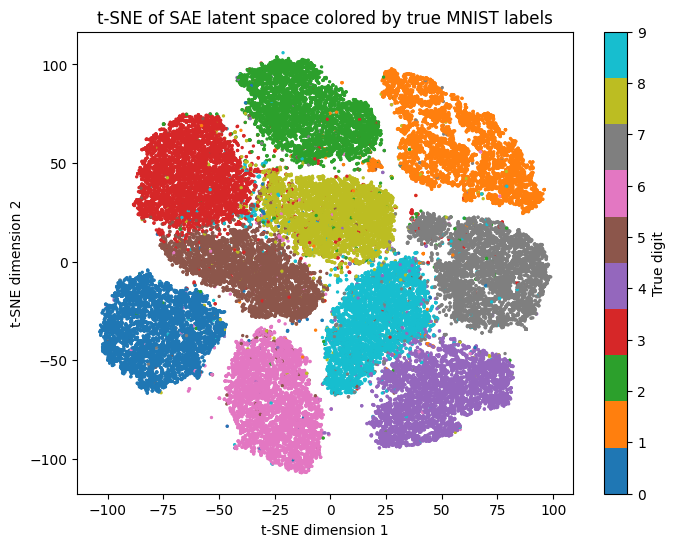

In [ ]:
plt.figure(figsize = (8, 6))
plt.scatter(
    Z_tsne[:, 0],
    Z_tsne[:, 1],
    c = y_true,
    s = 2,
    cmap = "tab10"
)
plt.title("t-SNE of SAE latent space colored by true MNIST labels")
plt.xlabel("t-SNE dimension 1")
plt.ylabel("t-SNE dimension 2")
plt.colorbar(label = "True digit")
plt.show()

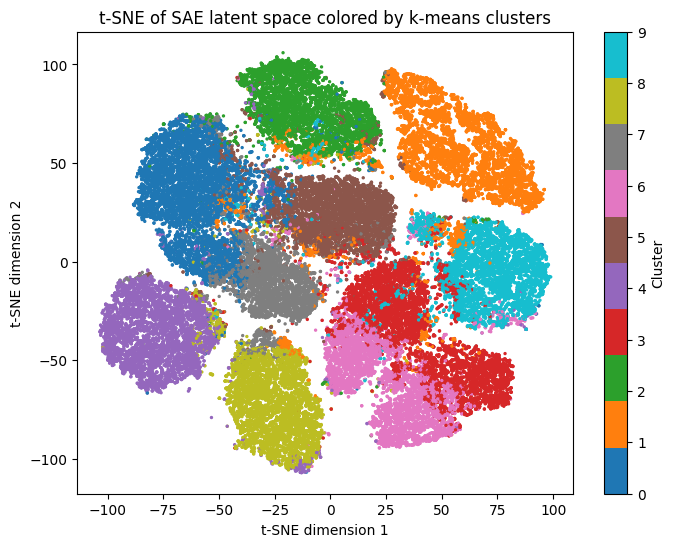

In [ ]:
plt.figure(figsize = (8, 6))
plt.scatter(
    Z_tsne[:, 0],
    Z_tsne[:, 1],
    c = cluster_labels,
    s = 2,
    cmap = "tab10"
)
plt.title("t-SNE of SAE latent space colored by k-means clusters")
plt.xlabel("t-SNE dimension 1")
plt.ylabel("t-SNE dimension 2")
plt.colorbar(label = "Cluster")
plt.show()

In [45]:
from scipy.optimize import linear_sum_assignment
from sklearn.metrics import confusion_matrix
import numpy as np

def clustering_accuracy(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    row_ind, col_ind = linear_sum_assignment(-cm)
    return cm[row_ind, col_ind].sum() / y_true.size

acc = clustering_accuracy(y_true, cluster_labels)

print(f"Clustering Accuracy: {acc:.4f}")

Clustering Accuracy: 0.7837


In [ ]:
import pandas as pd

cluster_digit_counts = pd.crosstab(
    pd.Series(cluster_labels, name = "Cluster"),
    pd.Series(y_true, name = "True digit")
)

cluster_digit_counts

True digit,0,1,2,3,4,5,6,7,8,9
Cluster,,,,,,,,,,
0,14,22,97,6161,0,1992,8,7,445,91
1,6,7698,409,153,78,86,173,471,203,153
2,4,44,5941,143,9,8,1,44,16,14
3,38,12,30,5,3350,43,14,440,211,3720
4,6452,0,66,12,10,70,192,35,48,54
5,30,69,184,275,2,85,37,27,5586,65
6,4,11,24,16,3338,27,13,297,72,2542
7,87,16,27,264,6,3908,356,1,175,22
8,253,2,60,2,28,83,6081,0,42,11


In [ ]:
cluster_digit_percentages = cluster_digit_counts.div(
    cluster_digit_counts.sum(axis = 1),
    axis = 0
)

cluster_digit_percentages.round(2)

True digit,0,1,2,3,4,5,6,7,8,9
Cluster,,,,,,,,,,
0,0.00,0.00,0.01,0.70,0.00,0.23,0.00,0.00,0.05,0.01
1,0.00,0.82,0.04,0.02,0.01,0.01,0.02,0.05,0.02,0.02
2,0.00,0.01,0.95,0.02,0.00,0.00,0.00,0.01,0.00,0.00
3,0.00,0.00,0.00,0.00,0.43,0.01,0.00,0.06,0.03,0.47
4,0.93,0.00,0.01,0.00,0.00,0.01,0.03,0.01,0.01,0.01
5,0.00,0.01,0.03,0.04,0.00,0.01,0.01,0.00,0.88,0.01
6,0.00,0.00,0.00,0.00,0.53,0.00,0.00,0.05,0.01,0.40
7,0.02,0.00,0.01,0.05,0.00,0.80,0.07,0.00,0.04,0.00
8,0.04,0.00,0.01,0.00,0.00,0.01,0.93,0.00,0.01,0.00


## Larger Latent Space

### Train

In [48]:
activation_func = "larger_latent_space"

class SAE(nn.Module):
	def __init__(self):
		super().__init__()

		self.encoder_layer_1 =  nn.Sequential(
			nn.Dropout(0.2),
			nn.Linear(28 * 28, 500),
			nn.ReLU(),
		)

		self.decoder_layer_1 =  nn.Sequential(
			nn.Dropout(0.2),
			nn.Linear(500, 28 * 28),
			nn.Sigmoid(),
		)

		self.encoder_layer_2 =  nn.Sequential(
			nn.Dropout(0.2),
			nn.Linear(500, 500),
			nn.ReLU(),
		)

		self.decoder_layer_2 =  nn.Sequential(
			nn.Dropout(0.2),
			nn.Linear(500, 500),
			nn.ReLU(),
		)

		self.encoder_layer_3 =  nn.Sequential(
			nn.Dropout(0.2),
			nn.Linear(500, 2000),
			nn.ReLU(),
		)

		self.decoder_layer_3 =  nn.Sequential(
			nn.Dropout(0.2),
			nn.Linear(2000, 500),
			nn.ReLU(),
		)

		self.encoder_layer_4 =  nn.Sequential(
			nn.Dropout(0.2),
			nn.Linear(2000, 20),
		)

		self.decoder_layer_4 =  nn.Sequential(
			nn.Dropout(0.2),
			nn.Linear(20, 2000),
			nn.ReLU(),
		)

	def forward(self, x):
		encoded = self.encoder_layer_4(
					self.encoder_layer_3(
						self.encoder_layer_2(
							self.encoder_layer_1(x)
						)
					)
				)

		decoded = self.decoder_layer_1(
					self.decoder_layer_2(
						self.decoder_layer_3(
							self.decoder_layer_4(encoded)
						)
					)
				)
		return decoded
	
	def encode(self, x):
		e1 = self.encoder_layer_1(x)
		e2 = self.encoder_layer_2(e1)
		e3 = self.encoder_layer_3(e2)
		z = self.encoder_layer_4(e3)
		return z

In [ ]:
model = SAE()
model.to(device)

# Pretraining
pretrain_epochs = 200

# Pretrain layer 1

loss_function = nn.BCELoss()

optimizer = optim.SGD(
    list(model.encoder_layer_1.parameters()) + 
    list(model.decoder_layer_1.parameters()),
    lr = 0.1, 
    momentum = 0.9
    )

scheduler = optim.lr_scheduler.StepLR(
    optimizer, 
    step_size = 20000, #Amount of iterations the scheduler will update the lr
    gamma = 0.1 #by how much the scheduler will divide the current lr
    )

best_loss = (float("inf"), 0)

model.train()
for epoch in range(pretrain_epochs):
    batch_losses = []
    
    for images, _ in dataloader:

        images = torch.flatten(images, start_dim = 1).to(device)
        e1 = model.encoder_layer_1(images)
        e1_reconstructed = model.decoder_layer_1(e1)
        loss = loss_function(e1_reconstructed, images)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        scheduler.step()

        batch_losses.append(loss.item())
    
    epoch_loss = sum(batch_losses) / len(batch_losses)

    print(f"Pretrain 1: Epoch {epoch+1}/{pretrain_epochs}, Loss: {epoch_loss:.6f}")

    if epoch_loss <= best_loss[0]:
        best_loss = (epoch_loss, epoch + 1)
        torch.save(model.state_dict(), "./models/" + activation_func + "/pre1")

        print(f"Best Pretrain 1 Epoch: {best_loss[1]}/{pretrain_epochs}, Loss: {best_loss[0]:.6f}")

# Pretrain layer 2

model.load_state_dict(torch.load("./models/" + activation_func + "/pre1", weights_only = True))

loss_function = nn.MSELoss()

optimizer = optim.SGD(
    list(model.encoder_layer_2.parameters()) + 
    list(model.decoder_layer_2.parameters()),
    lr = 0.1, 
    momentum = 0.9
    )

scheduler = optim.lr_scheduler.StepLR(
    optimizer, 
    step_size = 20000, #Amount of iterations the scheduler will update the lr
    gamma = 0.1 #by how much the scheduler will divide the current lr
    )

best_loss = (float("inf"), 0)

# Deactivate Dropout because Layer is Frozen
model.encoder_layer_1.eval()

for epoch in range(pretrain_epochs):
    batch_losses = []

    for images, _ in dataloader:

        images = torch.flatten(images, start_dim = 1).to(device)

        with torch.no_grad():
            e1 = model.encoder_layer_1(images)
        
        e2 = model.encoder_layer_2(e1)
        e1_reconstructed = model.decoder_layer_2(e2)

        loss = loss_function(e1_reconstructed, e1)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        scheduler.step()

        batch_losses.append(loss.item())
    
    epoch_loss = sum(batch_losses) / len(batch_losses)

    print(f"Pretrain 2: Epoch {epoch+1}/{pretrain_epochs}, Loss: {epoch_loss:.6f}")

    if epoch_loss <= best_loss[0]:
        best_loss = (epoch_loss, epoch + 1)
        torch.save(model.state_dict(), "./models/" + activation_func + "/pre2")

        print(f"Best Pretrain 2 Epoch: {best_loss[1]}/{pretrain_epochs}, Loss: {best_loss[0]:.6f}")


# Pretrain layer 3

model.load_state_dict(torch.load("./models/" + activation_func + "/pre2", weights_only = True))

loss_function = nn.MSELoss()

optimizer = optim.SGD(
    list(model.encoder_layer_3.parameters()) + 
    list(model.decoder_layer_3.parameters()),
    lr = 0.1, 
    momentum = 0.9
    )

scheduler = optim.lr_scheduler.StepLR(
    optimizer, 
    step_size = 20000, #Amount of iterations the scheduler will update the lr
    gamma = 0.1 #by how much the scheduler will divide the current lr
    )

best_loss = (float("inf"), 0)

# Deactivate Dropout because Layer is Frozen
model.encoder_layer_1.eval()
model.encoder_layer_2.eval()

for epoch in range(pretrain_epochs):
    batch_losses = []

    for images, _ in dataloader:

        images = torch.flatten(images, start_dim = 1).to(device)

        with torch.no_grad():
            e1 = model.encoder_layer_1(images)
            e2 = model.encoder_layer_2(e1)
        
        e3 = model.encoder_layer_3(e2)
        e2_reconstructed = model.decoder_layer_3(e3)

        loss = loss_function(e2_reconstructed, e2)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        scheduler.step()

        batch_losses.append(loss.item())
    
    epoch_loss = sum(batch_losses) / len(batch_losses)

    print(f"Pretrain 3: Epoch {epoch+1}/{pretrain_epochs}, Loss: {epoch_loss:.6f}")

    if epoch_loss <= best_loss[0]:
        best_loss = (epoch_loss, epoch + 1)
        torch.save(model.state_dict(), "./models/" + activation_func + "/pre3")

        print(f"Best Pretrain 3 Epoch: {best_loss[1]}/{pretrain_epochs}, Loss: {best_loss[0]:.6f}")


# Pretrain layer 4

model.load_state_dict(torch.load("./models/" + activation_func + "/pre3", weights_only = True))

loss_function = nn.MSELoss()

optimizer = optim.SGD(
    list(model.encoder_layer_4.parameters()) + 
    list(model.decoder_layer_4.parameters()),
    lr = 0.1, 
    momentum = 0.9
    )

scheduler = optim.lr_scheduler.StepLR(
    optimizer, 
    step_size = 20000, #Amount of iterations the scheduler will update the lr
    gamma = 0.1 #by how much the scheduler will divide the current lr
    )

best_loss = (float("inf"), 0)

# Deactivate Dropout because Layer is Frozen
model.encoder_layer_1.eval()
model.encoder_layer_2.eval()
model.encoder_layer_3.eval()

for epoch in range(pretrain_epochs):
    batch_losses = []

    for images, _ in dataloader:

        images = torch.flatten(images, start_dim = 1).to(device)

        with torch.no_grad():
            e1 = model.encoder_layer_1(images)
            e2 = model.encoder_layer_2(e1)
            e3 = model.encoder_layer_3(e2)
        
        e4 = model.encoder_layer_4(e3)
        e3_reconstructed = model.decoder_layer_4(e4)

        loss = loss_function(e3_reconstructed, e3)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        scheduler.step()

        batch_losses.append(loss.item())
    
    epoch_loss = sum(batch_losses) / len(batch_losses)

    print(f"Pretrain 4: Epoch {epoch+1}/{pretrain_epochs}, Loss: {epoch_loss:.6f}")

    if epoch_loss <= best_loss[0]:
        best_loss = (epoch_loss, epoch + 1)
        torch.save(model.state_dict(), "./models/" + activation_func + "/pre4")

        print(f"Best Pretrain 4 Epoch: {best_loss[1]}/{pretrain_epochs}, Loss: {best_loss[0]:.6f}")

Pretrain 1: Epoch 1/200, Loss: 0.341388
Best Pretrain 1 Epoch: 1/200, Loss: 0.341388
Pretrain 1: Epoch 2/200, Loss: 0.243242
Best Pretrain 1 Epoch: 2/200, Loss: 0.243242
Pretrain 1: Epoch 3/200, Loss: 0.213956
Best Pretrain 1 Epoch: 3/200, Loss: 0.213956
Pretrain 1: Epoch 4/200, Loss: 0.195872
Best Pretrain 1 Epoch: 4/200, Loss: 0.195872
Pretrain 1: Epoch 5/200, Loss: 0.183774
Best Pretrain 1 Epoch: 5/200, Loss: 0.183774
Pretrain 1: Epoch 6/200, Loss: 0.174553
Best Pretrain 1 Epoch: 6/200, Loss: 0.174553
Pretrain 1: Epoch 7/200, Loss: 0.167088
Best Pretrain 1 Epoch: 7/200, Loss: 0.167088
Pretrain 1: Epoch 8/200, Loss: 0.160886
Best Pretrain 1 Epoch: 8/200, Loss: 0.160886
Pretrain 1: Epoch 9/200, Loss: 0.155557
Best Pretrain 1 Epoch: 9/200, Loss: 0.155557
Pretrain 1: Epoch 10/200, Loss: 0.150915
Best Pretrain 1 Epoch: 10/200, Loss: 0.150915
Pretrain 1: Epoch 11/200, Loss: 0.146899
Best Pretrain 1 Epoch: 11/200, Loss: 0.146899
Pretrain 1: Epoch 12/200, Loss: 0.143336
Best Pretrain 1 Epoc

In [ ]:
model.load_state_dict(torch.load("./models/" + activation_func + "/pre4", weights_only = True))

train_epochs = 400

loss_function = nn.BCELoss()

optimizer = optim.SGD(
    model.parameters(),
    lr = 0.1, 
    momentum = 0.9
    )

scheduler = optim.lr_scheduler.StepLR(
    optimizer, 
    step_size = 20000, #Amount of iterations the scheduler will update the lr
    gamma = 0.1 #by how much the scheduler will divide the current lr
    )

best_loss = (float("inf"), 0)

model.eval() # deactivate all dropout
for epoch in range(train_epochs):
    batch_losses = []
    
    for images, _ in dataloader:

        images = torch.flatten(images, start_dim = 1).to(device)
        reconstructed = model(images)
        loss = loss_function(reconstructed, images)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        scheduler.step()

        batch_losses.append(loss.item())
    
    epoch_loss = sum(batch_losses) / len(batch_losses)

    print(f"Finetune: Epoch {epoch+1}/{train_epochs}, Loss: {epoch_loss:.6f}")

    if epoch_loss <= best_loss[0]:
        best_loss = (epoch_loss, epoch + 1)
        torch.save(model.state_dict(), "./models/" + activation_func + "/finetuned")

        print(f"Best Finetune Epoch: {best_loss[1]}/{train_epochs}, Loss: {best_loss[0]:.6f}")

Finetune: Epoch 1/400, Loss: 0.116016
Best Finetune Epoch: 1/400, Loss: 0.116016
Finetune: Epoch 2/400, Loss: 0.102536
Best Finetune Epoch: 2/400, Loss: 0.102536
Finetune: Epoch 3/400, Loss: 0.098708
Best Finetune Epoch: 3/400, Loss: 0.098708
Finetune: Epoch 4/400, Loss: 0.096422
Best Finetune Epoch: 4/400, Loss: 0.096422
Finetune: Epoch 5/400, Loss: 0.094794
Best Finetune Epoch: 5/400, Loss: 0.094794
Finetune: Epoch 6/400, Loss: 0.093550
Best Finetune Epoch: 6/400, Loss: 0.093550
Finetune: Epoch 7/400, Loss: 0.092544
Best Finetune Epoch: 7/400, Loss: 0.092544
Finetune: Epoch 8/400, Loss: 0.091739
Best Finetune Epoch: 8/400, Loss: 0.091739
Finetune: Epoch 9/400, Loss: 0.091032
Best Finetune Epoch: 9/400, Loss: 0.091032
Finetune: Epoch 10/400, Loss: 0.090413
Best Finetune Epoch: 10/400, Loss: 0.090413
Finetune: Epoch 11/400, Loss: 0.089858
Best Finetune Epoch: 11/400, Loss: 0.089858
Finetune: Epoch 12/400, Loss: 0.089384
Best Finetune Epoch: 12/400, Loss: 0.089384
Finetune: Epoch 13/400

### Visualize

In [51]:
examples = {}

for image, label in dataset:
    label = int(label)
    if label not in examples:
        examples[label] = image

    if len(examples) == 10:
        break
    
model = SAE()
model.to(device)

SAE(
  (encoder_layer_1): Sequential(
    (0): Dropout(p=0.2, inplace=False)
    (1): Linear(in_features=784, out_features=500, bias=True)
    (2): ReLU()
  )
  (decoder_layer_1): Sequential(
    (0): Dropout(p=0.2, inplace=False)
    (1): Linear(in_features=500, out_features=784, bias=True)
    (2): Sigmoid()
  )
  (encoder_layer_2): Sequential(
    (0): Dropout(p=0.2, inplace=False)
    (1): Linear(in_features=500, out_features=500, bias=True)
    (2): ReLU()
  )
  (decoder_layer_2): Sequential(
    (0): Dropout(p=0.2, inplace=False)
    (1): Linear(in_features=500, out_features=500, bias=True)
    (2): ReLU()
  )
  (encoder_layer_3): Sequential(
    (0): Dropout(p=0.2, inplace=False)
    (1): Linear(in_features=500, out_features=2000, bias=True)
    (2): ReLU()
  )
  (decoder_layer_3): Sequential(
    (0): Dropout(p=0.2, inplace=False)
    (1): Linear(in_features=2000, out_features=500, bias=True)
    (2): ReLU()
  )
  (encoder_layer_4): Sequential(
    (0): Dropout(p=0.2, inplace=F

#### Autoencoder Layer 1


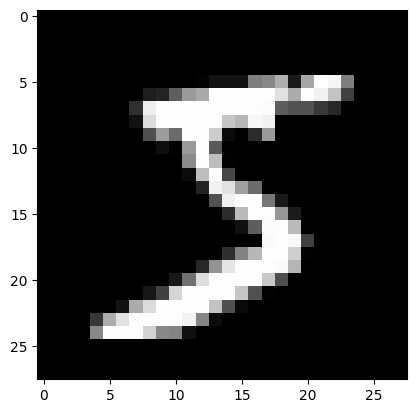

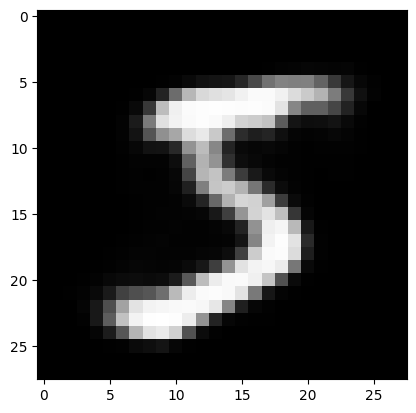

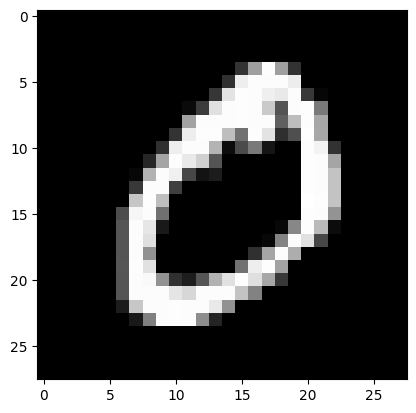

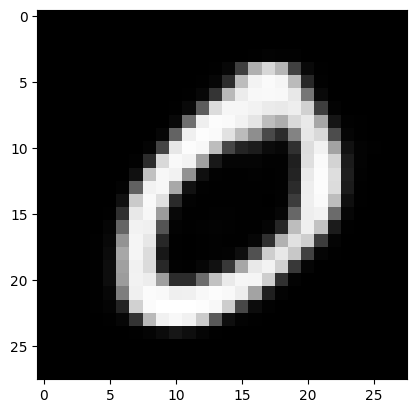

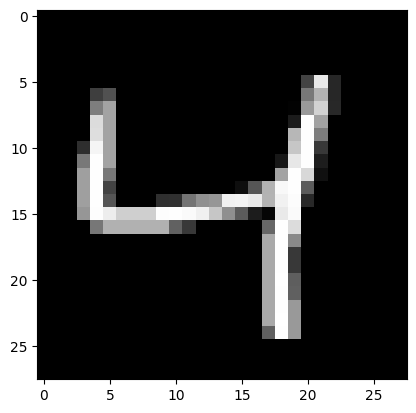

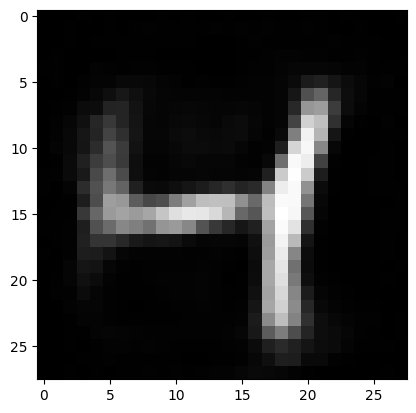

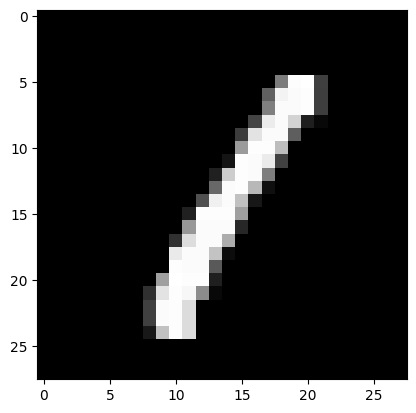

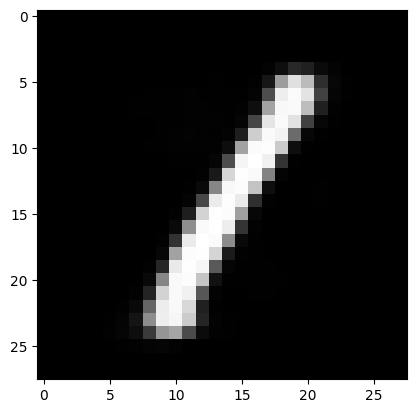

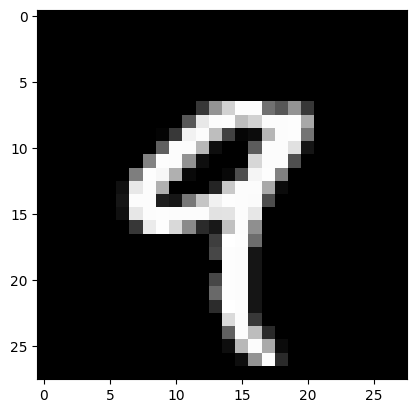

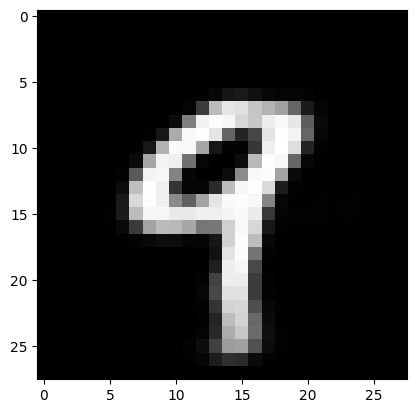

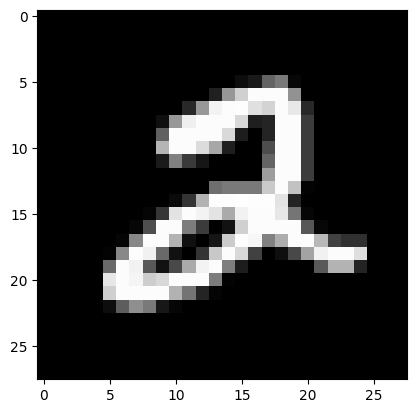

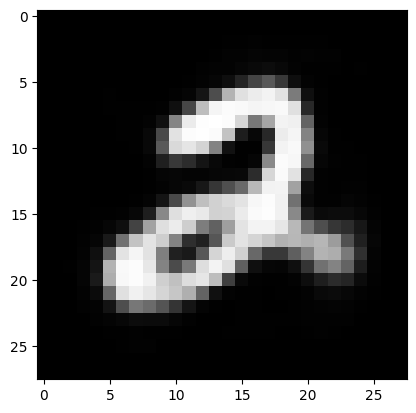

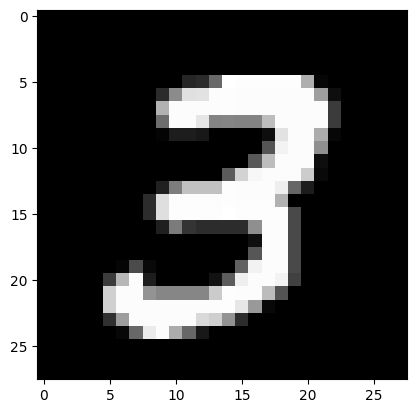

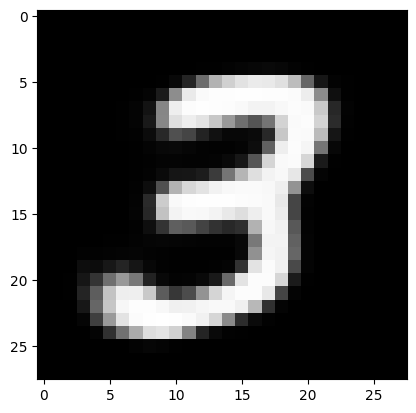

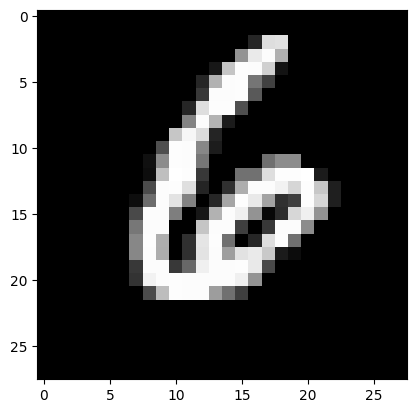

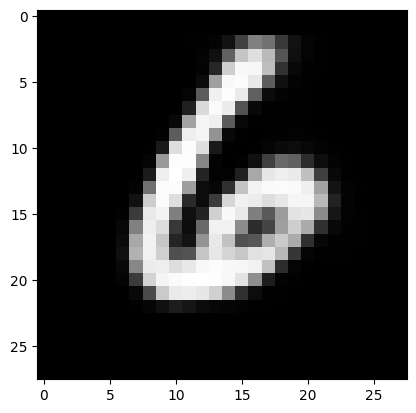

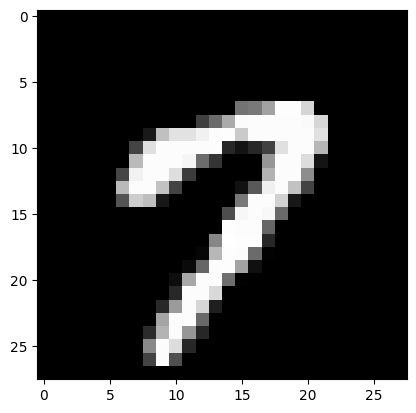

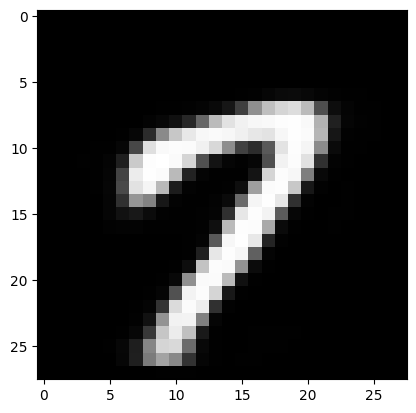

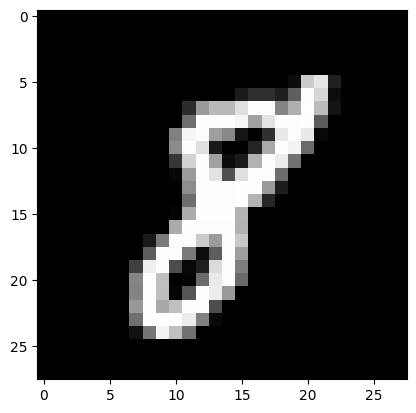

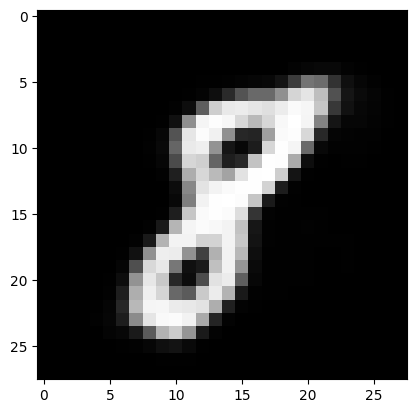

In [52]:
model.load_state_dict(torch.load("./models/" + activation_func + "/pre1", weights_only = True))
model.eval()

for digit in examples:

	image_tensor = examples[digit]
	image = tensor_to_img(image_tensor)
	imgplot = plt.imshow(image, cmap = "gray")
	plt.show()

	with torch.no_grad():
		image_tensor = torch.flatten(image_tensor).to(device)

		e1 = model.encoder_layer_1(image_tensor)
		e1_reconstructed = model.decoder_layer_1(e1)

	e1_reconstructed = torch.unflatten(e1_reconstructed, dim = 0, sizes = (28, 28)).to(device)

	image_reconstructed = tensor_to_img(e1_reconstructed)

	# To view it:
	imgplot = plt.imshow(image_reconstructed, cmap = "gray")
	plt.show()

#### Autoencoder Layer 2


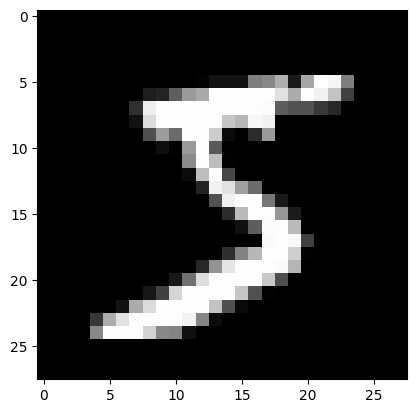

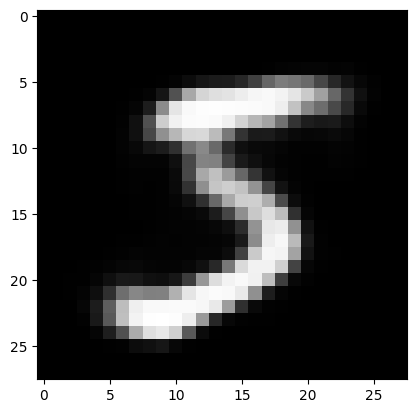

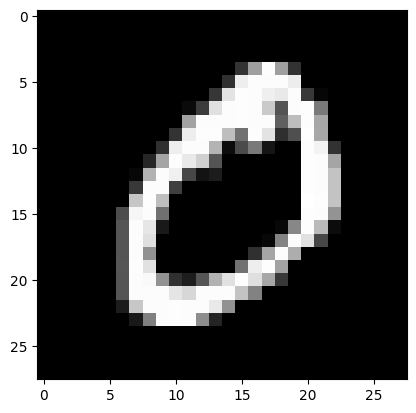

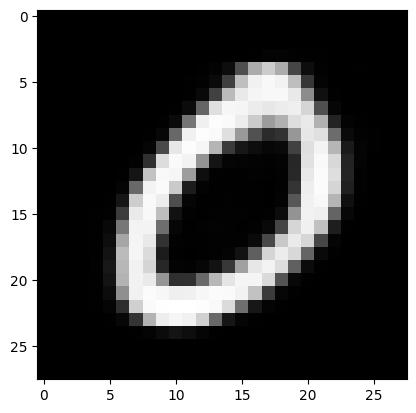

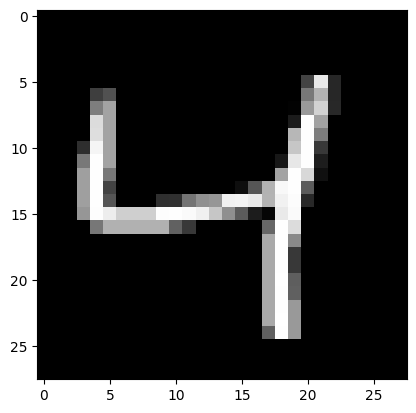

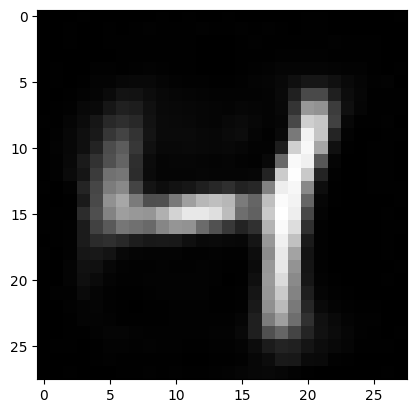

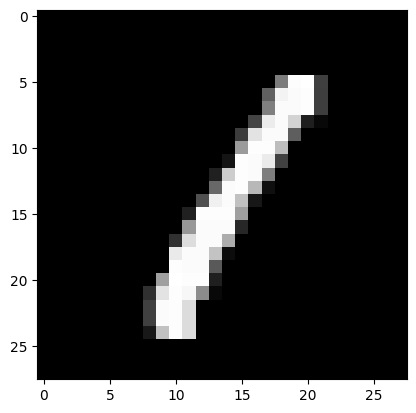

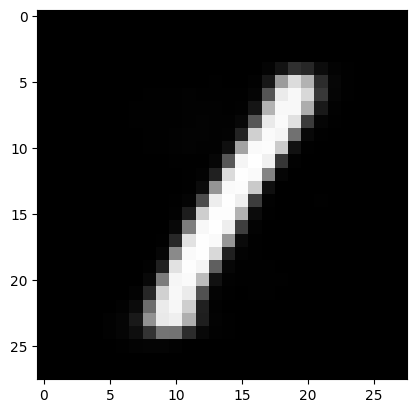

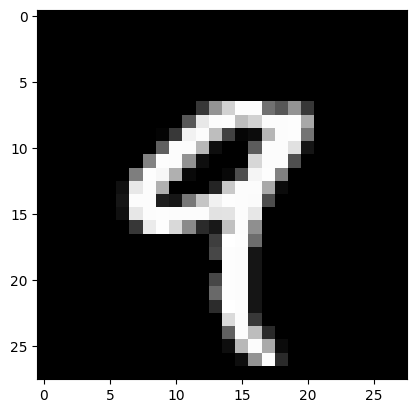

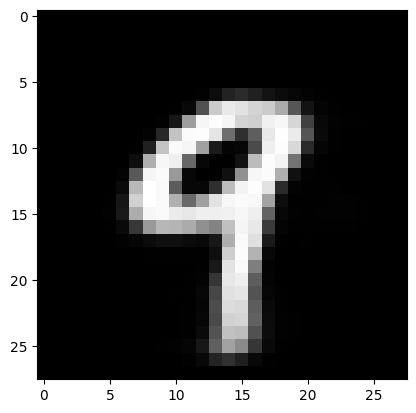

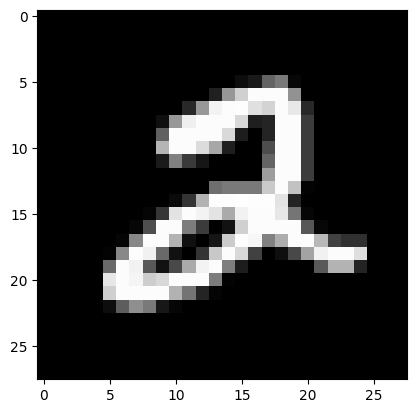

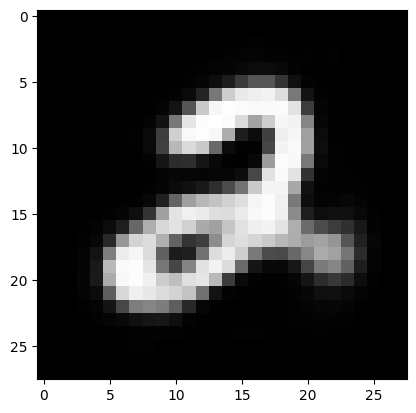

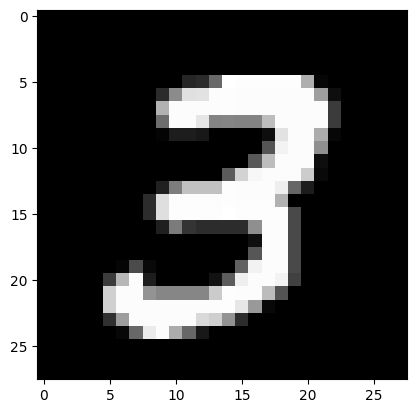

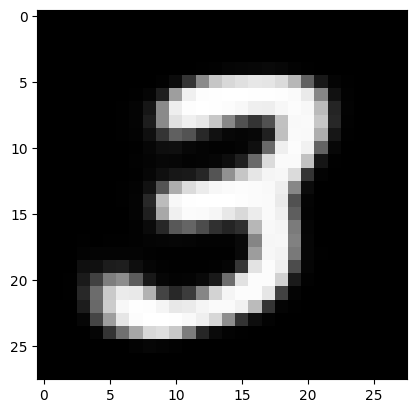

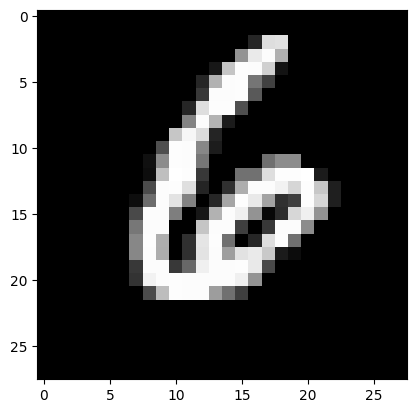

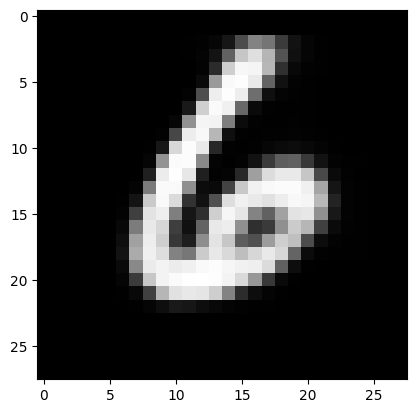

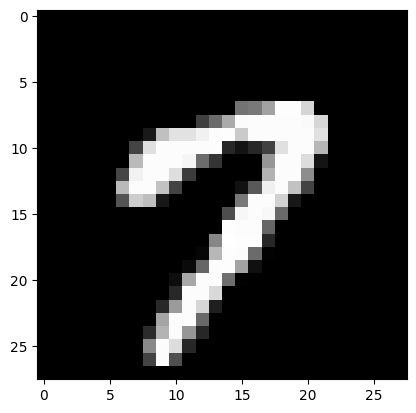

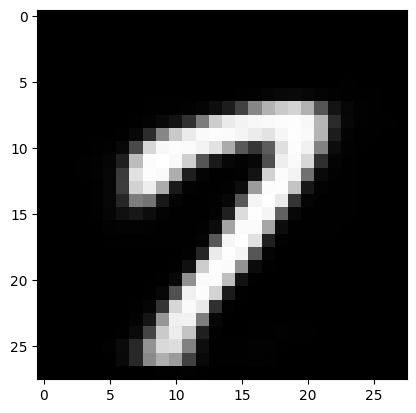

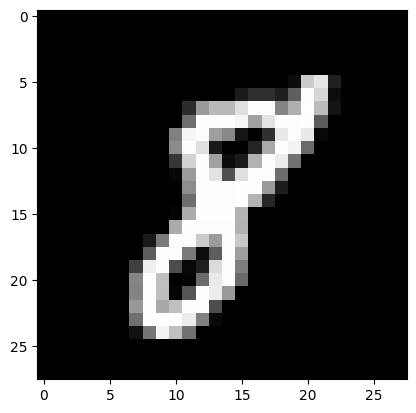

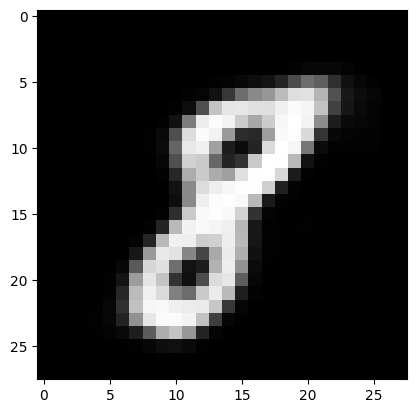

In [53]:
model.load_state_dict(torch.load("./models/" + activation_func + "/pre2", weights_only = True))
model.eval()

for digit in examples:

	image_tensor = examples[digit]
	image = tensor_to_img(image_tensor)
	imgplot = plt.imshow(image, cmap = "gray")
	plt.show()

	with torch.no_grad():
		image_tensor = torch.flatten(image_tensor).to(device)

		e1 = model.encoder_layer_1(image_tensor)
		e2 = model.encoder_layer_2(e1)

		e2_reconstructed = model.decoder_layer_2(e2)
		e1_reconstructed = model.decoder_layer_1(e2_reconstructed)

	e1_reconstructed = torch.unflatten(e1_reconstructed, dim = 0, sizes = (28, 28)).to(device)

	image_reconstructed = tensor_to_img(e1_reconstructed)

	imgplot = plt.imshow(image_reconstructed, cmap = "gray")
	plt.show()

#### Autoencoder Layer 3


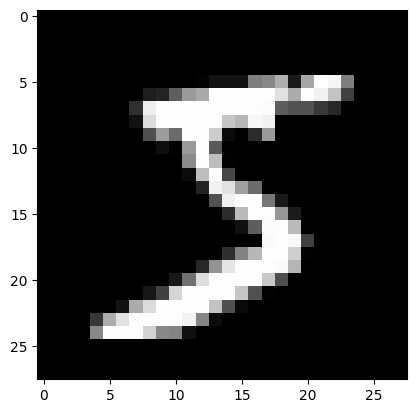

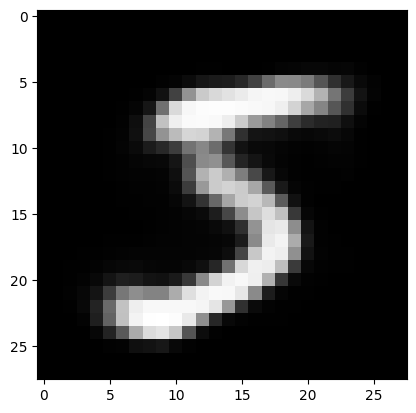

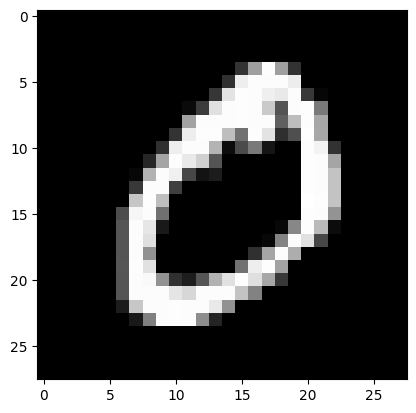

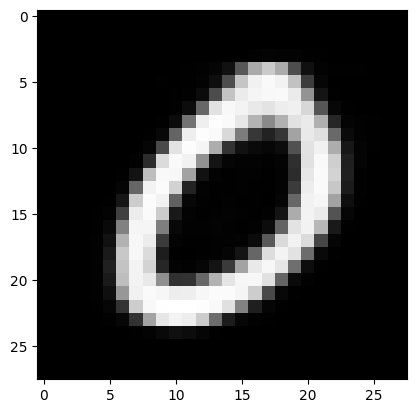

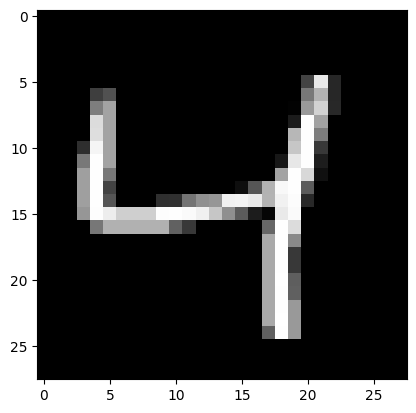

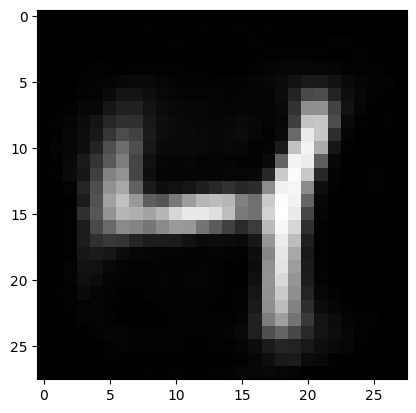

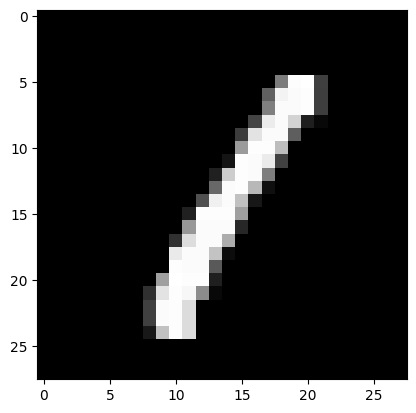

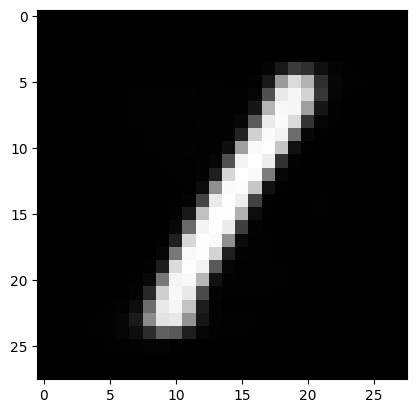

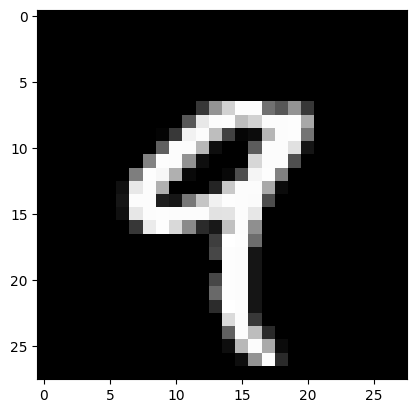

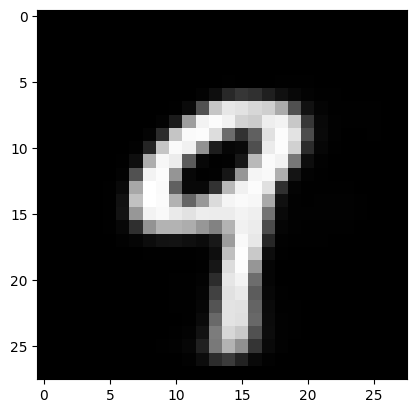

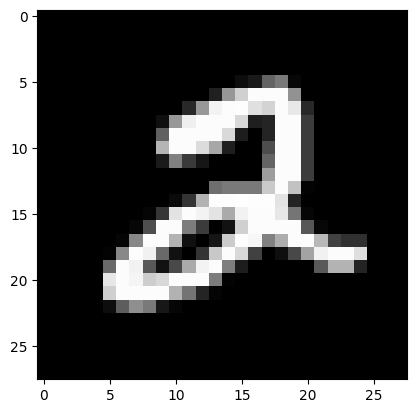

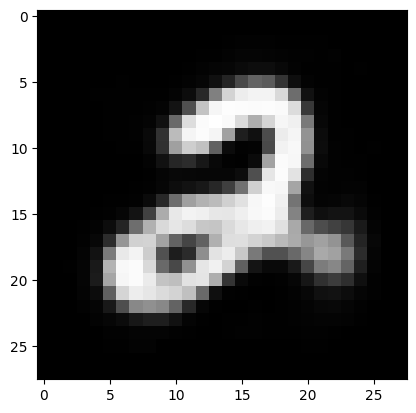

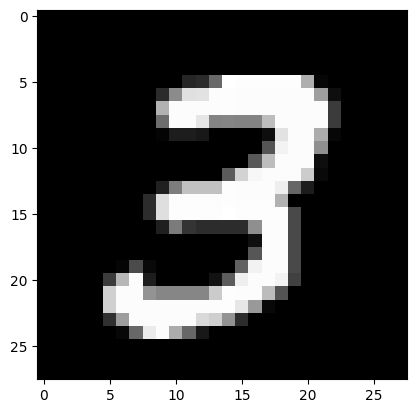

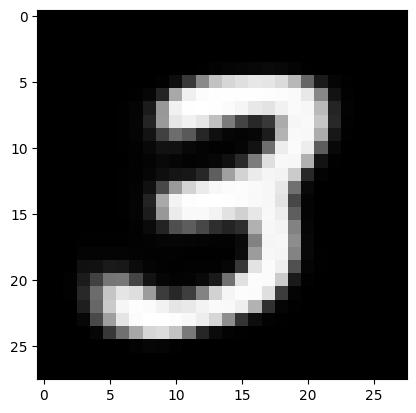

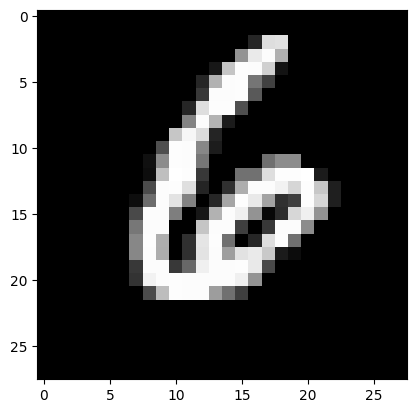

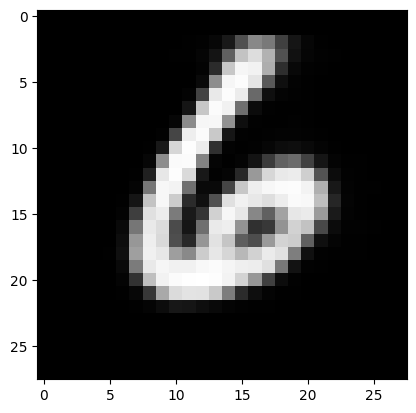

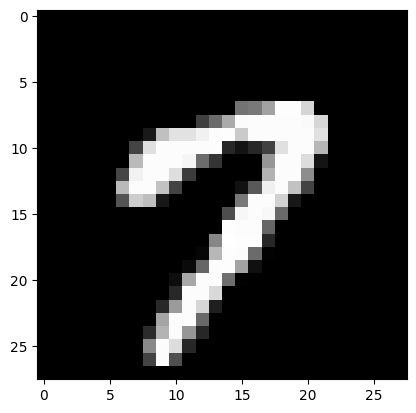

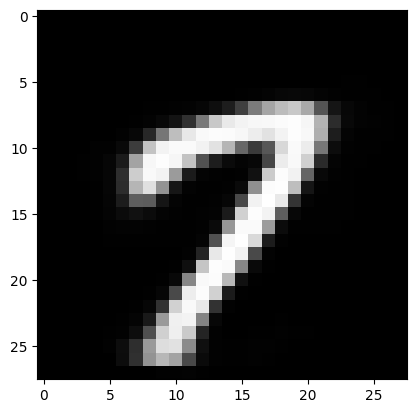

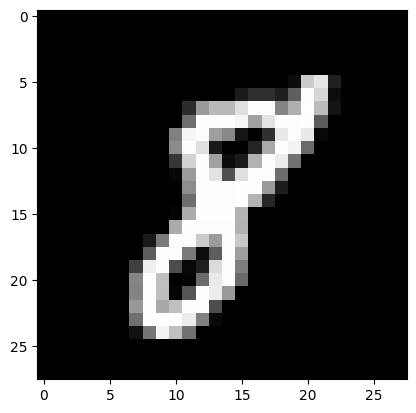

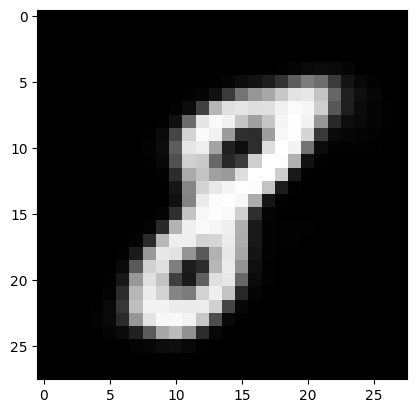

In [54]:
model.load_state_dict(torch.load("./models/" + activation_func + "/pre3", weights_only = True))
model.eval()

for digit in examples:

	image_tensor = examples[digit]
	image = tensor_to_img(image_tensor)
	imgplot = plt.imshow(image, cmap = "gray")
	plt.show()

	with torch.no_grad():
		image_tensor = torch.flatten(image_tensor).to(device)

		e1 = model.encoder_layer_1(image_tensor)
		e2 = model.encoder_layer_2(e1)
		e3 = model.encoder_layer_3(e2)

		e3_reconstructed = model.decoder_layer_3(e3)
		e2_reconstructed = model.decoder_layer_2(e3_reconstructed)
		e1_reconstructed = model.decoder_layer_1(e2_reconstructed)

	e1_reconstructed = torch.unflatten(e1_reconstructed, dim = 0, sizes = (28, 28)).to(device)

	image_reconstructed = tensor_to_img(e1_reconstructed)

	imgplot = plt.imshow(image_reconstructed, cmap = "gray")
	plt.show()

#### Autoencoder Layer 4


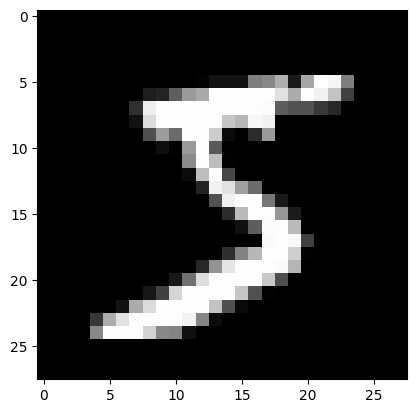

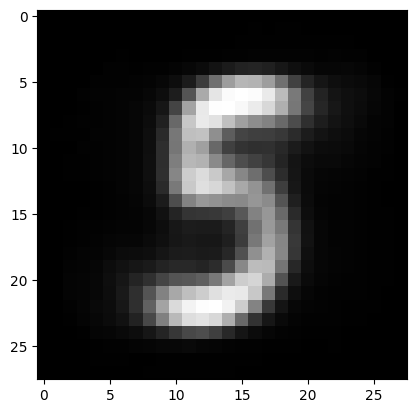

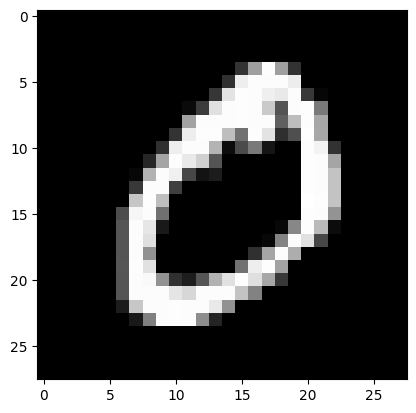

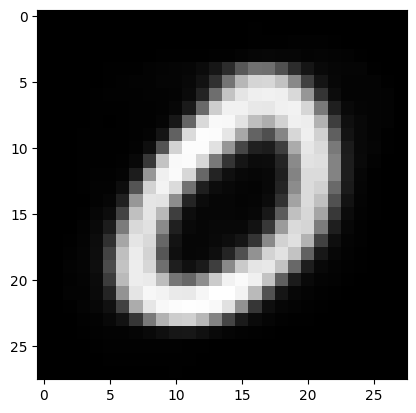

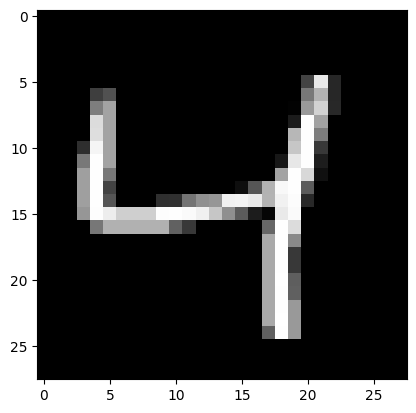

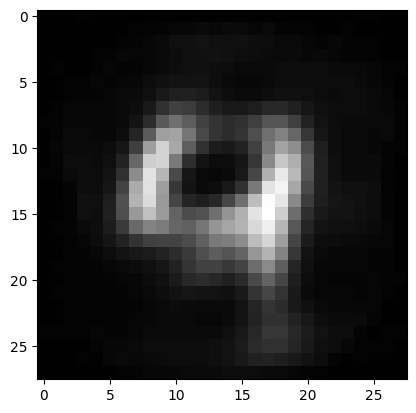

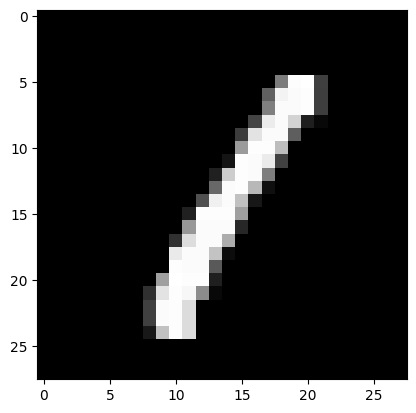

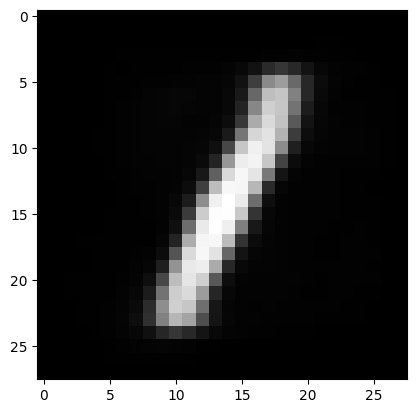

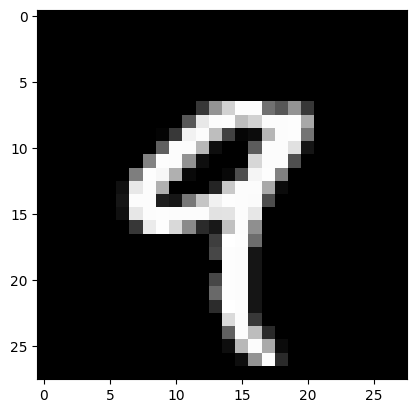

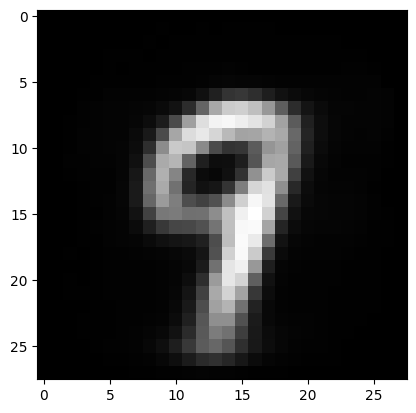

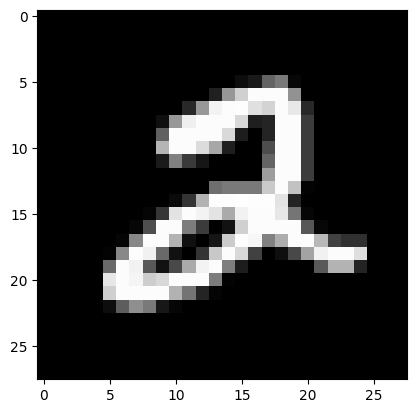

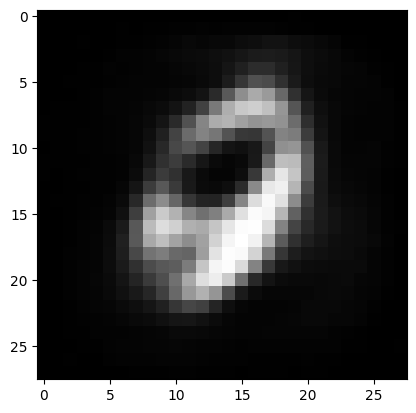

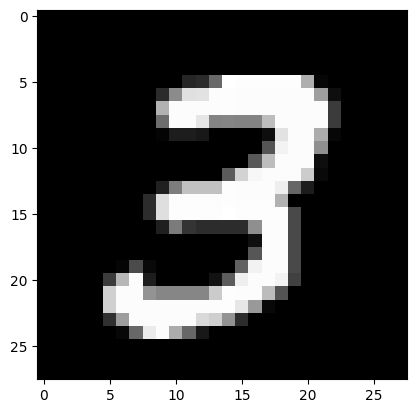

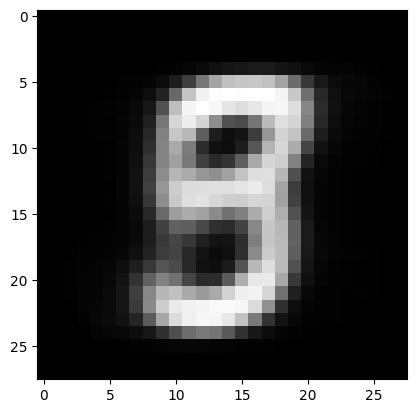

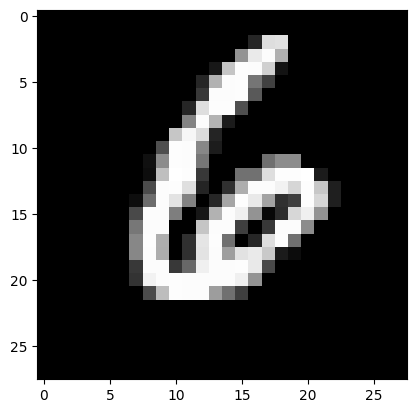

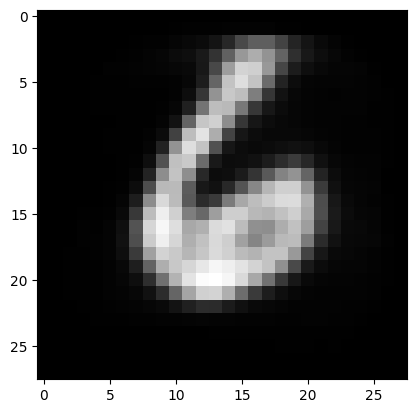

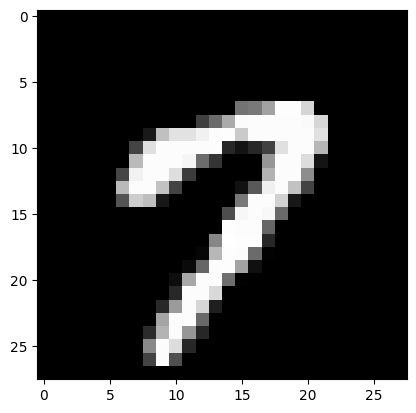

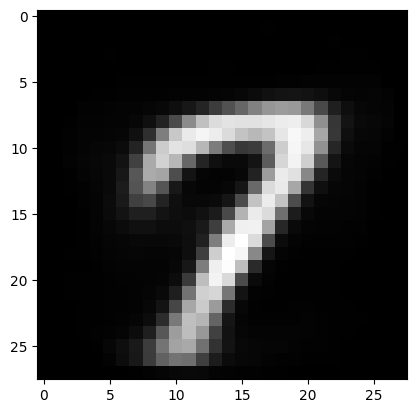

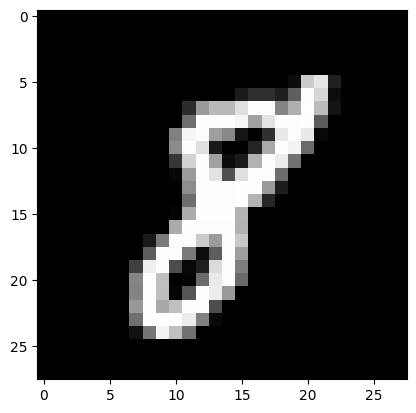

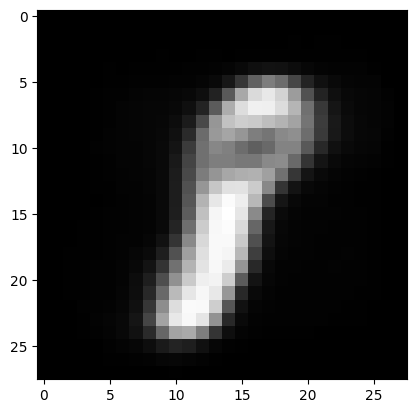

In [55]:
model.load_state_dict(torch.load("./models/" + activation_func + "/pre4", weights_only = True))
model.eval()

for digit in examples:

	image_tensor = examples[digit]
	image = tensor_to_img(image_tensor)
	imgplot = plt.imshow(image, cmap = "gray")
	plt.show()

	with torch.no_grad():
		image_tensor = torch.flatten(image_tensor).to(device)

		e1 = model.encoder_layer_1(image_tensor)
		e2 = model.encoder_layer_2(e1)
		e3 = model.encoder_layer_3(e2)
		e4 = model.encoder_layer_4(e3)

		e4_reconstructed = model.decoder_layer_4(e4)
		e3_reconstructed = model.decoder_layer_3(e4_reconstructed)
		e2_reconstructed = model.decoder_layer_2(e3_reconstructed)
		e1_reconstructed = model.decoder_layer_1(e2_reconstructed)

	e1_reconstructed = torch.unflatten(e1_reconstructed, dim = 0, sizes = (28, 28)).to(device)

	image_reconstructed = tensor_to_img(e1_reconstructed)

	imgplot = plt.imshow(image_reconstructed, cmap = "gray")
	plt.show()

#### Finetuned

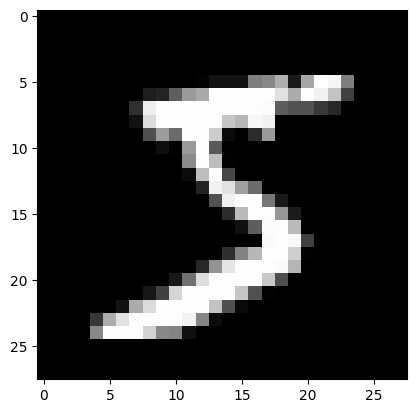

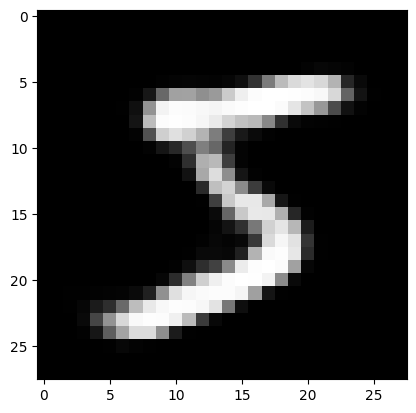

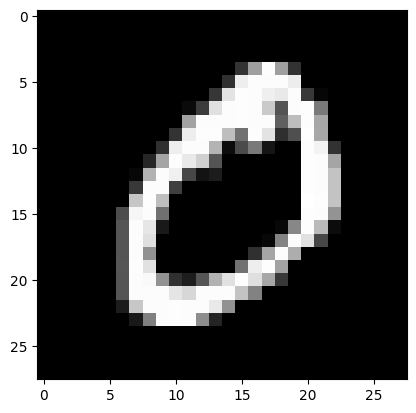

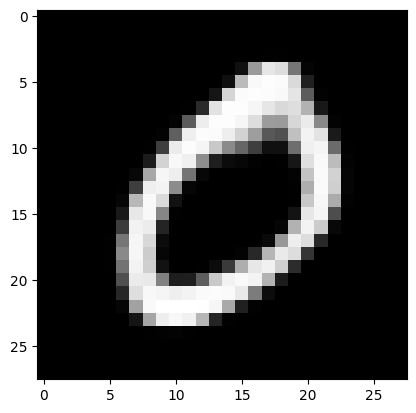

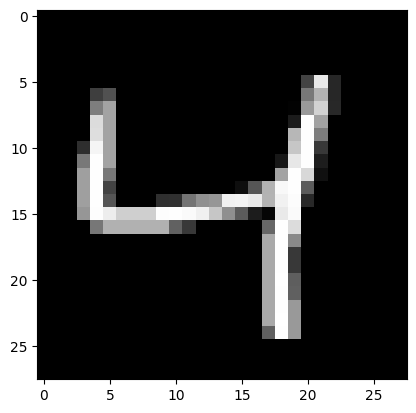

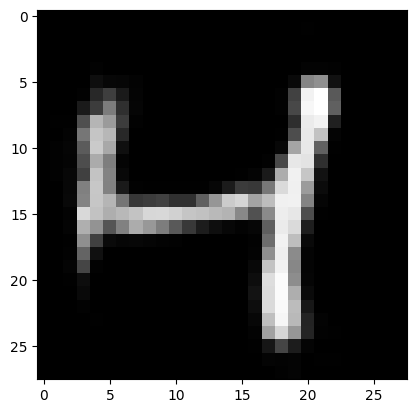

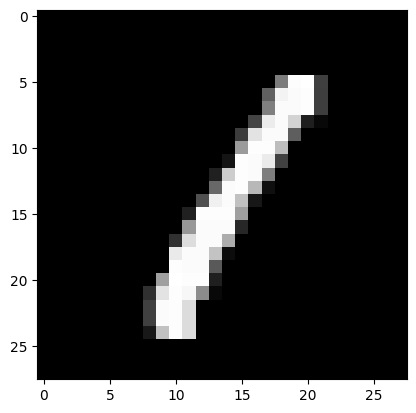

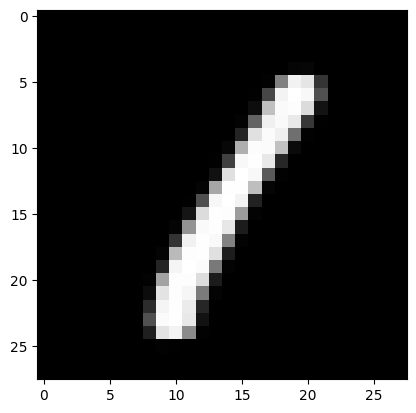

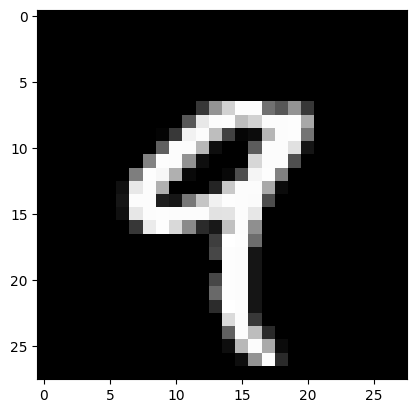

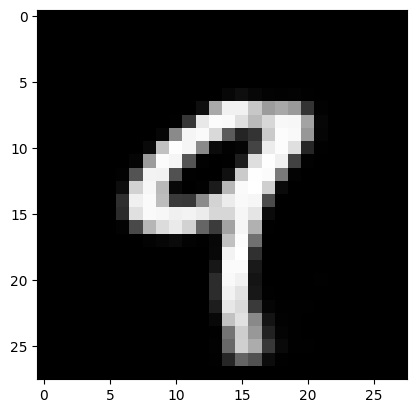

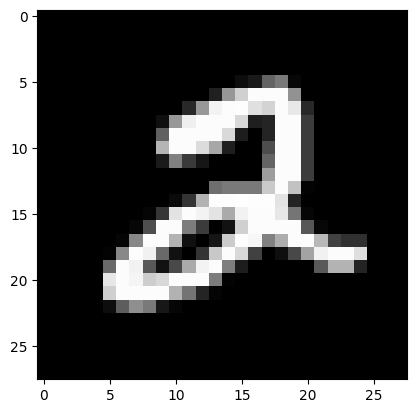

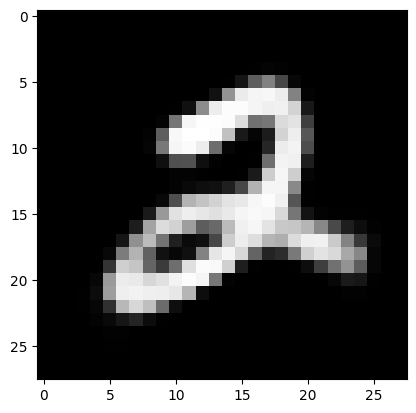

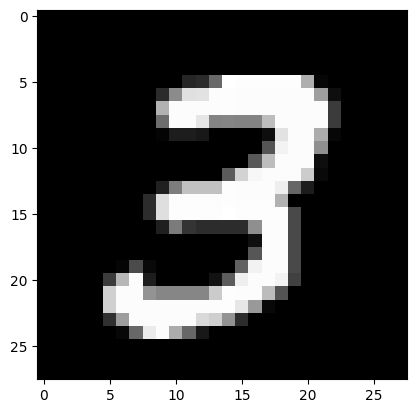

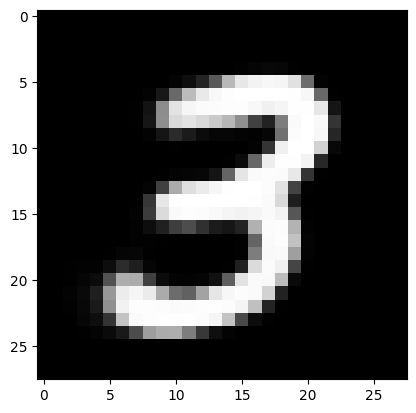

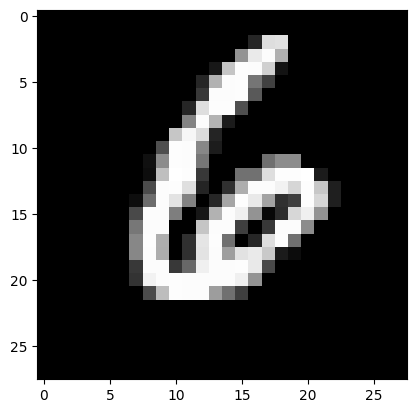

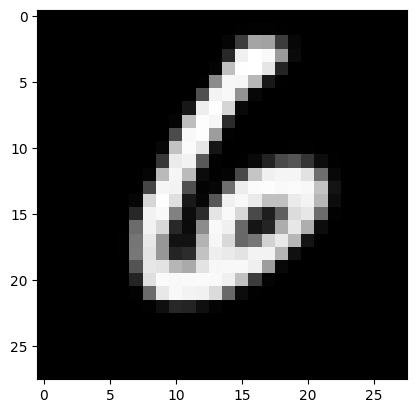

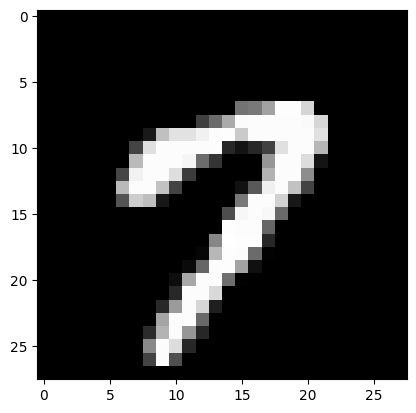

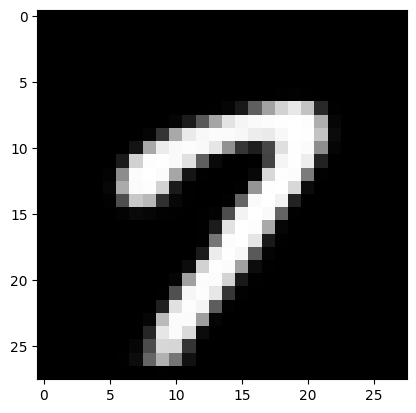

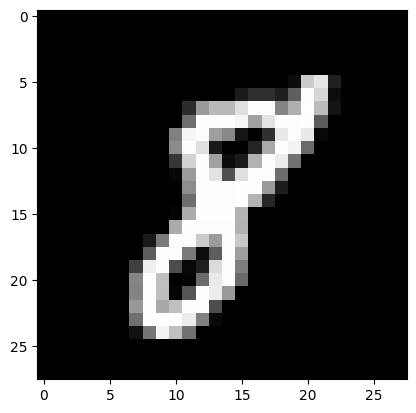

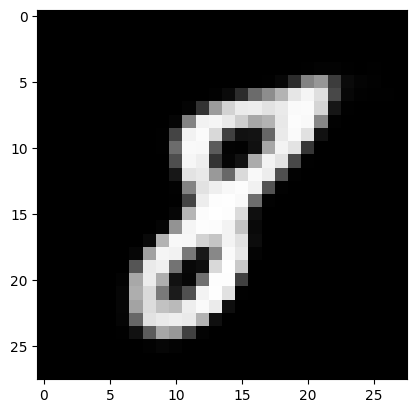

In [56]:
model.load_state_dict(torch.load("./models/" + activation_func + "/finetuned", weights_only = True))
model.eval()

for digit in examples:

	image_tensor = examples[digit]
	image = tensor_to_img(image_tensor)
	imgplot = plt.imshow(image, cmap = "gray")
	plt.show()

	with torch.no_grad():
		image_tensor = torch.flatten(image_tensor).to(device)
		reconstructed = model(image_tensor)

	reconstructed = torch.unflatten(reconstructed, dim = 0, sizes = (28, 28)).to(device)

	image_reconstructed = tensor_to_img(reconstructed)

	imgplot = plt.imshow(image_reconstructed, cmap = "gray")
	plt.show()

### Clustering

In [57]:
model = SAE()
model.to(device)

model.load_state_dict(
    torch.load("./models/" + activation_func + "/finetuned", weights_only = True)
)

model.eval()

all_z = []
all_labels = []

model.eval()

with torch.no_grad():
    for images, labels in dataloader:
        images = torch.flatten(images, start_dim = 1).to(device)

        z = model.encode(images)

        all_z.append(z.cpu().numpy())
        all_labels.append(labels.numpy())

Z = np.concatenate(all_z, axis = 0)
y_true = np.concatenate(all_labels, axis = 0)

print(Z.shape)
print(y_true.shape)

(70000, 20)
(70000,)


In [58]:
from sklearn.cluster import KMeans

n_clusters = 10

kmeans = KMeans(
    n_clusters = n_clusters,
    n_init = 20,
    random_state = 42
)

cluster_labels = kmeans.fit_predict(Z)

centroids = kmeans.cluster_centers_

print(cluster_labels.shape)
print(centroids.shape)

(70000,)
(10, 20)


In [59]:
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

ari = adjusted_rand_score(y_true, cluster_labels)
nmi = normalized_mutual_info_score(y_true, cluster_labels)

print(f"ARI: {ari:.4f}")
print(f"NMI: {nmi:.4f}")

ARI: 0.4708
NMI: 0.5672


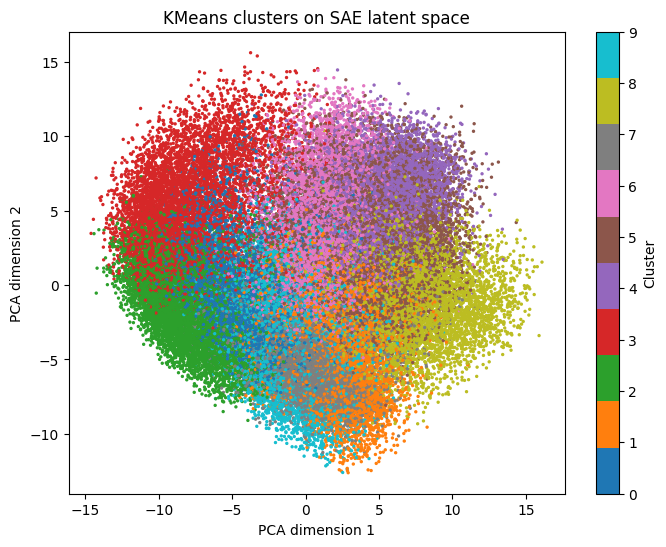

In [ ]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components = 2, random_state = 42)
Z_2d = pca.fit_transform(Z)

plt.figure(figsize = (8, 6))
plt.scatter(
    Z_2d[:, 0],
    Z_2d[:, 1],
    c = cluster_labels,
    s = 2,
    cmap = "tab10"
)
plt.title("KMeans clusters on SAE latent space")
plt.xlabel("PCA dimension 1")
plt.ylabel("PCA dimension 2")
plt.colorbar(label = "Cluster")
plt.show()

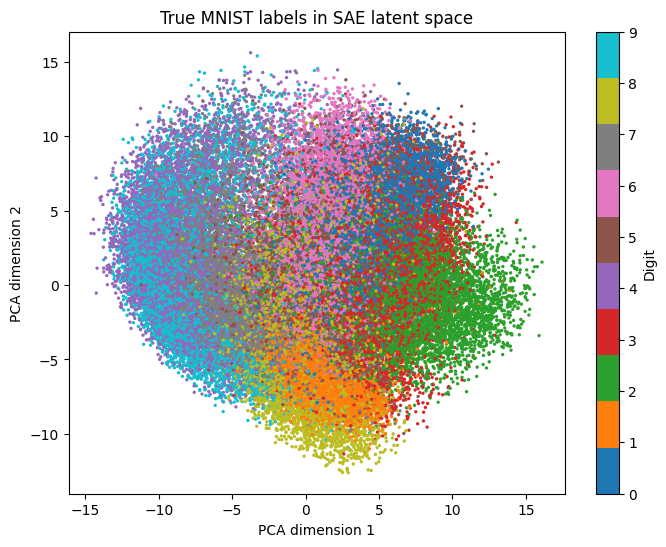

In [ ]:
plt.figure(figsize = (8, 6))
plt.scatter(
    Z_2d[:, 0],
    Z_2d[:, 1],
    c = y_true,
    s = 2,
    cmap = "tab10"
)
plt.title("True MNIST labels in SAE latent space")
plt.xlabel("PCA dimension 1")
plt.ylabel("PCA dimension 2")
plt.colorbar(label = "Digit")
plt.show()

In [ ]:
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import numpy as np

tsne = TSNE(
    n_components = 2,
    perplexity = 30,
    learning_rate = "auto",
    init = "pca",
    random_state = 42
)

Z_tsne = tsne.fit_transform(Z)

print(Z_tsne.shape)

(70000, 2)


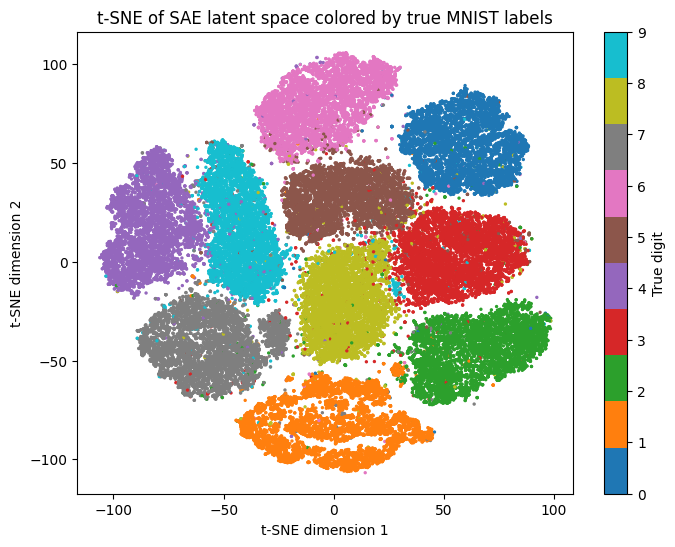

In [ ]:
plt.figure(figsize = (8, 6))
plt.scatter(
    Z_tsne[:, 0],
    Z_tsne[:, 1],
    c = y_true,
    s = 2,
    cmap = "tab10"
)
plt.title("t-SNE of SAE latent space colored by true MNIST labels")
plt.xlabel("t-SNE dimension 1")
plt.ylabel("t-SNE dimension 2")
plt.colorbar(label = "True digit")
plt.show()

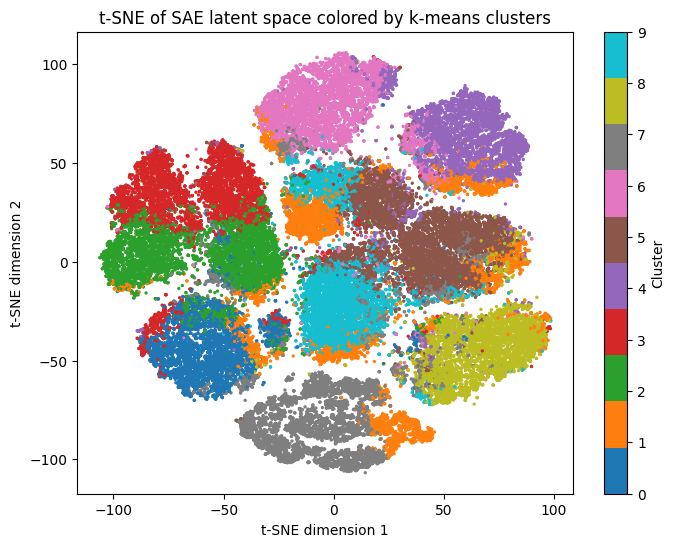

In [ ]:
plt.figure(figsize = (8, 6))
plt.scatter(
    Z_tsne[:, 0],
    Z_tsne[:, 1],
    c = cluster_labels,
    s = 2,
    cmap = "tab10"
)
plt.title("t-SNE of SAE latent space colored by k-means clusters")
plt.xlabel("t-SNE dimension 1")
plt.ylabel("t-SNE dimension 2")
plt.colorbar(label = "Cluster")
plt.show()

In [65]:
from scipy.optimize import linear_sum_assignment
from sklearn.metrics import confusion_matrix
import numpy as np

def clustering_accuracy(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    row_ind, col_ind = linear_sum_assignment(-cm)
    return cm[row_ind, col_ind].sum() / y_true.size

acc = clustering_accuracy(y_true, cluster_labels)

print(f"Clustering Accuracy: {acc:.4f}")

Clustering Accuracy: 0.6504


In [ ]:
import pandas as pd

cluster_digit_counts = pd.crosstab(
    pd.Series(cluster_labels, name = "Cluster"),
    pd.Series(y_true, name = "True digit")
)

cluster_digit_counts

True digit,0,1,2,3,4,5,6,7,8,9
Cluster,,,,,,,,,,
0,4,2,146,53,8,14,3,4932,27,219
1,925,1389,289,794,147,1889,243,527,718,298
2,6,9,66,16,3447,54,9,598,88,3167
3,5,2,54,48,3036,113,15,687,95,2821
4,5087,0,127,103,21,234,404,39,75,48
5,58,22,145,5075,4,2271,8,10,884,102
6,727,14,96,17,46,138,5789,1,55,6
7,51,6391,359,458,95,69,304,426,302,248
8,2,41,5537,244,17,2,4,59,18,12


In [ ]:
cluster_digit_percentages = cluster_digit_counts.div(
    cluster_digit_counts.sum(axis = 1),
    axis = 0
)

cluster_digit_percentages.round(2)

True digit,0,1,2,3,4,5,6,7,8,9
Cluster,,,,,,,,,,
0,0.00,0.00,0.03,0.01,0.00,0.00,0.00,0.91,0.00,0.04
1,0.13,0.19,0.04,0.11,0.02,0.26,0.03,0.07,0.10,0.04
2,0.00,0.00,0.01,0.00,0.46,0.01,0.00,0.08,0.01,0.42
3,0.00,0.00,0.01,0.01,0.44,0.02,0.00,0.10,0.01,0.41
4,0.83,0.00,0.02,0.02,0.00,0.04,0.07,0.01,0.01,0.01
5,0.01,0.00,0.02,0.59,0.00,0.26,0.00,0.00,0.10,0.01
6,0.11,0.00,0.01,0.00,0.01,0.02,0.84,0.00,0.01,0.00
7,0.01,0.73,0.04,0.05,0.01,0.01,0.03,0.05,0.03,0.03
8,0.00,0.01,0.93,0.04,0.00,0.00,0.00,0.01,0.00,0.00
